## Bunch-dependence corrections: clean first version
**Question:** can the average bunch-position correction $C_b$ be explained by detector response to electrons detected in preceding bunches?

This notebook uses the existing **150°C, 275.0 eV** dataset and the essential independent-region comparison from `Bunch investigations.ipynb` (the available source confirmed in chat). Learn corrections on **190–220 eV**; evaluate on **220–260 eV** with five train-wise folds. All helpers are in one cell. Execution is directly in the notebook, with no helper files or Slurm requirement.

## 1. Setup and data loading
Preserve the existing data paths, calibration, GMD bands and independent-comparison settings. `MAX_TRAINS=None` uses all trains; a small integer gives an explicitly limited preview.

In [ ]:
# Existing environment, paths, calibration and plotting style.
import os
import sys
import json
from pathlib import Path
import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from IPython.display import display

os.environ.setdefault("FLASH_ENV", "remote")
repo_root = next((p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
                  if (p / "analysis" / "scripts").exists()), None)
if repo_root is None:
    raise RuntimeError("Open this notebook from within the glycine26 repository.")
scripts_dir = repo_root / "analysis" / "scripts"
if str(scripts_dir) not in sys.path:
    sys.path.insert(0, str(scripts_dir))
import config
AGG_DIR = Path(config.COMBINED_DIR)
CALIB_PATH = AGG_DIR.parent / "Calibrations" / "etof_energy_calibration_t0_scan.json"
with open(CALIB_PATH, "r", encoding="utf-8") as handle:
    calib = json.load(handle)
best_t0 = calib["t0_tof_units"]
best_slope = calib["slope_eV_tof_unit2"]
best_E0 = calib["E0_eV"]

AGG_FILENAMES = [

    "glycine_delay_scan_150C_long_271.0eV_aggregates_tr_etof1.h5",
    "glycine_delay_scan_150C_long_271.5eV_aggregates_tr_etof1.h5",
    "glycine_delay_scan_150C_long_272.0eV_aggregates_tr_etof1.h5",
    "glycine_delay_scan_150C_272.5eV_aggregates_tr_etof1.h5",
    "glycine_delay_scan_150C_273.0eV_aggregates_tr_etof1.h5",
    "glycine_delay_scan_150C_273.5eV_aggregates_tr_etof1.h5",
    "glycine_delay_scan_150C_274.0eV_aggregates_tr_etof1.h5",
    "glycine_delay_scan_150C_274.5eV_aggregates_tr_etof1.h5",
    "glycine_delay_scan_150C_275.0eV_aggregates_tr_etof1.h5",   ]


ANALYSIS_PHOTON_ENERGY_EV = 275.0
INDEP_REF_KE_RANGE = BUNCH_REF_KE_RANGE = (190.0, 220.0)
INDEP_TARGET_KE_RANGE = (220.0, 260.0)
INDEP_GMD_RANGE = (1.0, 12.0)
INDEP_GMD_BANDS = LAG_GMD_BANDS = [
    (1.0, 2.0), (3.0, 4.0), (5.0, 6.0), (6.0, 8.0), (8.0, 12.0)]
INDEP_BUNCH_START = COMPARE_BUNCH_START = 10
INDEP_CV_MOD = 5
INDEP_CV_OFFSETS = np.arange(INDEP_CV_MOD)
INDEP_CHUNK_TRAINS = 250
INDEP_MODELS = ["M0", "M5", "M10", "E2", "E3"]
MAX_TRAINS = None  # e.g. 2000 for a preview; tiny subsets may lack Cb reference counts.
ELECTRON_TAU_INITIAL = 3.0
ELECTRON_TAU_BOUNDS = (0.25, 50.0)  # Explicit numerical fit bounds, in bunch spacings.
plt.rcParams.update({"figure.dpi":110, "savefig.dpi":200, "font.size":14,
                     "axes.labelsize":16, "axes.titlesize":18,
                     "xtick.labelsize":14, "ytick.labelsize":14, "legend.fontsize":12})
print("Combined:", AGG_DIR)
print("Calibration:", CALIB_PATH)

Combined: /asap3/flash/gpfs/fl24/2026/data/11022188/processed/combined
Calibration: /asap3/flash/gpfs/fl24/2026/data/11022188/processed/Calibrations/etof_energy_calibration_t0_scan.json


In [ ]:


# Existing helpers copied from Bunch investigations.ipynb.

def tof_to_ke(tof):
    tof = np.asarray(tof, dtype=float)
    with np.errstate(divide="ignore", invalid="ignore"):
        ke = best_slope / (tof - best_t0) ** 2 + best_E0
    return np.where(tof > best_t0, ke, np.nan)

def load_aggregate_info(path):
    path = Path(path)
    with h5py.File(path, "r") as handle:
        metadata = {}
        for key in handle.attrs:
            value = handle.attrs[key]
            if isinstance(value, bytes):
                value = value.decode()
            elif isinstance(value, np.ndarray):
                value = value.tolist()
            metadata[key] = value

        info = {
            "path": path,
            "metadata": metadata,
            "tof_edges": handle["tof_edges"][:],
            "gmd_edges": handle["gmd_edges"][:],
            "n_per_bin": handle["n_per_bin"][:],
            "G": handle["G"][:],
            "D_shape": handle["D"].shape if "D" in handle else None,
            "z_edges": handle["z_edges"][:] if "z_edges" in handle else None,
        }

    return info

def electron_counts_ref_target(tofs_e):
    """
    Count electrons per shot in the independent Cb reference region
    and in the target region using one TOF -> KE conversion.
    """
    valid = tofs_e > 0
    shape = tofs_e.shape[:2]

    ref = np.zeros(shape, dtype=np.int32)
    target = np.zeros(shape, dtype=np.int32)

    if not np.any(valid):
        return ref, target

    ke = tof_to_ke(tofs_e[valid])
    flat_index = np.flatnonzero(valid) // tofs_e.shape[-1]

    in_ref = (ke >= INDEP_REF_KE_RANGE[0]) & (ke < INDEP_REF_KE_RANGE[1])
    in_target = (ke >= INDEP_TARGET_KE_RANGE[0]) & (ke < INDEP_TARGET_KE_RANGE[1])

    ref.flat[:] = np.bincount(flat_index[in_ref], minlength=np.prod(shape))
    target.flat[:] = np.bincount(flat_index[in_target], minlength=np.prod(shape))

    return ref, target

def preceding_gmd_mean(gmd, width):
    n_trains, n_bunch = gmd.shape
    out = np.full_like(gmd, np.nan, dtype=float)
    g0 = np.nan_to_num(gmd, nan=0.0)
    cs = np.concatenate((np.zeros((n_trains, 1)), np.cumsum(g0, axis=1)), axis=1)
    fc = np.concatenate((np.zeros((n_trains, 1), dtype=int), np.cumsum(np.isfinite(gmd), axis=1)), axis=1)
    sums = cs[:, width:n_bunch] - cs[:, :n_bunch-width]
    good = fc[:, width:n_bunch] - fc[:, :n_bunch-width]
    out[:, width:] = sums / width
    out[:, width:][good != width] = np.nan
    return out

def build_compare_cb(sum_e, sum_gmd, sum_shots, bunch_start=COMPARE_BUNCH_START):
    """
    Learn Cb from training data only.

    For every bunch position:
      1. electron/GMD response is formed within each GMD band,
      2. each band is normalised by its mean response,
      3. the relative responses are combined using shot-count weights.
    """
    response = np.divide(sum_e, sum_gmd, out=np.full_like(sum_e, np.nan, dtype=float), where=sum_gmd > 0)

    band_mean = np.divide(
        np.sum(sum_e[:, bunch_start:], axis=1),
        np.sum(sum_gmd[:, bunch_start:], axis=1),
        out=np.full(sum_e.shape[0], np.nan, dtype=float),
        where=np.sum(sum_gmd[:, bunch_start:], axis=1) > 0,
    )

    relative = response / band_mean[:, None]

    valid = np.isfinite(relative) & (sum_shots > 0)
    weights = np.where(valid, sum_shots, 0.0)

    factor = np.divide(
        np.sum(np.where(valid, relative * weights, 0.0), axis=0),
        np.sum(weights, axis=0),
        out=np.full(sum_e.shape[1], np.nan, dtype=float),
        where=np.sum(weights, axis=0) > 0,
    )

    # Mean Cb = 1 over exactly the comparison bunch range.
    bunch_weights = np.sum(sum_shots[:, bunch_start:], axis=0)
    factor_range = factor[bunch_start:]

    good = np.isfinite(factor_range) & (bunch_weights > 0)

    factor /= np.average(factor_range[good], weights=bunch_weights[good])

    return factor

def compare_relative_response(obs, norm, bunch_start=COMPARE_BUNCH_START):
    """
    Relative bunch response for each GMD band.

    obs / norm is divided by its band-average value over the comparison
    bunch range, so every method is judged only on residual bunch-position
    structure rather than on an overall scale factor.
    """
    response = np.divide(obs, norm, out=np.full_like(obs, np.nan, dtype=float), where=norm > 0)

    band_scale = np.divide(
        np.sum(obs[:, bunch_start:], axis=1),
        np.sum(norm[:, bunch_start:], axis=1),
        out=np.full(obs.shape[0], np.nan, dtype=float),
        where=np.sum(norm[:, bunch_start:], axis=1) > 0,
    )

    return response / band_scale[:, None]

def compare_flatness(relative_response, shots, bunch_start=COMPARE_BUNCH_START):
    """Shot-weighted RMS distance of the relative response from one."""
    r = relative_response[:, bunch_start:]
    w = shots[:, bunch_start:]

    valid = np.isfinite(r) & (w > 0)

    return np.sqrt(np.sum(w[valid] * (r[valid] - 1.0) ** 2) / np.sum(w[valid]))

def weighted_bunch_line(y, weights, start=0):
    """Weighted linear fit y = m*x + c."""
    x = np.arange(y.size, dtype=float)
    valid = (x >= start) & np.isfinite(y) & np.isfinite(weights) & (weights > 0)
    x_fit, y_fit, w_fit = x[valid], y[valid], weights[valid]

    x0 = np.average(x_fit, weights=w_fit)
    y0 = np.average(y_fit, weights=w_fit)
    slope = np.sum(w_fit * (x_fit - x0) * (y_fit - y0)) / np.sum(w_fit * (x_fit - x0)**2)
    intercept = y0 - slope * x0
    return slope, intercept


# The exponential helper is called but undefined in the source notebook.
def preceding_gmd_exponential(gmd, tau):
    """Exponential mean of earlier finite GMD values, reset at each train."""
    q = np.exp(-1 / tau)
    numerator, denominator = np.zeros(gmd.shape[0]), np.zeros(gmd.shape[0])
    out = np.full_like(gmd, np.nan, dtype=float)
    for i in range(1, gmd.shape[1]):
        finite = np.isfinite(gmd[:, i - 1])
        numerator = q * (numerator + np.where(finite, gmd[:, i - 1], 0.0))
        denominator = q * (denominator + finite)
        out[:, i] = np.divide(numerator, denominator,
                             out=np.full(gmd.shape[0], np.nan), where=denominator > 0)
    return out


def electron_history(total_electrons, tau):
    """H_i = sum_{d>=1} N_e(i-d) exp(-d/tau); H_0=0 independently in every train."""
    q = np.exp(-1 / tau)
    history = np.zeros(total_electrons.shape, dtype=float)
    for i in range(1, total_electrons.shape[1]):
        history[:, i] = q * (history[:, i - 1] + total_electrons[:, i - 1])
    return history


def load_compact_shots(source_h5, max_trains=None):
    """Chunk HDF5 TOFs; keep only GMD and compact train x bunch count matrices."""
    with h5py.File(source_h5, "r") as handle:
        n_trains, n_bunch = handle["gmd"].shape
        if max_trains is not None:
            n_trains = min(n_trains, int(max_trains))
        if n_trains < INDEP_CV_MOD or n_bunch <= INDEP_BUNCH_START:
            raise ValueError("Too few trains/bunches for this comparison.")
        dtype = np.uint16 if handle["tofs_e"].shape[-1] <= 65535 else np.uint32
        gmd = np.empty((n_trains, n_bunch), dtype=float)
        ref_counts = np.empty(gmd.shape, dtype=dtype)
        target_counts, total_electrons = np.empty_like(ref_counts), np.empty_like(ref_counts)
        full_slots = 0
        for start in range(0, n_trains, INDEP_CHUNK_TRAINS):
            stop = min(start + INDEP_CHUNK_TRAINS, n_trains)
            gmd[start:stop] = handle["gmd"][start:stop]
            tofs_e = handle["tofs_e"][start:stop]
            ref_counts[start:stop], target_counts[start:stop] = electron_counts_ref_target(tofs_e)
            # Total load includes hits outside KE windows, even on unselected GMD shots.
            total_electrons[start:stop] = np.count_nonzero(np.isfinite(tofs_e) & (tofs_e > 0), axis=-1)
            full_slots += np.count_nonzero(total_electrons[start:stop] == tofs_e.shape[-1])
    data = dict(gmd=gmd, ref_counts=ref_counts, target_counts=target_counts,
                total_electrons=total_electrons, train_ids=np.arange(n_trains))
    print(f"Compact arrays: {sum(a.nbytes for a in data.values())/2**20:.1f} MiB; "
          f"shots with all hit slots occupied: {full_slots:,}")
    return data


def history_designs(gmd):
    mean5, mean10 = preceding_gmd_mean(gmd, 5), preceding_gmd_mean(gmd, 10)
    exp2, exp3 = preceding_gmd_exponential(gmd, 2), preceding_gmd_exponential(gmd, 3)
    common = ((np.arange(gmd.shape[1]) >= INDEP_BUNCH_START)[None, :]
              & np.isfinite(gmd) & np.isfinite(mean5) & np.isfinite(mean10)
              & np.isfinite(exp2) & np.isfinite(exp3)
              & (gmd >= INDEP_GMD_RANGE[0]) & (gmd < INDEP_GMD_RANGE[1]))
    X = {"M0": np.stack((np.ones_like(gmd), gmd), axis=-1)}
    for name, h in [("M5", mean5), ("M10", mean10), ("E2", exp2), ("E3", exp3)]:
        X[name] = np.stack((np.ones_like(gmd), gmd, h), axis=-1)
    return X, common


def band_sums(values, gmd, selected):
    return np.array([np.sum(np.where(selected & (gmd >= lo) & (gmd < hi), values, 0.0), axis=0)
                     for lo, hi in INDEP_GMD_BANDS])


def bunch_metrics(obs, norm, shots):
    relative = compare_relative_response(obs, norm, bunch_start=INDEP_BUNCH_START)
    lines = np.array([weighted_bunch_line(r, w, INDEP_BUNCH_START)
                      if np.count_nonzero((w > 0) & np.isfinite(r)) >= 2 else (np.nan, np.nan)
                      for r, w in zip(relative, shots)])
    weights = shots[:, INDEP_BUNCH_START:].sum(axis=1)
    valid = (weights > 0) & np.isfinite(lines[:, 0])
    slope = 1000 * np.average(lines[valid, 0], weights=weights[valid]) if valid.any() else np.nan
    return dict(relative=relative, lines=lines, slope=slope,
                flatness=compare_flatness(relative, shots, bunch_start=INDEP_BUNCH_START))


def plot_bunch_response(metrics, title, ax):
    bunch = np.arange(metrics["relative"].shape[1])
    for j, (lo, hi) in enumerate(INDEP_GMD_BANDS):
        line, = ax.plot(bunch, metrics["relative"][j], ".-", ms=3, lw=1, label=f"{lo:g}-{hi:g} uJ")
        m, c = metrics["lines"][j]
        ax.plot(bunch, m * bunch + c, "--", lw=1, color=line.get_color())
    ax.axhline(1, ls=":", lw=1)
    ax.set_xlim(INDEP_BUNCH_START, bunch[-1])
    ax.set_xlabel("bunch index in train")
    ax.set_ylabel("relative response")
    ax.set_title(title)
    ax.grid(alpha=0.25)


def fit_electron_response(gmd, ref_counts, total_electrons, selected):
    """Training-reference least squares; jointly fit signed a0 and continuous tau.

    Profile over the two nonnegative endpoints of a+b*GMD in the selected GMD range.
    Only training-train arrays are passed, including their full earlier hit histories.
    """
    g, y = gmd[selected], ref_counts[selected].astype(float)
    if y.size == 0 or not np.any(y > 0):
        raise ValueError("No training reference signal.")
    lo, hi = INDEP_GMD_RANGE
    u, v = (hi - g)/(hi - lo), (g - lo)/(hi - lo)
    scale = max(float(np.mean(total_electrons)) * ELECTRON_TAU_INITIAL, 1.0)
    y2 = float(y @ y)

    def objective(parameters, return_fit=False):
        gamma, log_tau = parameters
        h = electron_history(total_electrons, np.exp(log_tau))[selected]
        R = np.exp(-(gamma / scale) * h)
        x0, x1 = u * R, v * R
        A = np.array([[x0 @ x0, x0 @ x1], [x0 @ x1, x1 @ x1]])
        z = np.array([x0 @ y, x1 @ y])
        beta = np.linalg.lstsq(A, z, rcond=None)[0]
        candidates = [np.array([max(z[0]/A[0,0], 0) if A[0,0] > 0 else 0, 0]),
                      np.array([0, max(z[1]/A[1,1], 0) if A[1,1] > 0 else 0])]
        if np.all(beta >= 0):
            candidates.append(beta)
        losses = [y2 - 2*c @ z + c @ A @ c for c in candidates]
        k = int(np.argmin(losses))
        mse = max(losses[k], 0.0) / y.size
        return (candidates[k], mse) if return_fit else mse

    result = minimize(objective, [0.05, np.log(ELECTRON_TAU_INITIAL)], method="L-BFGS-B",
                  bounds=[(None, None), tuple(np.log(ELECTRON_TAU_BOUNDS))],
                  options={"maxiter":100, "ftol":1e-10})
    if not result.success:
        raise RuntimeError(f"Electron-history fit did not converge: {result.message}")
    endpoints, mse = objective(result.x, return_fit=True)
    b = (endpoints[1] - endpoints[0])/(hi - lo)
    return dict(alpha=float(result.x[0]/scale), tau=float(np.exp(result.x[1])),
                a=float(endpoints[0] - b*lo), b=float(b), training_mse=float(mse))


def evaluate_held_out(data, designs, common, beta_cv, cb_folds, electron_fits, residual_cb_folds):
    """Identical target shots for all methods; never silently discard invalid predictions."""
    names = ["GMD", *INDEP_MODELS, "Cb", "Electron history", "Electron history + Cb"]
    shape = (INDEP_CV_MOD, len(INDEP_GMD_BANDS), data["gmd"].shape[1])
    hold_target, hold_shots = np.zeros(shape), np.zeros(shape)
    hold_norm = {name:np.zeros(shape) for name in names}
    for off in INDEP_CV_OFFSETS:
        rows = data["train_ids"] % INDEP_CV_MOD == off
        g, selected = data["gmd"][rows], common[rows]
        fit = electron_fits[off]
        R = np.exp(-fit["alpha"] * electron_history(data["total_electrons"][rows], fit["tau"]))
        norms = {"GMD":g, "Cb":g * cb_folds[off], "Electron history":g * R,
                 "Electron history + Cb":g * R * residual_cb_folds[off]}
        norms.update({name:designs[name][rows] @ beta_cv[name][off] for name in INDEP_MODELS})
        fold_shots = band_sums(np.ones_like(g), g, selected)
        for name, values in norms.items():
            # Existing linear models can have negative individual predictions;
            # their original normalisation uses sums, which must be positive.
            norm = band_sums(values, g, selected)
            supported = fold_shots > 0
            if np.any(~np.isfinite(norm[supported]) | (norm[supported] <= 0)):
                raise ValueError(f"{name}: invalid band/bunch normalisation. "
                                 "No held-out shots were dropped; a tiny preview may lack reference counts.")
            hold_norm[name][off] = norm
        hold_target[off] = band_sums(data["target_counts"][rows], g, selected)
        hold_shots[off] = fold_shots
    obs, shots = hold_target.sum(axis=0), hold_shots.sum(axis=0)
    combined = {name:bunch_metrics(obs, norm.sum(axis=0), shots) for name, norm in hold_norm.items()}
    folds = {name:[bunch_metrics(hold_target[off], norm[off], hold_shots[off])
                   for off in INDEP_CV_OFFSETS] for name, norm in hold_norm.items()}
    return combined, folds


In [ ]:
# Inspect source paths/shapes and load compact counts with bounded TOF reads.
diag_path = AGG_DIR / next(name for name in AGG_FILENAMES if f"_{ANALYSIS_PHOTON_ENERGY_EV:.1f}eV_" in name)
diag_agg = load_aggregate_info(diag_path)
input_h5 = diag_agg["metadata"].get("input_h5", "")
if not input_h5:
    raise ValueError("Aggregate has no input_h5 metadata; specify the source explicitly.")
source_h5 = Path(input_h5)
TRIM_START = int(diag_agg["metadata"].get("trim_start", 0))
TRIM_END = int(diag_agg["metadata"].get("trim_end", 0))
print("Aggregate:", diag_path)
print("Source:", source_h5)
print("Recorded aggregate trim_start/trim_end:", TRIM_START, TRIM_END)
with h5py.File(source_h5, "r") as handle:
    for key in ("gmd", "tofs_e", "tID", "z", "between_tdc_files"):
        print(key, handle[key].shape if key in handle else "absent")
print("Aggregate D:", diag_agg["D_shape"])
data = load_compact_shots(source_h5, max_trains=MAX_TRAINS)
gmd, train_ids = data["gmd"], data["train_ids"]
n_trains, n_bunch = gmd.shape
bunch = np.arange(n_bunch)
designs, common = history_designs(gmd)
print(f"Comparison: {n_trains:,} trains, bunches {INDEP_BUNCH_START}–{n_bunch-1}; "
      f"{np.count_nonzero(common):,} selected reference-fitting shots")
print("PREVIEW" if MAX_TRAINS is not None else "FULL DATA")

Aggregate: /asap3/flash/gpfs/fl24/2026/data/11022188/processed/combined/glycine_delay_scan_150C_275.0eV_aggregates_tr_etof1.h5
Source: /asap3/flash/gpfs/fl24/2026/data/11022188/processed/combined/glycine_delay_scan_150C_275.0eV.h5
Recorded aggregate trim_start/trim_end: 3 3
gmd (35439, 101)
tofs_e (35439, 101, 50)
tID (35439,)
z (35439, 101)
between_tdc_files (35439,)
Aggregate D: (4, 53, 5000)
Compact arrays: 48.1 MiB; shots with all hit slots occupied: 6
Comparison: 35,439 trains, bunches 10–100; 2,844,922 selected reference-fitting shots
FULL DATA


## 2. Baseline GMD-normalised bunch dependence
Use the existing ratio of sums, $\sum N_e/\sum\mathrm{GMD}$, divided by each band's overall ratio of sums. Flatness is the shot-weighted RMS distance from one. The summary slope is the shot-weighted mean of the band slopes, converted to **% per 10 bunches**; dashed fitted lines use shot weights.

All methods share the source's independent-comparison population: bunches ≥10, finite current GMD in 1–12 µJ, and finite M5/M10/E2/E3 histories. As in that comparison, raw train-row indices define folds (`index % 5`); no aggregate trimming or `between_tdc_files` cut is applied. The 2–3 µJ gap remains excluded from plotted bands and metrics but included in reference-model fitting. No delay cut, smoothing or interpolation is added.

GMD: flatness=0.24683, slope=-8.675% / 10 bunches


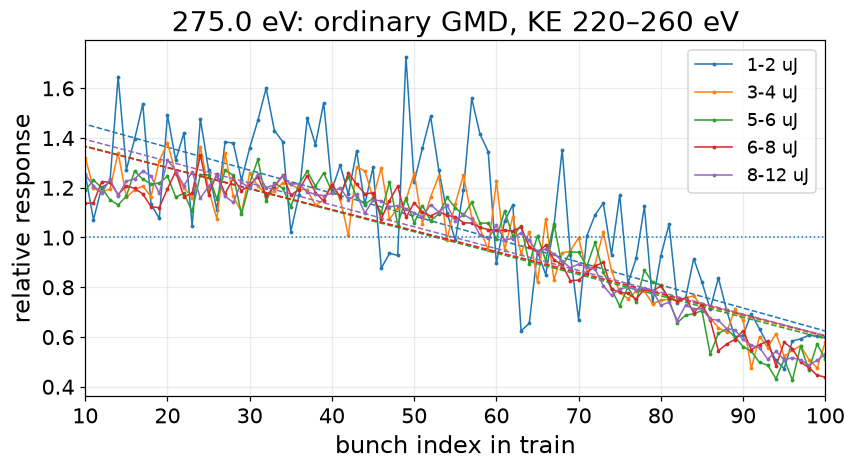

In [ ]:
# Baseline on the same shot population used in the final comparison.
all_target = band_sums(data["target_counts"], gmd, common)
all_gmd = band_sums(gmd, gmd, common)
all_shots = band_sums(np.ones_like(gmd), gmd, common)
baseline = bunch_metrics(all_target, all_gmd, all_shots)
print(f"GMD: flatness={baseline['flatness']:.5f}, slope={baseline['slope']:+.3f}% / 10 bunches")
fig, ax = plt.subplots(figsize=(8,4.5))
plot_bunch_response(baseline, "275.0 eV: ordinary GMD, KE 220–260 eV", ax)
ax.legend()
plt.tight_layout()
plt.show()

## 3. Existing multiplicative $C_b$ correction
Keep the source's band-normalised, shot-weighted $C_b$. Each fold learns it from **training** 190–220 eV counts, then uses $\mathrm{GMD}_{\rm eff}=\mathrm{GMD}\,C_b$ on held-out 220–260 eV shots. No smoothing or interpolation is used.

In [ ]:
# Existing Cb construction, independently for each training fold.
cb_folds = np.full((INDEP_CV_MOD, n_bunch), np.nan)
for off in INDEP_CV_OFFSETS:
    training = common & ((train_ids % INDEP_CV_MOD) != off)[:,None]
    cb_folds[off] = build_compare_cb(
        band_sums(data["ref_counts"], gmd, training),
        band_sums(gmd, gmd, training),
        band_sums(np.ones_like(gmd), gmd, training), bunch_start=INDEP_BUNCH_START)
print("Cb learned separately from reference-region training shots in all five folds.")

Cb learned separately from reference-region training shots in all five folds.


## 4. Existing previous-GMD models
Retain M0 (current GMD only), M5/M10 (mean of previous 5/10 GMD values), and the fixed E2/E3 exponential models. Their held-out predictions supply the normalisation, as in the source. **For independent transfer here, fit them on reference KE too**; the source fitted history models on target KE.

The source calls an undefined exponential helper. Here it is the normalised exponential mean of earlier finite GMD values, reset at each train. Missing GMD contributes neither signal nor weight; the common complete M10 requirement remains. E2 and E3 are fixed comparisons, not selected from held-out performance.

In [ ]:
# Existing linear-model fitting logic, using training reference counts.
beta_cv = {name:[] for name in INDEP_MODELS}
for off in INDEP_CV_OFFSETS:
    training = common & ((train_ids % INDEP_CV_MOD) != off)[:,None]
    y = data["ref_counts"][training].astype(float)
    for name in INDEP_MODELS:
        x = designs[name][training]
        beta_cv[name].append(np.linalg.lstsq(x.T @ x, x.T @ y, rcond=None)[0])
beta_cv = {name:np.asarray(beta) for name,beta in beta_cv.items()}
print("Mean reference-region coefficients across training folds:")
for name in INDEP_MODELS:
    print(name, beta_cv[name].mean(axis=0))

Mean reference-region coefficients across training folds:
M0 [0.00079103 0.00253775]
M5 [4.28144757e-05 2.50691745e-03 1.45982546e-04]
M10 [ 1.28251424e-03  2.55635949e-03 -9.42519066e-05]
E2 [3.12832558e-05 2.50606606e-03 1.48724119e-04]
E3 [0.00025622 0.00251614 0.00010399]


## 5. Exponential shot-resolved electron-history model
Use **all finite positive detected TOF hits**, including hits outside both KE windows and shots outside the GMD selection:

$$H_i(\tau)=\sum_{d\geq1}N_e(i-d)e^{-d/\tau},\qquad R(H)=e^{-\alpha H},.$$

Only earlier bunches enter; $H_0=0$ and $R(0)=1$ in every train. Zero recorded hits give zero load, and no previous-train information fills history. The load is recorded multiplicity: full hit slots can censor the actual load, so the loader reports their number.

Fit $y_{\rm ref}=(a+b\,\mathrm{GMD})R(H)$ by shot-level least squares on **training trains only**. The fitted current-GMD yield is nonnegative across 1–12 µJ. Fit alpha and tau jointly, within the explicit tau bounds in setup, without a grid search or held-out tuning. Use $\mathrm{GMD}_{\rm eff}=\mathrm{GMD}\,R(H)$ for the target-region ratio of sums. Earlier hits from held-out trains are predictors, never fitting targets; current-shot hits do not enter its history.

Also learn a **residual** $C_b$ from training reference counts after using $\mathrm{GMD}\,R(H)$. This small extra comparison checks whether bunch position contributes information after electron history, without applying the original correction twice.

In [ ]:
# Detector response and residual Cb fitted separately on each fold's training trains.
electron_fits = []
residual_cb_folds = np.full_like(cb_folds,np.nan)
for off in INDEP_CV_OFFSETS:
    rows = train_ids % INDEP_CV_MOD != off
    g, selected = gmd[rows], common[rows]
    fit = fit_electron_response(g, data["ref_counts"][rows], data["total_electrons"][rows], selected)
    electron_fits.append(fit)
    R = np.exp(-fit["alpha"] * electron_history(data["total_electrons"][rows], fit["tau"]))
    residual_cb_folds[off] = build_compare_cb(
        band_sums(data["ref_counts"][rows],g,selected), band_sums(g*R,g,selected),
        band_sums(np.ones_like(g),g,selected), bunch_start=INDEP_BUNCH_START)
    print(f"fold {off}: tau={fit['tau']:.3f} bunches, alpha={fit['alpha']:.6g}/electron; "
          f"training reference MSE={fit['training_mse']:.5f}")
print("At alpha=0, tau is unidentifiable; a bound-limited fit is not evidence of a time scale.")

KeyboardInterrupt: 

### Electron history from bunch 0

fold 0: tau=3.240, alpha=-0.08458/electron
fold 1: tau=3.118, alpha=-0.08489/electron
fold 2: tau=3.186, alpha=-0.08937/electron
fold 3: tau=3.200, alpha=-0.08610/electron
fold 4: tau=3.228, alpha=-0.08123/electron


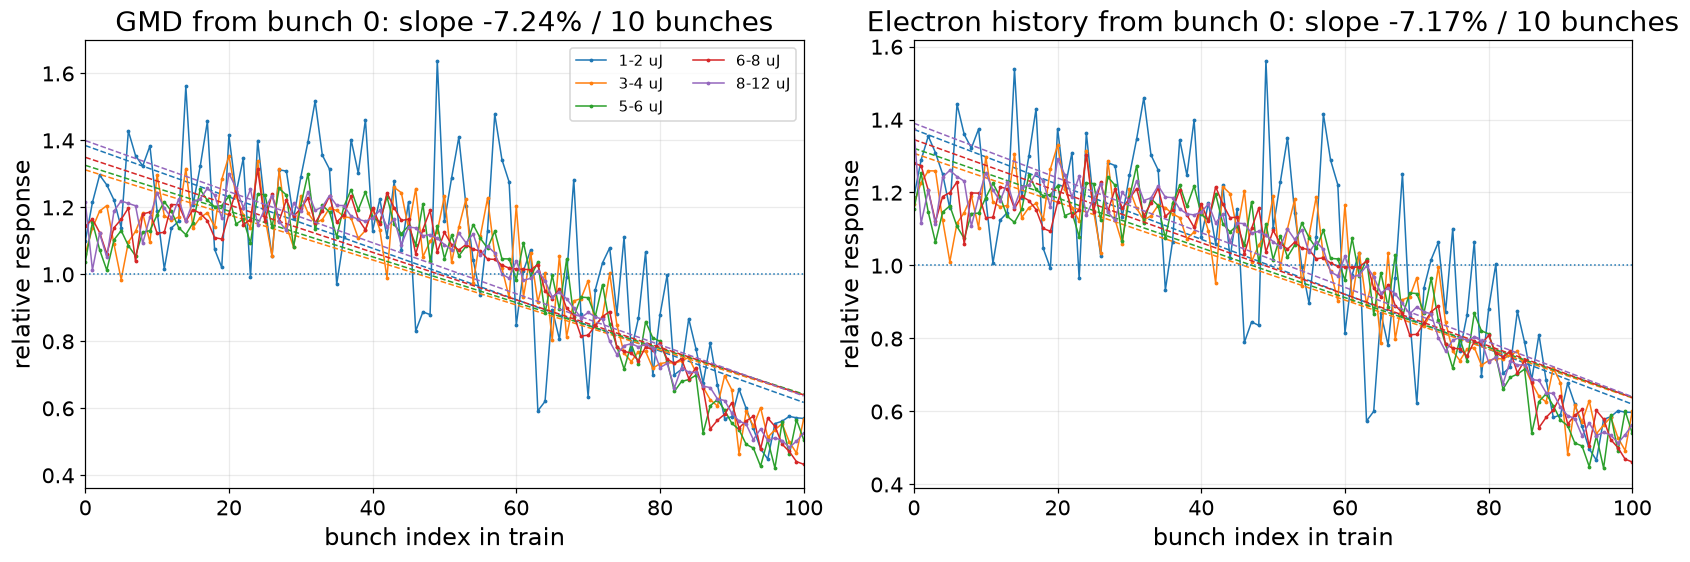

GMD:              flatness=0.23752, slope=-7.235% / 10 bunches
Electron history: flatness=0.22669, slope=-7.169% / 10 bunches


In [ ]:
# --- Diagnostic: electron-history model using the full train from bunch 0 ---

mask0 = np.isfinite(gmd) & (gmd >= INDEP_GMD_RANGE[0]) & (gmd < INDEP_GMD_RANGE[1])

electron_fits0 = []
hold_target0 = np.zeros((INDEP_CV_MOD,len(INDEP_GMD_BANDS),n_bunch))
hold_shots0 = np.zeros_like(hold_target0)
hold_gmd0 = np.zeros_like(hold_target0)
hold_history0 = np.zeros_like(hold_target0)

for off in INDEP_CV_OFFSETS:
    train_rows = train_ids % INDEP_CV_MOD != off
    test_rows = train_ids % INDEP_CV_MOD == off

    fit = fit_electron_response(gmd[train_rows],data["ref_counts"][train_rows],data["total_electrons"][train_rows],mask0[train_rows])
    electron_fits0.append(fit)

    g = gmd[test_rows]
    selected = mask0[test_rows]
    H = electron_history(data["total_electrons"][test_rows],fit["tau"])
    R = np.exp(-fit["alpha"]*H)

    hold_target0[off] = band_sums(data["target_counts"][test_rows],g,selected)
    hold_shots0[off] = band_sums(np.ones_like(g),g,selected)
    hold_gmd0[off] = band_sums(g,g,selected)
    hold_history0[off] = band_sums(g*R,g,selected)

    print(f"fold {off}: tau={fit['tau']:.3f}, alpha={fit['alpha']:.5f}/electron")

def bunch_metrics_from_zero(obs,norm,shots):
    relative = compare_relative_response(obs,norm,bunch_start=0)
    lines = np.array([weighted_bunch_line(r,w,0) if np.count_nonzero((w > 0) & np.isfinite(r)) >= 2 else (np.nan,np.nan) for r,w in zip(relative,shots)])
    weights = shots.sum(axis=1)
    valid = (weights > 0) & np.isfinite(lines[:,0])
    slope = 1000*np.average(lines[valid,0],weights=weights[valid]) if valid.any() else np.nan
    return dict(relative=relative,lines=lines,slope=slope,flatness=compare_flatness(relative,shots,bunch_start=0))

obs0 = hold_target0.sum(axis=0)
shots0 = hold_shots0.sum(axis=0)
gmd0 = bunch_metrics_from_zero(obs0,hold_gmd0.sum(axis=0),shots0)
history0 = bunch_metrics_from_zero(obs0,hold_history0.sum(axis=0),shots0)

fig,axes = plt.subplots(1,2,figsize=(15,5),constrained_layout=True)
plot_bunch_response(gmd0,f"GMD from bunch 0: slope {gmd0['slope']:+.2f}% / 10 bunches",axes[0])
plot_bunch_response(history0,f"Electron history from bunch 0: slope {history0['slope']:+.2f}% / 10 bunches",axes[1])
for ax in axes: ax.set_xlim(0,n_bunch-1)
axes[0].legend(ncol=2,fontsize=10)
plt.show()

print(f"GMD:              flatness={gmd0['flatness']:.5f}, slope={gmd0['slope']:+.3f}% / 10 bunches")
print(f"Electron history: flatness={history0['flatness']:.5f}, slope={history0['slope']:+.3f}% / 10 bunches")

### How does H change through the train?

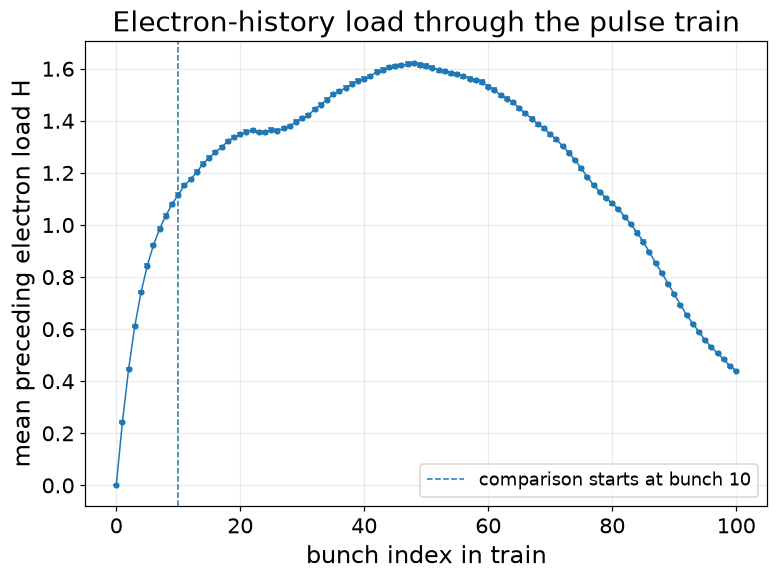

In [ ]:
# --- Diagnostic 1: electron-history load H versus bunch position ---
H_cv = np.full_like(gmd, np.nan, dtype=float)

for off in INDEP_CV_OFFSETS:
    rows = train_ids % INDEP_CV_MOD == off
    H_cv[rows] = electron_history(data["total_electrons"][rows], electron_fits[off]["tau"])

mean_H = np.nanmean(H_cv, axis=0)
sem_H = np.nanstd(H_cv, axis=0, ddof=1) / np.sqrt(np.sum(np.isfinite(H_cv), axis=0))
bunch = np.arange(gmd.shape[1])

# Plotting
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.errorbar(bunch, mean_H, yerr=sem_H, fmt="o-", ms=3, lw=1, capsize=2)
ax.axvline(INDEP_BUNCH_START, ls="--", lw=1, label=f"comparison starts at bunch {INDEP_BUNCH_START}")
ax.set(xlabel="bunch index in train", ylabel="mean preceding electron load H", title="Electron-history load through the pulse train")
ax.grid(alpha=0.25); ax.legend(); plt.show()

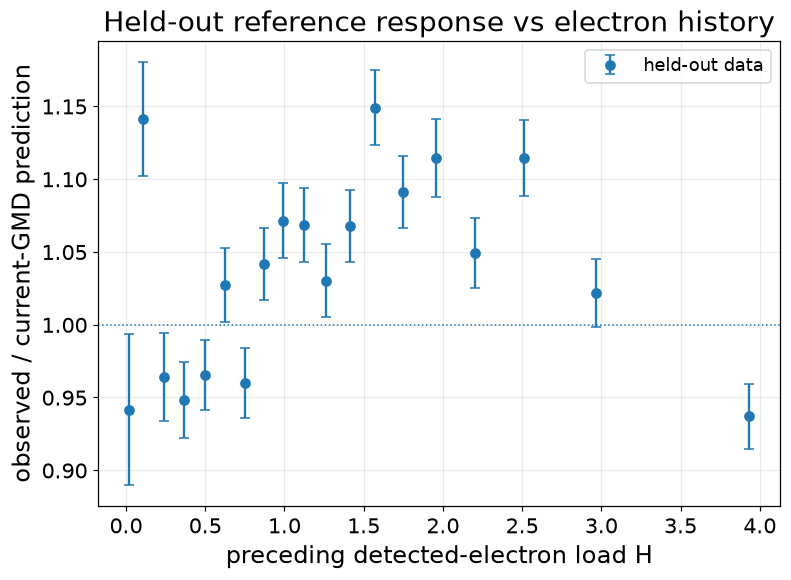

H range: 0.000 to 41.042
Trains per H bin: 17378 to 32416


In [ ]:
# --- Diagnostic 2: held-out response versus electron history ---
# Error bars describe train-to-train variation rather than only counting statistics.
N_HISTORY_BINS = 20

H_cv = np.full_like(gmd, np.nan, dtype=float)
pred_cv = np.full_like(gmd, np.nan, dtype=float)

for off in INDEP_CV_OFFSETS:
    rows = train_ids % INDEP_CV_MOD == off
    H_cv[rows] = electron_history(data["total_electrons"][rows], electron_fits[off]["tau"])
    pred_cv[rows] = designs["M0"][rows] @ beta_cv["M0"][off]

valid = common & np.isfinite(H_cv) & np.isfinite(pred_cv) & (pred_cv > 0)
h_values = H_cv[valid]

# Equal-population bins in H.
edges = np.unique(np.quantile(h_values, np.linspace(0, 1, N_HISTORY_BINS + 1)))

h_bin, response_bin, response_sem, trains_per_bin = [], [], [], []

for i in range(len(edges) - 1):
    in_bin = valid & (H_cv >= edges[i]) & (H_cv <= edges[i + 1] if i == len(edges) - 2 else H_cv < edges[i + 1])
    train_response, train_H = [], []

    for train in range(gmd.shape[0]):
        use = in_bin[train]
        if not np.any(use): continue

        obs_sum, pred_sum = data["ref_counts"][train, use].sum(), pred_cv[train, use].sum()
        if pred_sum <= 0: continue

        train_response.append(obs_sum / pred_sum)
        train_H.append(np.mean(H_cv[train, use]))

    train_response, train_H = np.asarray(train_response), np.asarray(train_H)
    if train_response.size < 2: continue

    h_bin.append(np.mean(train_H))
    response_bin.append(np.mean(train_response))
    response_sem.append(np.std(train_response, ddof=1) / np.sqrt(train_response.size))
    trains_per_bin.append(train_response.size)

h_bin, response_bin, response_sem, trains_per_bin = map(np.asarray, (h_bin, response_bin, response_sem, trains_per_bin))

# Plotting
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.errorbar(h_bin, response_bin, yerr=response_sem, fmt="o", capsize=3, label="held-out data")
ax.axhline(1.0, ls=":", lw=1)
ax.set(xlabel="preceding detected-electron load H", ylabel="observed / current-GMD prediction", title="Held-out reference response vs electron history")
ax.grid(alpha=0.25); ax.legend(); plt.show()

print(f"H range: {h_values.min():.3f} to {h_values.max():.3f}")
print(f"Trains per H bin: {trains_per_bin.min()} to {trains_per_bin.max()}")

### Trying different functions in the model

exponential  fold 0: tau=3.030, alpha=-0.05619
reciprocal   fold 0: tau=3.000, alpha=0.01988
saturating   fold 0: tau=3.035, A=-0.1633, H0=0.984
exponential  fold 1: tau=3.030, alpha=-0.05468
reciprocal   fold 1: tau=3.000, alpha=0.01988
saturating   fold 1: tau=3.052, A=-0.1707, H0=0.983
exponential  fold 2: tau=3.029, alpha=-0.05569
reciprocal   fold 2: tau=3.000, alpha=0.01988
saturating   fold 2: tau=3.048, A=-0.1593, H0=0.989
exponential  fold 3: tau=3.034, alpha=-0.05846
reciprocal   fold 3: tau=3.000, alpha=0.01988
saturating   fold 3: tau=3.071, A=-0.1582, H0=0.994
exponential  fold 4: tau=3.028, alpha=-0.05362
reciprocal   fold 4: tau=3.000, alpha=0.01988
saturating   fold 4: tau=3.046, A=-0.1570, H0=0.989
GMD         : flatness=0.24683, slope=-8.675% / 10 bunches
exponential : flatness=0.23720, slope=-8.396% / 10 bunches
reciprocal  : flatness=0.25006, slope=-8.767% / 10 bunches
saturating  : flatness=0.23874, slope=-8.447% / 10 bunches


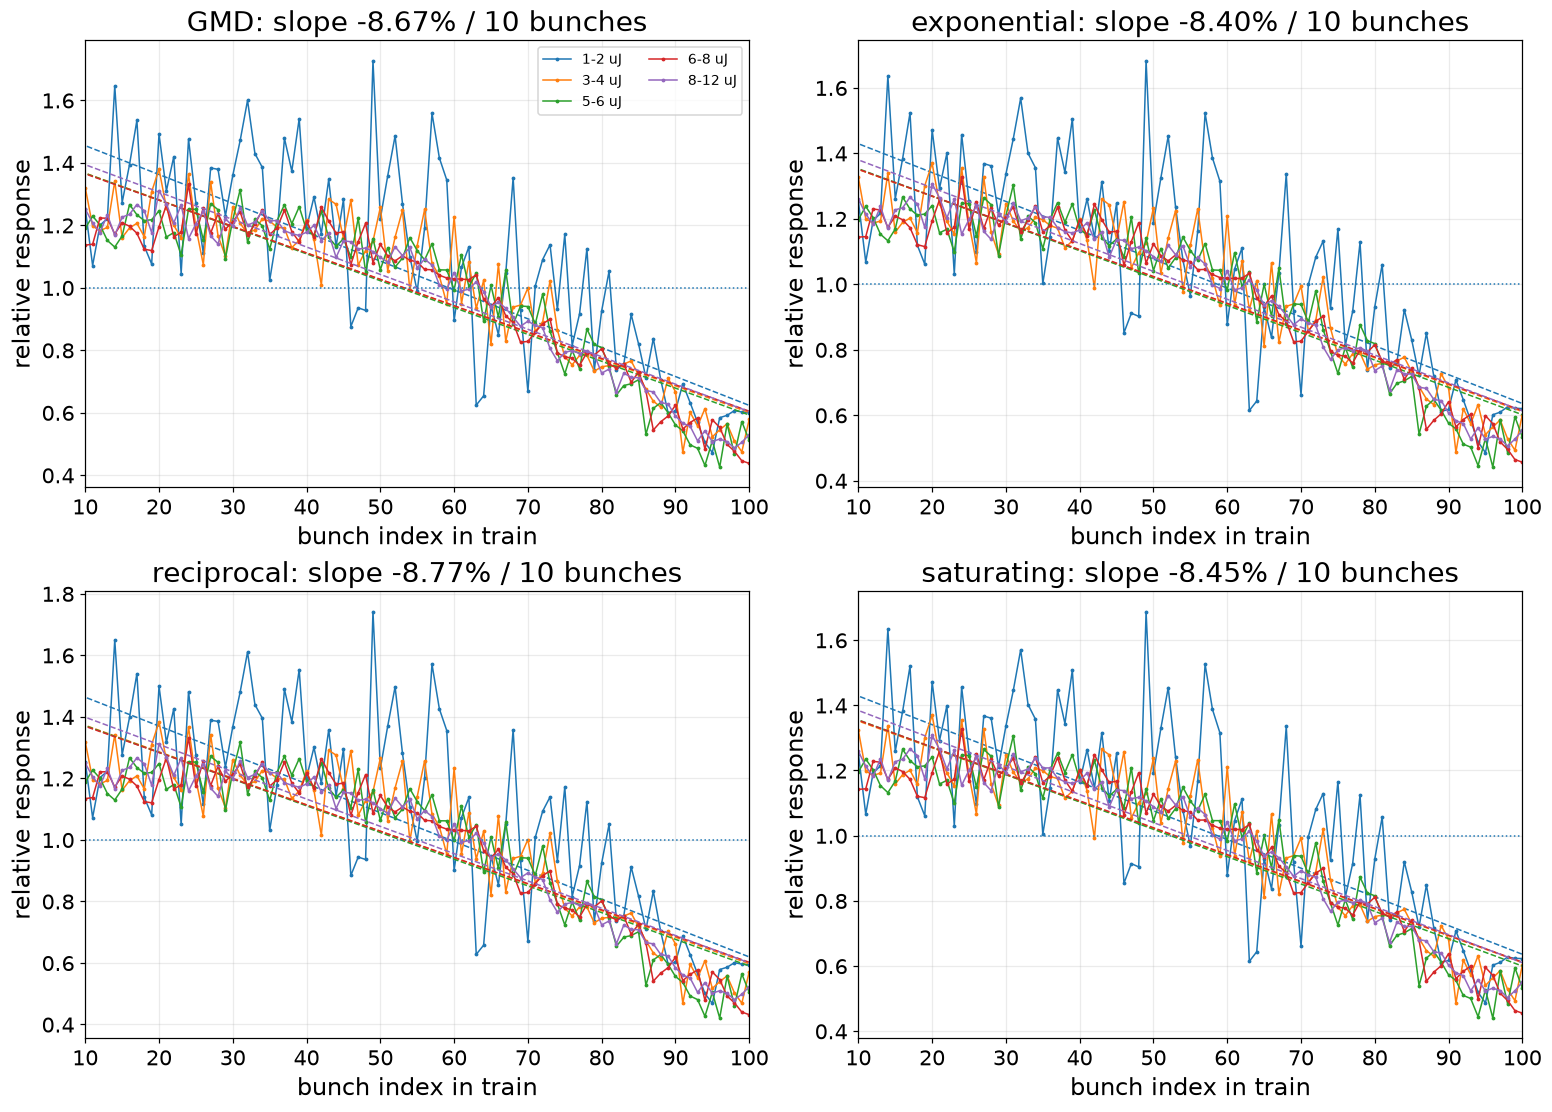

In [ ]:
# --- Compare simple history-response functions with the current-GMD baseline fixed ---

HISTORY_FORMS = ["exponential","reciprocal","saturating"]

def history_response(H,p,form):
    if form == "exponential": return np.exp(-p[0]*H)
    if form == "reciprocal": return 1/(1+p[0]*H)
    if form == "saturating": return 1-p[0]*(1-np.exp(-H/np.exp(p[1])))
    raise ValueError(form)

def fit_fixed_gmd_history(gmd,ref_counts,total_electrons,selected,beta_m0,form):
    base = beta_m0[0] + beta_m0[1]*gmd
    y = ref_counts.astype(float)

    def objective(p):
        tau = np.exp(p[-1])
        H = electron_history(total_electrons,tau)
        R = history_response(H,p,form)
        if not np.all(np.isfinite(R)) or np.any(R <= 0): return 1e30
        use = selected & np.isfinite(base) & (base > 0)
        return np.mean((y[use]-base[use]*R[use])**2)

    if form in ("exponential","reciprocal"):
        x0 = [0.02,np.log(ELECTRON_TAU_INITIAL)]
        bounds = [(None,None),tuple(np.log(ELECTRON_TAU_BOUNDS))]
    else:
        x0 = [0.10,np.log(1.0),np.log(ELECTRON_TAU_INITIAL)]
        bounds = [(None,0.95),(np.log(0.05),np.log(20.0)),tuple(np.log(ELECTRON_TAU_BOUNDS))]

    result = minimize(objective,x0,method="L-BFGS-B",bounds=bounds)
    if not result.success: raise RuntimeError(result.message)
    return result.x

history_form_fits = {form:[] for form in HISTORY_FORMS}
hold_target = np.zeros((INDEP_CV_MOD,len(INDEP_GMD_BANDS),n_bunch))
hold_shots = np.zeros_like(hold_target)
hold_norm = {form:np.zeros_like(hold_target) for form in HISTORY_FORMS}
hold_gmd = np.zeros_like(hold_target)

for off in INDEP_CV_OFFSETS:
    train_rows = train_ids % INDEP_CV_MOD != off
    test_rows = train_ids % INDEP_CV_MOD == off

    g_train,sel_train = gmd[train_rows],common[train_rows]
    g_test,sel_test = gmd[test_rows],common[test_rows]

    hold_target[off] = band_sums(data["target_counts"][test_rows],g_test,sel_test)
    hold_shots[off] = band_sums(np.ones_like(g_test),g_test,sel_test)
    hold_gmd[off] = band_sums(g_test,g_test,sel_test)

    for form in HISTORY_FORMS:
        p = fit_fixed_gmd_history(g_train,data["ref_counts"][train_rows],data["total_electrons"][train_rows],sel_train,beta_cv["M0"][off],form)
        history_form_fits[form].append(p)

        tau = np.exp(p[-1])
        H = electron_history(data["total_electrons"][test_rows],tau)
        R = history_response(H,p,form)
        hold_norm[form][off] = band_sums(g_test*R,g_test,sel_test)

        extra = f", A={p[0]:.4f}, H0={np.exp(p[1]):.3f}" if form == "saturating" else f", alpha={p[0]:.5f}"
        print(f"{form:12s} fold {off}: tau={tau:.3f}{extra}")

obs = hold_target.sum(axis=0)
shots = hold_shots.sum(axis=0)
metrics = {"GMD":bunch_metrics(obs,hold_gmd.sum(axis=0),shots)}
for form in HISTORY_FORMS: metrics[form] = bunch_metrics(obs,hold_norm[form].sum(axis=0),shots)

for name,m in metrics.items(): print(f"{name:12s}: flatness={m['flatness']:.5f}, slope={m['slope']:+.3f}% / 10 bunches")

fig,axes = plt.subplots(2,2,figsize=(14,10),constrained_layout=True)
for ax,(name,m) in zip(axes.flat,metrics.items()): plot_bunch_response(m,f"{name}: slope {m['slope']:+.2f}% / 10 bunches",ax)
axes[0,0].legend(ncol=2,fontsize=9)
plt.show()

### First comparison

,held-out flatness,slope (% / 10 bunches),|slope| reduction (%),fold flatness mean,fold flatness SD,fold slope mean,fold slope SD
method,,,,,,,
GMD,0.24683,-8.67495,0.00000,0.27576,0.00515,-8.67697,0.18211
M0,0.24714,-8.67939,-0.05123,0.27607,0.00517,-8.68116,0.18231
M5,0.24682,-8.79189,-1.34807,0.27532,0.00540,-8.79396,0.17962
M10,0.24631,-8.56193,1.30278,0.27566,0.00506,-8.56401,0.18058
E2,0.24639,-8.77983,-1.20899,0.27489,0.00545,-8.78185,0.17749
E3,0.24715,-8.76875,-1.08132,0.27574,0.00536,-8.77079,0.17724
Cb,0.09468,0.53651,93.81537,0.16329,0.00516,0.56081,0.19306
Electron history,0.22981,-8.17863,5.72127,0.26009,0.00593,-8.18143,0.20732
Electron history + Cb,0.09482,0.54377,93.73169,0.16346,0.00512,0.56804,0.19133


,alpha,tau,a,b,training_mse
training fold,,,,,
0,-0.095881,3.297362,0.001037,0.002167,0.015674
1,-0.088929,3.135596,0.000925,0.002229,0.015659
2,-0.094850,3.291247,0.001065,0.002168,0.015690
3,-0.089616,3.143741,0.000995,0.002216,0.015692
4,-0.090281,3.276722,0.001178,0.002167,0.015702


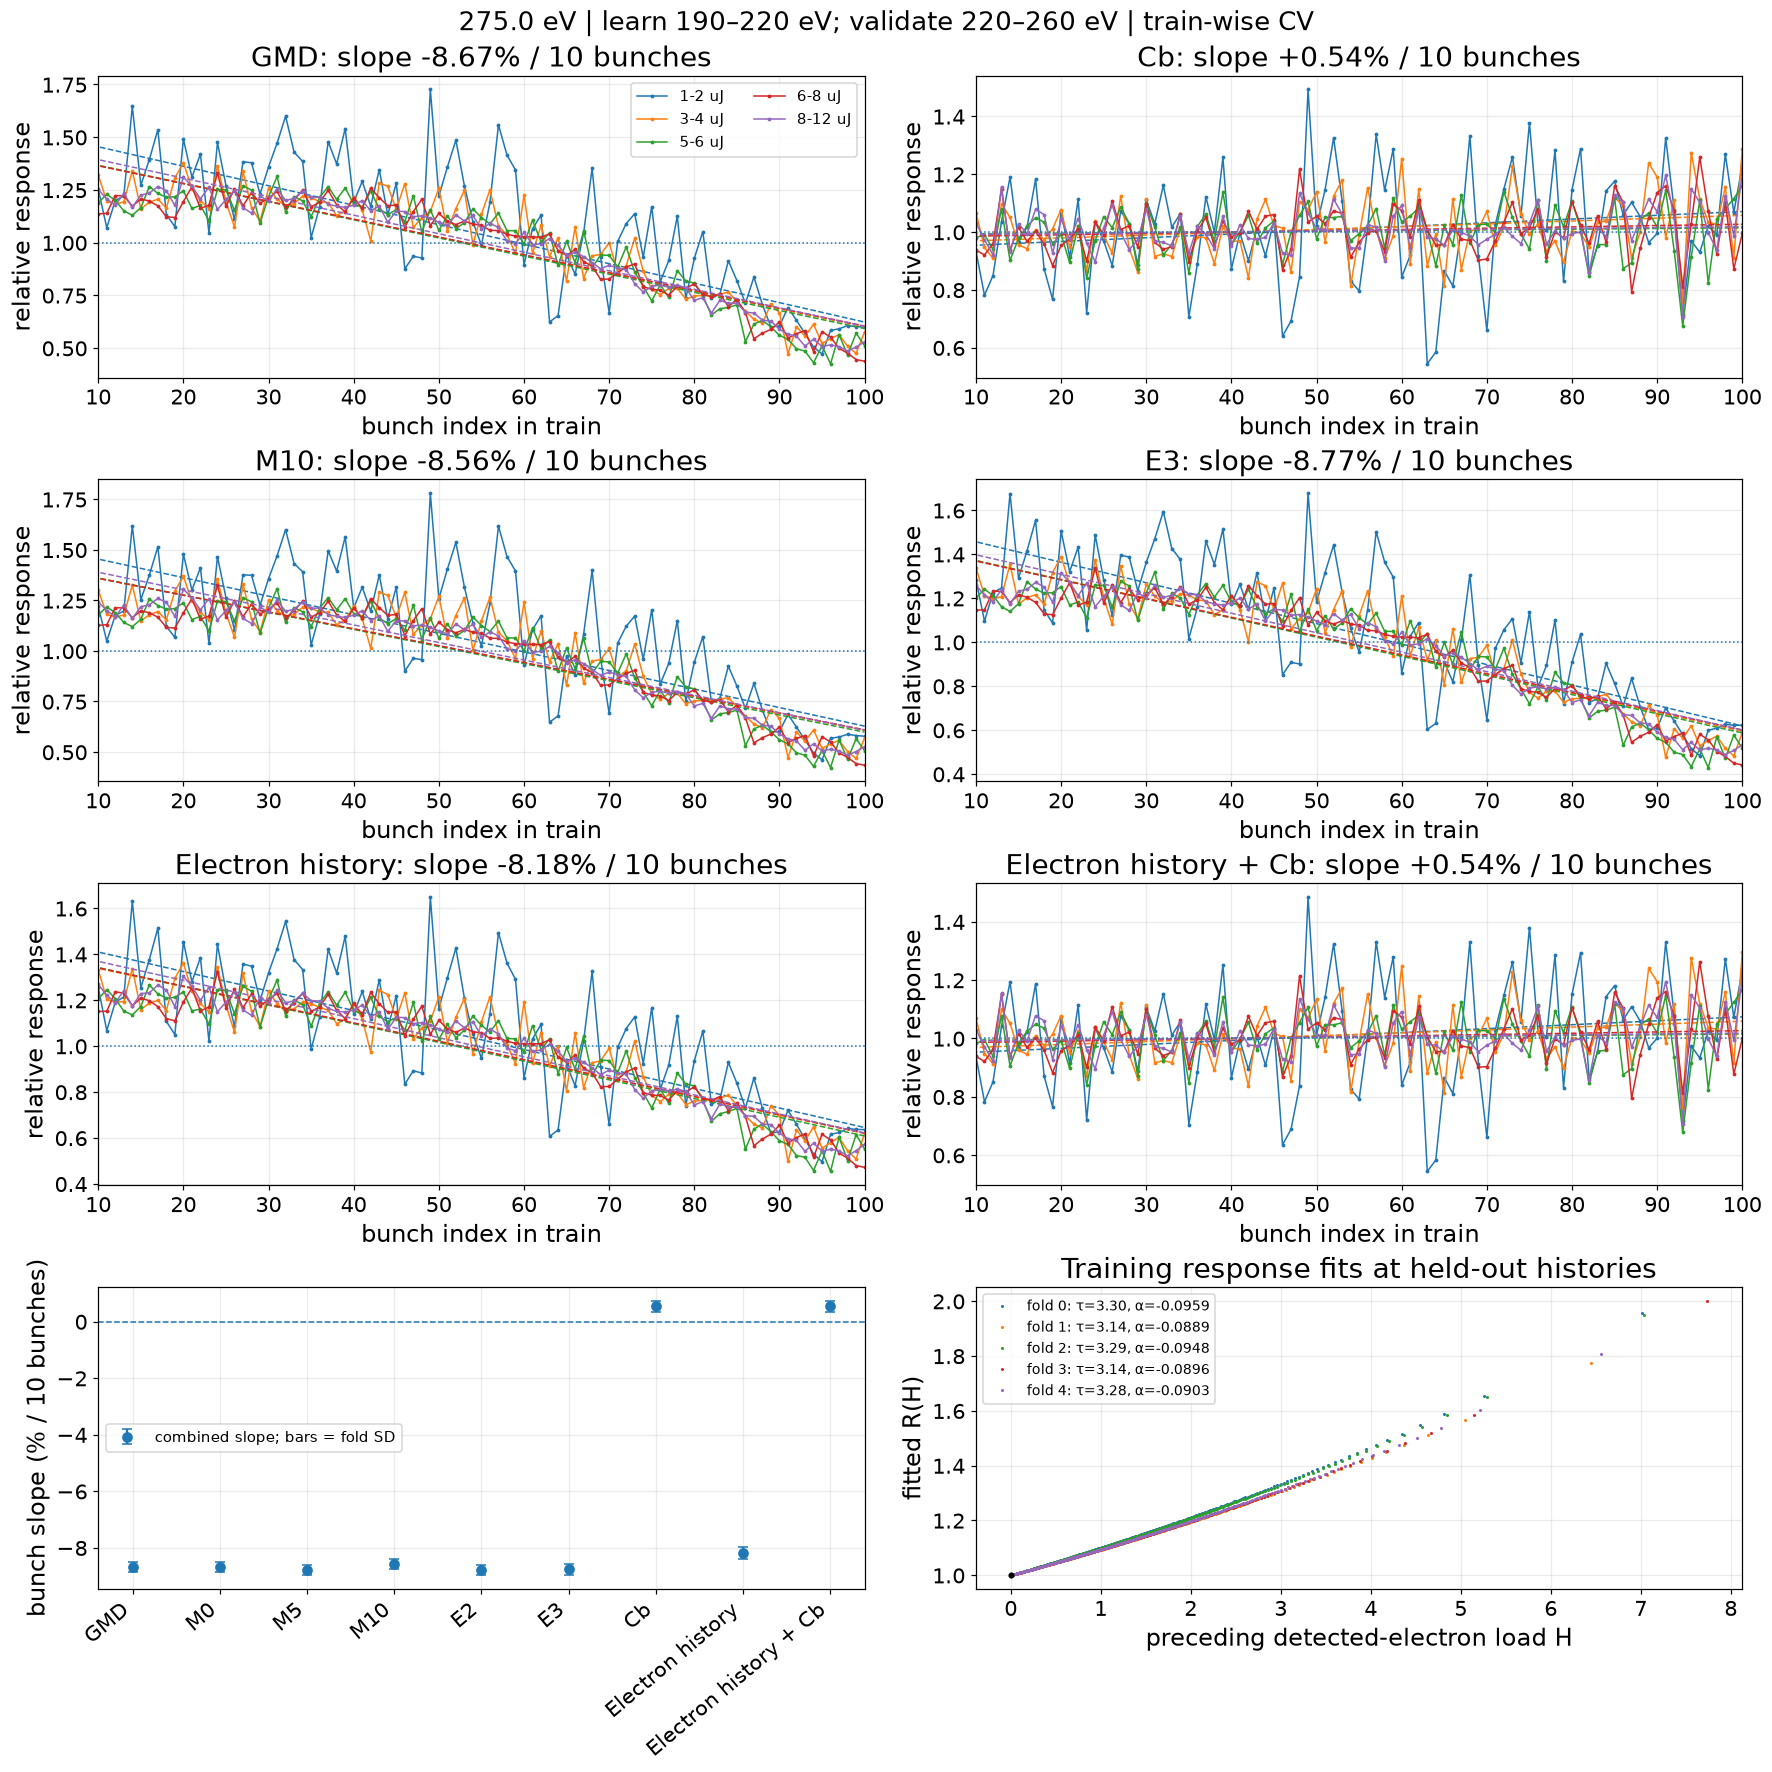


Electron history -> electron history + residual Cb, held-out target:
fold 0: flatness 0.25055 -> 0.15745; slope -7.921 -> +0.726% / 10 bunches
fold 1: flatness 0.26657 -> 0.17059; slope -8.496 -> +0.345% / 10 bunches
fold 2: flatness 0.26172 -> 0.16027; slope -8.127 -> +0.416% / 10 bunches
fold 3: flatness 0.25943 -> 0.16283; slope -8.147 -> +0.789% / 10 bunches
fold 4: flatness 0.26217 -> 0.16616; slope -8.217 -> +0.565% / 10 bunches


In [ ]:
# One final table and comparison figure, with identical held-out shots for every method.
combined, fold_metrics = evaluate_held_out(data,designs,common,beta_cv,cb_folds,
                                          electron_fits,residual_cb_folds)
comparison_rows = []
slope0 = combined["GMD"]["slope"]
for name,m in combined.items():
    flat = np.array([f["flatness"] for f in fold_metrics[name]])
    slope = np.array([f["slope"] for f in fold_metrics[name]])
    comparison_rows.append({"method":name, "held-out flatness":m["flatness"],
        "slope (% / 10 bunches)":m["slope"],
        "|slope| reduction (%)":100*(1-abs(m["slope"])/abs(slope0)) if slope0 else np.nan,
        "fold flatness mean":flat.mean(), "fold flatness SD":flat.std(ddof=1),
        "fold slope mean":slope.mean(), "fold slope SD":slope.std(ddof=1)})
comparison_table = pd.DataFrame(comparison_rows).set_index("method")
display(comparison_table.round(5))
display(pd.DataFrame(electron_fits).rename_axis("training fold").round(6))

plot_names = ["GMD","Cb","M10","E3","Electron history","Electron history + Cb"]
fig,axes = plt.subplots(4,2,figsize=(16,16),constrained_layout=True)
for ax,name in zip(axes.flat,plot_names):
    m = combined[name]
    plot_bunch_response(m,f"{name}: slope {m['slope']:+.2f}% / 10 bunches",ax)
axes[0,0].legend(ncol=2,fontsize=10)
ax = axes[3,0]
names = list(combined)
ax.errorbar(np.arange(len(names)),[combined[name]["slope"] for name in names],
            yerr=[comparison_table.loc[name,"fold slope SD"] for name in names],
            fmt="o",capsize=3,label="combined slope; bars = fold SD")
ax.axhline(0,ls="--",lw=1)
ax.set_xticks(np.arange(len(names)),names,rotation=40,ha="right")
ax.set_ylabel("bunch slope (% / 10 bunches)")
ax.grid(alpha=0.25)
ax.legend(fontsize=10)

ax = axes[3,1]
# Actual held-out H values: no smoothed or interpolated data.
for off,fit in enumerate(electron_fits):
    rows = train_ids % INDEP_CV_MOD == off
    h = np.sort(electron_history(data["total_electrons"][rows],fit["tau"])[common[rows]])
    step = max(1,h.size//300)  # Thin displayed points only; all shots enter metrics.
    h_plot = h[::step]
    ax.plot(h_plot,np.exp(-fit["alpha"]*h_plot),".",ms=2,
            label=f"fold {off}: τ={fit['tau']:.2f}, α={fit['alpha']:.3g}")
ax.plot(0,1,"ko",ms=3)
ax.set_xlabel("preceding detected-electron load H")
ax.set_ylabel("fitted R(H)")
ax.set_title("Training response fits at held-out histories")
ax.grid(alpha=0.25)
ax.legend(fontsize=9)
fig.suptitle("275.0 eV | learn 190–220 eV; validate 220–260 eV | train-wise CV")
plt.show()

print("\nElectron history -> electron history + residual Cb, held-out target:")
for off in INDEP_CV_OFFSETS:
    e,ec = fold_metrics["Electron history"][off],fold_metrics["Electron history + Cb"][off]
    print(f"fold {off}: flatness {e['flatness']:.5f} -> {ec['flatness']:.5f}; "
          f"slope {e['slope']:+.3f} -> {ec['slope']:+.3f}% / 10 bunches")

### Diagnostics: Scanning tau

,alpha_mean,alpha_sd,ref_mse,baseline_mse,ref MSE improvement (%),target slope,target flatness,target slope SD
tau,,,,,,,,
0.25,0.000000,0.000000,0.015690,0.01569,0.000000,-8.674948,0.246832,0.182107
0.50,0.000000,0.000000,0.015690,0.01569,0.000000,-8.674948,0.246832,0.182107
1.00,-0.000025,0.000000,0.015690,0.01569,0.000004,-8.674913,0.246830,0.182107
2.00,-0.078909,0.001922,0.015687,0.01569,0.019216,-8.400495,0.237805,0.189304
3.00,-0.057190,0.000927,0.015687,0.01569,0.021581,-8.390124,0.237033,0.186535
5.00,-0.036180,0.000558,0.015687,0.01569,0.022183,-8.459415,0.238040,0.186325
10.00,-0.016903,0.000222,0.015687,0.01569,0.017595,-8.731579,0.243980,0.185674
20.00,-0.006512,0.000088,0.015689,0.01569,0.008789,-8.996130,0.251075,0.183187
50.00,-0.001437,0.000045,0.015690,0.01569,0.001354,-8.936861,0.251776,0.180963


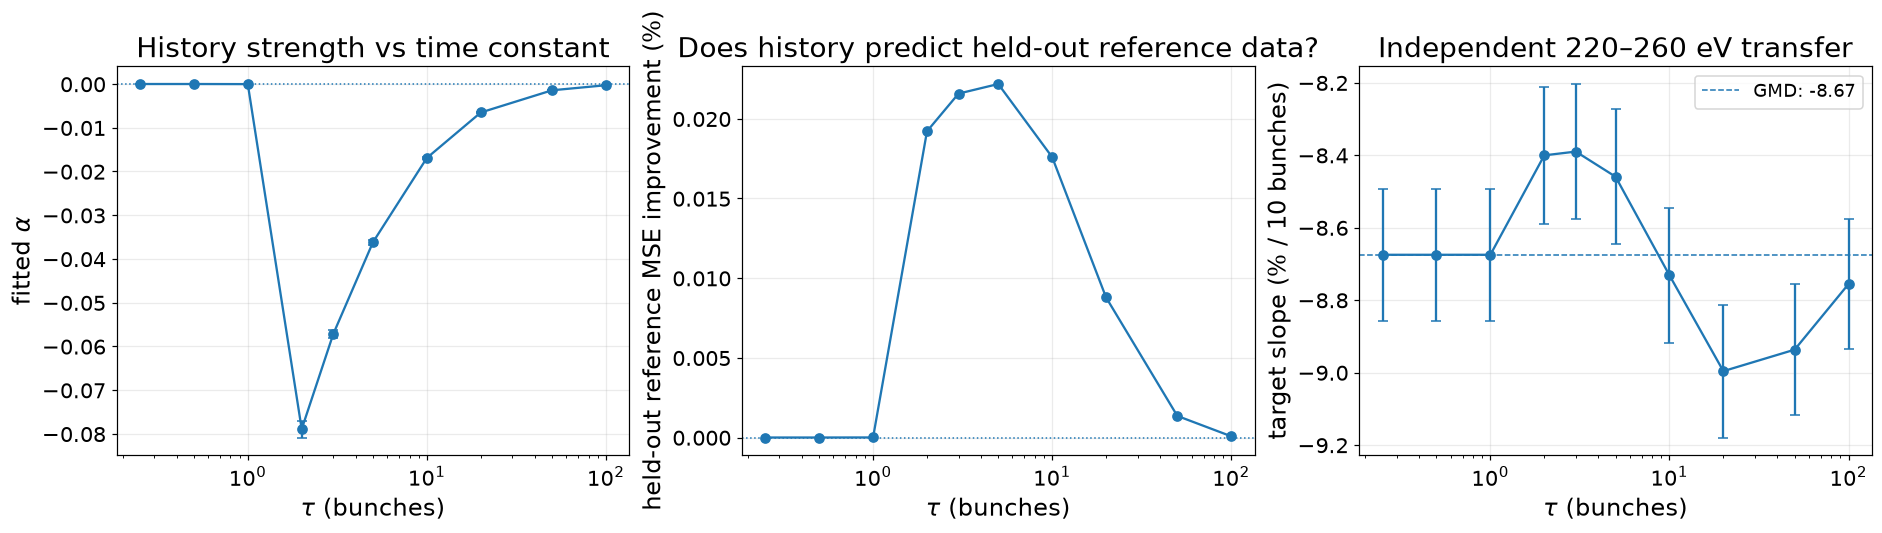

In [ ]:
# --- Profile the electron-history time constant with the current-GMD baseline fixed ---

TAU_GRID = np.array([0.25,0.5,1,2,3,5,10,20,50,100],dtype=float)
ALPHA_BOUNDS = (-0.25,0.25)

profile_rows = []
shape = (INDEP_CV_MOD,len(INDEP_GMD_BANDS),n_bunch)
hold_target_tau = np.zeros(shape)
hold_shots_tau = np.zeros(shape)
hold_gmd_tau = np.zeros(shape)
hold_norm_tau = np.zeros((len(TAU_GRID),*shape))

for off in INDEP_CV_OFFSETS:
    train_rows = train_ids % INDEP_CV_MOD != off
    test_rows = train_ids % INDEP_CV_MOD == off

    g_train,g_test = gmd[train_rows],gmd[test_rows]
    sel_train,sel_test = common[train_rows],common[test_rows]
    y_train,y_test = data["ref_counts"][train_rows].astype(float),data["ref_counts"][test_rows].astype(float)

    a,b = beta_cv["M0"][off]
    base_train = a+b*g_train
    base_test = a+b*g_test
    use_train = sel_train & np.isfinite(base_train) & (base_train > 0)
    use_test = sel_test & np.isfinite(base_test) & (base_test > 0)

    baseline_mse = np.mean((y_test[use_test]-base_test[use_test])**2)

    hold_target_tau[off] = band_sums(data["target_counts"][test_rows],g_test,sel_test)
    hold_shots_tau[off] = band_sums(np.ones_like(g_test),g_test,sel_test)
    hold_gmd_tau[off] = band_sums(g_test,g_test,sel_test)

    for j,tau in enumerate(TAU_GRID):
        H_train = electron_history(data["total_electrons"][train_rows],tau)
        H_test = electron_history(data["total_electrons"][test_rows],tau)

        def loss(x):
            pred = base_train[use_train]*np.exp(-x[0]*H_train[use_train])
            return np.mean((y_train[use_train]-pred)**2)

        result = minimize(loss,[0.0],method="L-BFGS-B",bounds=[ALPHA_BOUNDS])
        if not result.success: raise RuntimeError(result.message)

        alpha = float(result.x[0])
        pred_test = base_test[use_test]*np.exp(-alpha*H_test[use_test])
        ref_mse = np.mean((y_test[use_test]-pred_test)**2)
        R_test = np.exp(-alpha*H_test)

        hold_norm_tau[j,off] = band_sums(g_test*R_test,g_test,sel_test)
        profile_rows.append({"fold":off,"tau":tau,"alpha":alpha,"ref_mse":ref_mse,"baseline_mse":baseline_mse})

profile_tau = pd.DataFrame(profile_rows)
summary_tau = profile_tau.groupby("tau").agg(alpha_mean=("alpha","mean"),alpha_sd=("alpha","std"),ref_mse=("ref_mse","mean"),baseline_mse=("baseline_mse","mean"))
summary_tau["ref MSE improvement (%)"] = 100*(1-summary_tau["ref_mse"]/summary_tau["baseline_mse"])

obs_tau = hold_target_tau.sum(axis=0)
shots_tau = hold_shots_tau.sum(axis=0)
gmd_metric_tau = bunch_metrics(obs_tau,hold_gmd_tau.sum(axis=0),shots_tau)

target_slopes,target_flatness,target_slope_sd = [],[],[]
for j,tau in enumerate(TAU_GRID):
    m = bunch_metrics(obs_tau,hold_norm_tau[j].sum(axis=0),shots_tau)
    fold_m = [bunch_metrics(hold_target_tau[off],hold_norm_tau[j,off],hold_shots_tau[off]) for off in INDEP_CV_OFFSETS]
    target_slopes.append(m["slope"])
    target_flatness.append(m["flatness"])
    target_slope_sd.append(np.std([f["slope"] for f in fold_m],ddof=1))

summary_tau["target slope"] = target_slopes
summary_tau["target flatness"] = target_flatness
summary_tau["target slope SD"] = target_slope_sd
display(summary_tau.round(6))

fig,axes = plt.subplots(1,3,figsize=(17,4.5),constrained_layout=True)
axes[0].errorbar(TAU_GRID,summary_tau["alpha_mean"],yerr=summary_tau["alpha_sd"],fmt="o-",capsize=3)
axes[0].axhline(0,ls=":",lw=1); axes[0].set(xscale="log",xlabel=r"$\tau$ (bunches)",ylabel=r"fitted $\alpha$",title="History strength vs time constant"); axes[0].grid(alpha=0.25)
axes[1].plot(TAU_GRID,summary_tau["ref MSE improvement (%)"],"o-")
axes[1].axhline(0,ls=":",lw=1); axes[1].set(xscale="log",xlabel=r"$\tau$ (bunches)",ylabel="held-out reference MSE improvement (%)",title="Does history predict held-out reference data?"); axes[1].grid(alpha=0.25)
axes[2].errorbar(TAU_GRID,summary_tau["target slope"],yerr=summary_tau["target slope SD"],fmt="o-",capsize=3)
axes[2].axhline(gmd_metric_tau["slope"],ls="--",lw=1,label=f"GMD: {gmd_metric_tau['slope']:+.2f}")
axes[2].set(xscale="log",xlabel=r"$\tau$ (bunches)",ylabel="target slope (% / 10 bunches)",title="Independent 220–260 eV transfer"); axes[2].grid(alpha=0.25); axes[2].legend()
plt.show()

## 6. Final apples-to-apples comparison
Every method uses the **same held-out trains, shots and 220–260 eV counts**. The table reports combined flatness and weighted bunch slope, absolute-slope reduction relative to GMD, and fold mean/SD. Fold variation is descriptive, not an independent confidence interval.

Inspect band-resolved electron-history residuals: a small average slope can hide opposite trends in different bands. Additional improvement from **electron history + residual Cb** means this electron-history model leaves bunch-position structure. Little further improvement is consistent with an electron-load explanation, but does not establish causality.

In [ ]:
# One final table and comparison figure, with identical held-out shots for every method.
combined, fold_metrics = evaluate_held_out(data,designs,common,beta_cv,cb_folds,electron_fits,residual_cb_folds)

# Add the free linear lag-history model using the same held-out target shots.
combined["Free lag history"] = bunch_metrics(hold_target_kernel.sum(axis=0),hold_norm_kernel.sum(axis=0),hold_shots_kernel.sum(axis=0))
fold_metrics["Free lag history"] = [bunch_metrics(hold_target_kernel[off],hold_norm_kernel[off],hold_shots_kernel[off]) for off in INDEP_CV_OFFSETS]

# Remove the residual-Cb combination from this final presentation.
combined.pop("Electron history + Cb",None)
fold_metrics.pop("Electron history + Cb",None)

comparison_rows = []
slope0 = combined["GMD"]["slope"]
for name,m in combined.items():
    flat = np.array([f["flatness"] for f in fold_metrics[name]])
    slope = np.array([f["slope"] for f in fold_metrics[name]])
    comparison_rows.append({"method":name,"held-out flatness":m["flatness"],"slope (% / 10 bunches)":m["slope"],"|slope| reduction (%)":100*(1-abs(m["slope"])/abs(slope0)) if slope0 else np.nan,"fold flatness mean":flat.mean(),"fold flatness SD":flat.std(ddof=1),"fold slope mean":slope.mean(),"fold slope SD":slope.std(ddof=1)})

comparison_table = pd.DataFrame(comparison_rows).set_index("method")
display(comparison_table.round(5))
display(pd.DataFrame(electron_fits).rename_axis("training fold").round(6))

plot_names = ["GMD","Cb","M10","E3","Electron history","Free lag history"]
fig,axes = plt.subplots(4,2,figsize=(16,16),constrained_layout=True)

for ax,name in zip(axes.flat,plot_names):
    m = combined[name]
    plot_bunch_response(m,f"{name}: slope {m['slope']:+.2f}% / 10 bunches",ax)

axes[0,0].legend(ncol=2,fontsize=10)

ax = axes[3,0]
names = list(combined)
ax.errorbar(np.arange(len(names)),[combined[name]["slope"] for name in names],yerr=[comparison_table.loc[name,"fold slope SD"] for name in names],fmt="o",capsize=3,label="combined slope; bars = fold SD")
ax.axhline(0,ls="--",lw=1)
ax.set_xticks(np.arange(len(names)),names,rotation=40,ha="right")
ax.set_ylabel("bunch slope (% / 10 bunches)")
ax.grid(alpha=0.25)
ax.legend(fontsize=10)

ax = axes[3,1]
for off,fit in enumerate(electron_fits):
    rows = train_ids % INDEP_CV_MOD == off
    h = np.sort(electron_history(data["total_electrons"][rows],fit["tau"])[common[rows]])
    step = max(1,h.size//300)
    h_plot = h[::step]
    ax.plot(h_plot,np.exp(-fit["alpha"]*h_plot),".",ms=2,label=f"fold {off}: τ={fit['tau']:.2f}, α={fit['alpha']:.3g}")

ax.plot(0,1,"ko",ms=3)
ax.set_xlabel("preceding detected-electron load H")
ax.set_ylabel("fitted R(H)")
ax.set_title("Exponential history response")
ax.grid(alpha=0.25)
ax.legend(fontsize=9)

fig.suptitle(f"{ANALYSIS_PHOTON_ENERGY_EV:.1f} eV | learn 190–220 eV; validate 220–260 eV | train-wise CV")
plt.show()

print(f"\nFree lag history (MAX_LAG={MAX_LAG}, ridge={best_ridge:g}), held-out target:")
for off in INDEP_CV_OFFSETS:
    g = fold_metrics["GMD"][off]
    k = fold_metrics["Free lag history"][off]
    print(f"fold {off}: flatness {g['flatness']:.5f} -> {k['flatness']:.5f}; slope {g['slope']:+.3f} -> {k['slope']:+.3f}% / 10 bunches")

NameError: name 'hold_target_kernel' is not defined

## Linear combination model

### Scanning tau (which is the best tau, rather than fitting it, to explicitly check)

### Individual weights to shots (any dependence on memory?)

In [ ]:
# --- Free shot-history kernel: let each previous bunch have its own coefficient ---

MAX_LAG = 100
RIDGE_GRID = np.array([0,1e-4,1e-3,1e-2,1e-1,1,10],dtype=float)
# RIDGE_GRID = np.array([0,1e-4,1e-3,1e-2,1e-1,1,10],dtype=float)
KERNEL_CHUNK = 200_000

def lag_matrix_selected(total,selected,max_lag):
    rows,cols = np.where(selected)
    X = np.zeros((rows.size,max_lag),dtype=np.float32)
    for d in range(1,max_lag+1):
        ok = cols >= d
        X[ok,d-1] = total[rows[ok],cols[ok]-d]
    return X,rows,cols

def kernel_normal_equations(total,selected,base,y,max_lag):
    rows,cols = np.where(selected)
    A = np.zeros((max_lag,max_lag),dtype=float)
    z = np.zeros(max_lag,dtype=float)
    for start in range(0,rows.size,KERNEL_CHUNK):
        rr,cc = rows[start:start+KERNEL_CHUNK],cols[start:start+KERNEL_CHUNK]
        X = np.zeros((rr.size,max_lag),dtype=float)
        for d in range(1,max_lag+1):
            ok = cc >= d
            X[ok,d-1] = total[rr[ok],cc[ok]-d]
        b = base[rr,cc]
        F = X*b[:,None]
        residual = y[rr,cc]-b
        A += F.T@F
        z += F.T@residual
    return A,z

def kernel_reference_mse(total,selected,base,y,k):
    X,rows,cols = lag_matrix_selected(total,selected,len(k))
    R = 1+X@k
    pred = base[rows,cols]*R
    return np.mean((y[rows,cols]-pred)**2),np.min(R)

def kernel_response(total,k):
    R = np.ones(total.shape,dtype=float)
    for d,kd in enumerate(k,1): R[:,d:] += kd*total[:,:-d]
    return R

kernel_rows = []
kernel_fits = {}
baseline_ref_mse = {}

for off in INDEP_CV_OFFSETS:
    train_rows = train_ids % INDEP_CV_MOD != off
    test_rows = train_ids % INDEP_CV_MOD == off

    a,b = beta_cv["M0"][off]
    base_train = a+b*gmd[train_rows]
    base_test = a+b*gmd[test_rows]
    y_train = data["ref_counts"][train_rows].astype(float)
    y_test = data["ref_counts"][test_rows].astype(float)
    sel_train,sel_test = common[train_rows],common[test_rows]

    A,z = kernel_normal_equations(data["total_electrons"][train_rows],sel_train,base_train,y_train,MAX_LAG)
    scale = np.mean(np.diag(A)[np.diag(A) > 0])
    rows_test,cols_test = np.where(sel_test)
    baseline_ref_mse[off] = np.mean((y_test[rows_test,cols_test]-base_test[rows_test,cols_test])**2)

    for j,lam in enumerate(RIDGE_GRID):
        k = np.linalg.lstsq(A+lam*scale*np.eye(MAX_LAG),z,rcond=None)[0]
        mse,min_R = kernel_reference_mse(data["total_electrons"][test_rows],sel_test,base_test,y_test,k)
        kernel_fits[(off,j)] = k
        kernel_rows.append({"fold":off,"ridge":lam,"ref_mse":mse,"baseline_mse":baseline_ref_mse[off],"min_R":min_R})

kernel_profile = pd.DataFrame(kernel_rows)
kernel_summary = kernel_profile.groupby("ridge").agg(ref_mse=("ref_mse","mean"),baseline_mse=("baseline_mse","mean"),min_R=("min_R","min"))
kernel_summary["ref MSE improvement (%)"] = 100*(1-kernel_summary["ref_mse"]/kernel_summary["baseline_mse"])
display(kernel_summary.round(6))

valid = kernel_summary["min_R"] > 0
best_ridge = kernel_summary.loc[valid,"ref_mse"].idxmin()
best_j = int(np.where(RIDGE_GRID == best_ridge)[0][0])
K = np.vstack([kernel_fits[(off,best_j)] for off in INDEP_CV_OFFSETS])

hold_target_kernel = np.zeros((INDEP_CV_MOD,len(INDEP_GMD_BANDS),n_bunch))
hold_shots_kernel = np.zeros_like(hold_target_kernel)
hold_gmd_kernel = np.zeros_like(hold_target_kernel)
hold_norm_kernel = np.zeros_like(hold_target_kernel)

for off in INDEP_CV_OFFSETS:
    test_rows = train_ids % INDEP_CV_MOD == off
    g = gmd[test_rows]
    selected = common[test_rows]
    R = kernel_response(data["total_electrons"][test_rows],kernel_fits[(off,best_j)])
    if np.any(R[selected] <= 0): raise ValueError("Free-kernel response became non-positive on held-out shots.")
    hold_target_kernel[off] = band_sums(data["target_counts"][test_rows],g,selected)
    hold_shots_kernel[off] = band_sums(np.ones_like(g),g,selected)
    hold_gmd_kernel[off] = band_sums(g,g,selected)
    hold_norm_kernel[off] = band_sums(g*R,g,selected)

obs_kernel = hold_target_kernel.sum(axis=0)
shots_kernel = hold_shots_kernel.sum(axis=0)
gmd_kernel_metric = bunch_metrics(obs_kernel,hold_gmd_kernel.sum(axis=0),shots_kernel)
free_kernel_metric = bunch_metrics(obs_kernel,hold_norm_kernel.sum(axis=0),shots_kernel)

fig,axes = plt.subplots(1,2,figsize=(13,4.5),constrained_layout=True)
axes[0].plot(RIDGE_GRID,kernel_summary["ref MSE improvement (%)"],"o-")
axes[0].axhline(0,ls=":",lw=1); axes[0].set(xscale="symlog",xlabel="relative ridge strength",ylabel="held-out reference MSE improvement (%)",title="Regularisation profile"); axes[0].grid(alpha=0.25)
lags = np.arange(1,MAX_LAG+1)
axes[1].errorbar(lags,K.mean(axis=0),yerr=K.std(axis=0,ddof=1),fmt="o-",capsize=3)
axes[1].axhline(0,ls=":",lw=1); axes[1].set(xlabel="previous-shot lag",ylabel="response coefficient per detected electron",title=f"Free history kernel, ridge={best_ridge:g}"); axes[1].grid(alpha=0.25)
plt.show()

print(f"Best ridge strength from held-out 190–220 eV reference data: {best_ridge:g}")
print(f"GMD target:        flatness={gmd_kernel_metric['flatness']:.5f}, slope={gmd_kernel_metric['slope']:+.3f}% / 10 bunches")
print(f"Free lag kernel:   flatness={free_kernel_metric['flatness']:.5f}, slope={free_kernel_metric['slope']:+.3f}% / 10 bunches")

KeyboardInterrupt: 

### Data vs history lag 

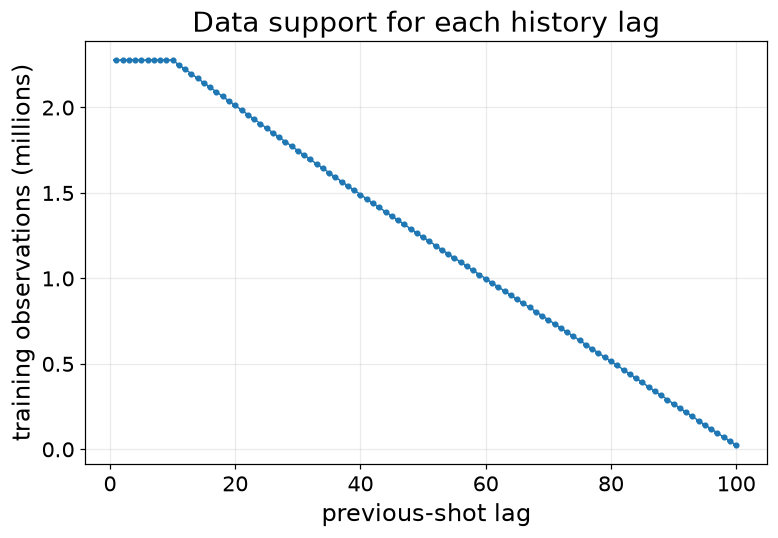

lag   1: 2,275,938 training observations (100.0% of lag-1 support)
lag   5: 2,275,938 training observations (100.0% of lag-1 support)
lag  10: 2,275,938 training observations (100.0% of lag-1 support)
lag  20: 2,010,686 training observations (88.3% of lag-1 support)
lag  40: 1,489,500 training observations (65.4% of lag-1 support)
lag  60: 997,621 training observations (43.8% of lag-1 support)
lag  80: 513,878 training observations (22.6% of lag-1 support)
lag 100: 23,466 training observations (1.0% of lag-1 support)


In [ ]:
# --- Diagnostic: how many training observations constrain each lag? ---

lags = np.arange(1,MAX_LAG+1)
lag_support = np.zeros((INDEP_CV_MOD,MAX_LAG),dtype=int)

for off in INDEP_CV_OFFSETS:
    train_rows = train_ids % INDEP_CV_MOD != off
    selected = common[train_rows]
    for d in lags: lag_support[off,d-1] = np.count_nonzero(selected[:,d:])

support_mean = lag_support.mean(axis=0)
support_sd = lag_support.std(axis=0,ddof=1)
support_fraction = support_mean/support_mean[0]

fig,ax = plt.subplots(figsize=(8,5))
ax.errorbar(lags,support_mean/1e6,yerr=support_sd/1e6,fmt="o-",ms=3,lw=1,capsize=2)
ax.set(xlabel="previous-shot lag",ylabel="training observations (millions)",title="Data support for each history lag")
ax.grid(alpha=0.25)
plt.show()

for d in [1,5,10,20,40,60,80,100]:
    if d <= MAX_LAG: print(f"lag {d:3d}: {support_mean[d-1]:,.0f} training observations ({100*support_fraction[d-1]:.1f}% of lag-1 support)")

### Does the previous bunches help predict a given bunch?

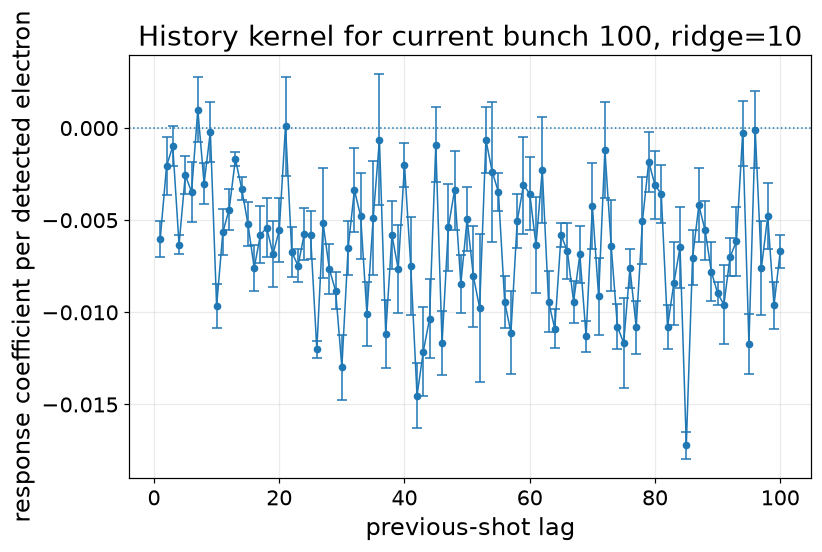

Current bunch index: 100
History available: lags 1–100
Training shots per fold: [np.int64(23465), np.int64(23447), np.int64(23486), np.int64(23459), np.int64(23471)]


In [ ]:
# --- Free history kernel for one chosen bunch position only ---

BUNCH_POSITION = 100  # bunch index, so 60 means the point labelled 60 on the existing plots
POSITION_RIDGE = 10

max_lag_pos = BUNCH_POSITION
K_pos = []

for off in INDEP_CV_OFFSETS:
    train_rows = train_ids % INDEP_CV_MOD != off
    selected = common[train_rows,BUNCH_POSITION]

    total = data["total_electrons"][train_rows]
    g = gmd[train_rows,BUNCH_POSITION]
    y = data["ref_counts"][train_rows,BUNCH_POSITION].astype(float)
    a,b = beta_cv["M0"][off]
    base = a+b*g

    use = selected & np.isfinite(base) & (base > 0)
    y,base = y[use],base[use]
    total = total[use]

    X = np.column_stack([total[:,BUNCH_POSITION-d] for d in range(1,max_lag_pos+1)]).astype(float)
    F = X*base[:,None]
    residual = y-base

    A = F.T@F
    z = F.T@residual
    scale = np.mean(np.diag(A)[np.diag(A) > 0])
    k = np.linalg.lstsq(A+POSITION_RIDGE*scale*np.eye(max_lag_pos),z,rcond=None)[0]
    K_pos.append(k)

K_pos = np.asarray(K_pos)
lags_pos = np.arange(1,max_lag_pos+1)

fig,ax = plt.subplots(figsize=(8,5))
ax.errorbar(lags_pos,K_pos.mean(axis=0),yerr=K_pos.std(axis=0,ddof=1),fmt="o-",ms=4,lw=1,capsize=3)
ax.axhline(0,ls=":",lw=1)
ax.set(xlabel="previous-shot lag",ylabel="response coefficient per detected electron",title=f"History kernel for current bunch {BUNCH_POSITION}, ridge={POSITION_RIDGE:g}")
ax.grid(alpha=0.25)
plt.show()

print(f"Current bunch index: {BUNCH_POSITION}")
print(f"History available: lags 1–{max_lag_pos}")
print("Training shots per fold:",[np.count_nonzero(common[train_ids % INDEP_CV_MOD != off,BUNCH_POSITION]) for off in INDEP_CV_OFFSETS])

### Testing history existence

In [ ]:
# --- Helpers for conditional history tests: control current bunch position first ---

def fit_bunch_baseline(g,y,selected,beta):
    """Current-GMD prediction times one multiplicative training factor per current bunch."""
    base0 = beta[0]+beta[1]*g
    factor = np.ones(g.shape[1],dtype=float)
    for b in range(g.shape[1]):
        use = selected[:,b] & np.isfinite(base0[:,b]) & (base0[:,b] > 0)
        den = base0[use,b].sum()
        if den > 0: factor[b] = y[use,b].sum()/den
    return base0*factor[None,:],factor

def apply_bunch_baseline(g,beta,factor):
    return (beta[0]+beta[1]*g)*factor[None,:]

def centre_by_bunch(x_train,x_test,selected_train):
    """Subtract the TRAINING mean at each current bunch position."""
    mu = np.zeros(x_train.shape[1],dtype=float)
    for b in range(x_train.shape[1]):
        use = selected_train[:,b] & np.isfinite(x_train[:,b])
        if np.any(use): mu[b] = np.mean(x_train[use,b])
    return x_train-mu[None,:],x_test-mu[None,:],mu

def grouped_history_features(total,windows):
    """Feature j = electrons in the requested previous-shot lag window."""
    n_trains,n_bunch = total.shape
    X = np.zeros((n_trains,n_bunch,len(windows)),dtype=float)
    for j,(d0,d1) in enumerate(windows):
        for b in range(n_bunch):
            lo,hi = max(0,b-d1),b-d0
            if hi >= 0 and hi >= lo: X[:,b,j] = total[:,lo:hi+1].sum(axis=1)
    return X

def centre_features_by_bunch(X_train,X_test,selected_train):
    mu = np.zeros((X_train.shape[1],X_train.shape[2]),dtype=float)
    for b in range(X_train.shape[1]):
        use = selected_train[:,b]
        if np.any(use): mu[b] = X_train[use,b].mean(axis=0)
    return X_train-mu[None,:,:],X_test-mu[None,:,:],mu

,alpha_mean,alpha_sd,baseline_mse,history_mse,ref MSE improvement (%),target slope,target flatness,target slope SD
tau,,,,,,,,
0.25,0.000000,0.000000,0.015675,0.015675,0.000000,-8.674948,0.246832,0.182107
0.50,0.000000,0.000000,0.015675,0.015675,0.000000,-8.674948,0.246832,0.182107
1.00,-0.000018,0.000000,0.015675,0.015675,0.000002,-8.674947,0.246832,0.182107
2.00,-0.088995,0.005346,0.015675,0.015672,0.017043,-8.657612,0.246692,0.185289
3.00,-0.076161,0.003303,0.015675,0.015671,0.023544,-8.651234,0.246632,0.185864
5.00,-0.066097,0.001532,0.015675,0.015670,0.033618,-8.642197,0.246530,0.187292
10.00,-0.048650,0.000866,0.015675,0.015667,0.047730,-8.659123,0.246821,0.190010
20.00,-0.034511,0.000492,0.015675,0.015666,0.057495,-8.736849,0.248139,0.189579
50.00,-0.022813,0.000204,0.015675,0.015665,0.060452,-8.893778,0.251260,0.186917


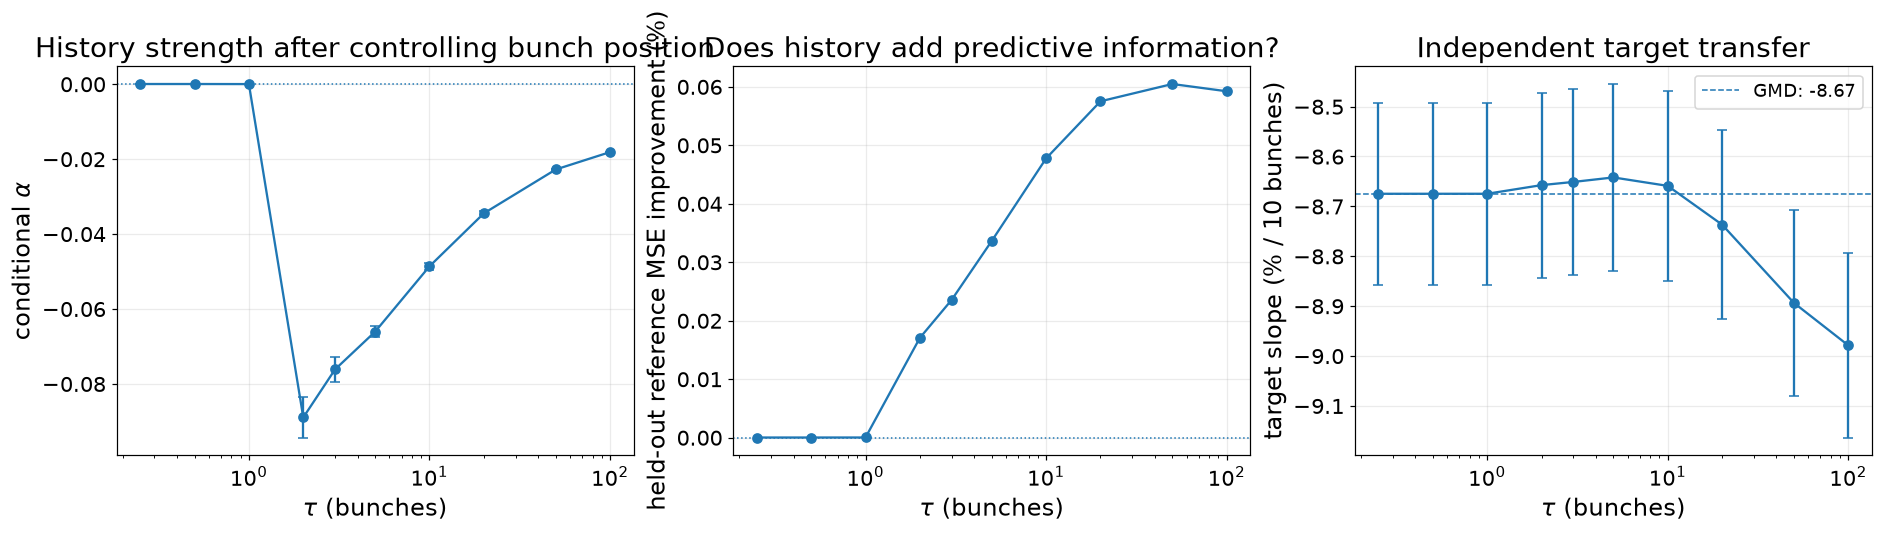

In [ ]:
# --- Conditional exponential-history test: does H add information AFTER bunch position is known? ---

COND_TAU_GRID = np.array([0.25,0.5,1,2,3,5,10,20,50,100],dtype=float)
COND_ALPHA_BOUNDS = (-0.5,0.5)

cond_exp_rows = []
shape = (INDEP_CV_MOD,len(INDEP_GMD_BANDS),n_bunch)
cond_exp_target = np.zeros(shape)
cond_exp_shots = np.zeros(shape)
cond_exp_gmd = np.zeros(shape)
cond_exp_norm = np.zeros((len(COND_TAU_GRID),*shape))

for off in INDEP_CV_OFFSETS:
    train_rows = train_ids % INDEP_CV_MOD != off
    test_rows = train_ids % INDEP_CV_MOD == off
    g_train,g_test = gmd[train_rows],gmd[test_rows]
    sel_train,sel_test = common[train_rows],common[test_rows]
    y_train,y_test = data["ref_counts"][train_rows].astype(float),data["ref_counts"][test_rows].astype(float)

    base_train,factor = fit_bunch_baseline(g_train,y_train,sel_train,beta_cv["M0"][off])
    base_test = apply_bunch_baseline(g_test,beta_cv["M0"][off],factor)
    use_train = sel_train & np.isfinite(base_train) & (base_train > 0)
    use_test = sel_test & np.isfinite(base_test) & (base_test > 0)
    baseline_mse = np.mean((y_test[use_test]-base_test[use_test])**2)

    cond_exp_target[off] = band_sums(data["target_counts"][test_rows],g_test,sel_test)
    cond_exp_shots[off] = band_sums(np.ones_like(g_test),g_test,sel_test)
    cond_exp_gmd[off] = band_sums(g_test,g_test,sel_test)

    for j,tau in enumerate(COND_TAU_GRID):
        H_train = electron_history(data["total_electrons"][train_rows],tau)
        H_test = electron_history(data["total_electrons"][test_rows],tau)
        H_train,H_test,_ = centre_by_bunch(H_train,H_test,sel_train)

        def loss(x):
            pred = base_train[use_train]*np.exp(-x[0]*H_train[use_train])
            return np.mean((y_train[use_train]-pred)**2)

        result = minimize(loss,[0.0],method="L-BFGS-B",bounds=[COND_ALPHA_BOUNDS])
        if not result.success: raise RuntimeError(result.message)

        alpha = float(result.x[0])
        pred_test = base_test[use_test]*np.exp(-alpha*H_test[use_test])
        ref_mse = np.mean((y_test[use_test]-pred_test)**2)
        R_test = np.exp(-alpha*H_test)

        cond_exp_norm[j,off] = band_sums(g_test*R_test,g_test,sel_test)
        cond_exp_rows.append({"fold":off,"tau":tau,"alpha":alpha,"baseline_mse":baseline_mse,"history_mse":ref_mse})

cond_exp = pd.DataFrame(cond_exp_rows)
cond_exp_summary = cond_exp.groupby("tau").agg(alpha_mean=("alpha","mean"),alpha_sd=("alpha","std"),baseline_mse=("baseline_mse","mean"),history_mse=("history_mse","mean"))
cond_exp_summary["ref MSE improvement (%)"] = 100*(1-cond_exp_summary["history_mse"]/cond_exp_summary["baseline_mse"])

obs = cond_exp_target.sum(axis=0)
shots = cond_exp_shots.sum(axis=0)
gmd_metric = bunch_metrics(obs,cond_exp_gmd.sum(axis=0),shots)
slopes,flatness,slope_sd = [],[],[]
for j,tau in enumerate(COND_TAU_GRID):
    m = bunch_metrics(obs,cond_exp_norm[j].sum(axis=0),shots)
    fm = [bunch_metrics(cond_exp_target[off],cond_exp_norm[j,off],cond_exp_shots[off]) for off in INDEP_CV_OFFSETS]
    slopes.append(m["slope"]); flatness.append(m["flatness"]); slope_sd.append(np.std([x["slope"] for x in fm],ddof=1))

cond_exp_summary["target slope"] = slopes
cond_exp_summary["target flatness"] = flatness
cond_exp_summary["target slope SD"] = slope_sd
display(cond_exp_summary.round(6))

fig,axes = plt.subplots(1,3,figsize=(17,4.5),constrained_layout=True)
axes[0].errorbar(COND_TAU_GRID,cond_exp_summary["alpha_mean"],yerr=cond_exp_summary["alpha_sd"],fmt="o-",capsize=3)
axes[0].axhline(0,ls=":",lw=1); axes[0].set(xscale="log",xlabel=r"$\tau$ (bunches)",ylabel=r"conditional $\alpha$",title="History strength after controlling bunch position"); axes[0].grid(alpha=0.25)
axes[1].plot(COND_TAU_GRID,cond_exp_summary["ref MSE improvement (%)"],"o-")
axes[1].axhline(0,ls=":",lw=1); axes[1].set(xscale="log",xlabel=r"$\tau$ (bunches)",ylabel="held-out reference MSE improvement (%)",title="Does history add predictive information?"); axes[1].grid(alpha=0.25)
axes[2].errorbar(COND_TAU_GRID,cond_exp_summary["target slope"],yerr=cond_exp_summary["target slope SD"],fmt="o-",capsize=3)
axes[2].axhline(gmd_metric["slope"],ls="--",lw=1,label=f"GMD: {gmd_metric['slope']:+.2f}")
axes[2].set(xscale="log",xlabel=r"$\tau$ (bunches)",ylabel="target slope (% / 10 bunches)",title="Independent target transfer"); axes[2].grid(alpha=0.25); axes[2].legend()
plt.show()

,baseline_mse,history_mse,min_R,ref MSE improvement (%),target slope,target flatness
ridge,,,,,,
0.0000,0.015675,0.015663,0.425108,0.077759,-8.743513,0.248738
0.0001,0.015675,0.015663,0.425119,0.077760,-8.743515,0.248737
0.0010,0.015675,0.015663,0.425222,0.077763,-8.743524,0.248736
0.0100,0.015675,0.015663,0.426293,0.077780,-8.743641,0.248728
0.1000,0.015675,0.015663,0.438601,0.077284,-8.745244,0.248669
1.0000,0.015675,0.015664,0.539106,0.069316,-8.744871,0.248358
10.0000,0.015675,0.015670,0.830832,0.033292,-8.705386,0.247405


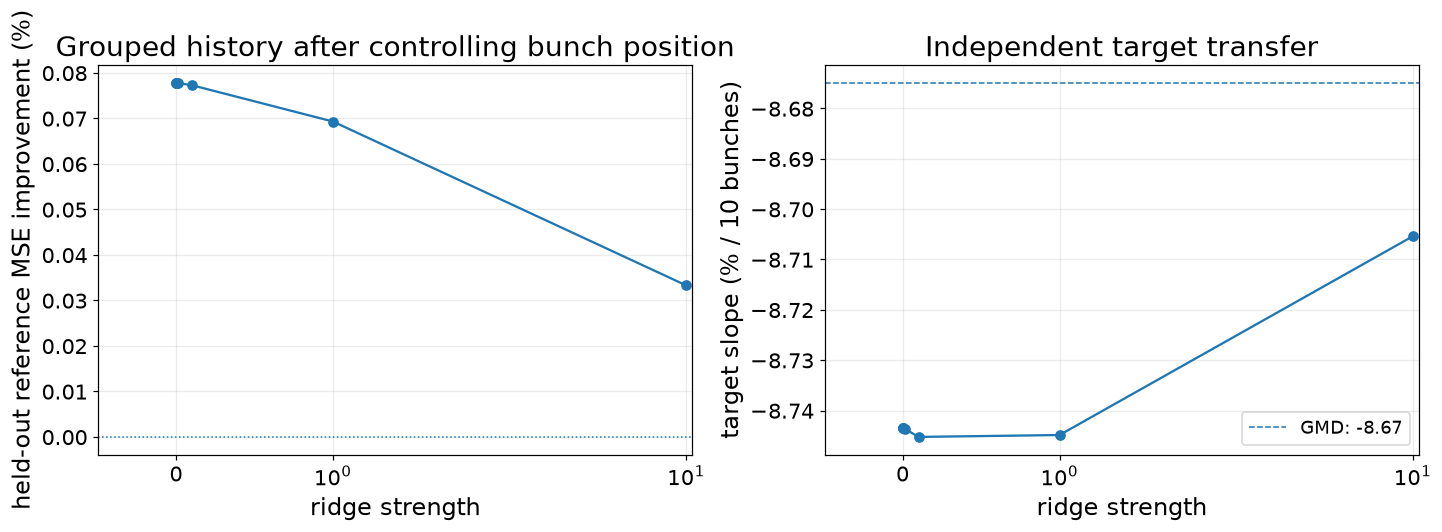

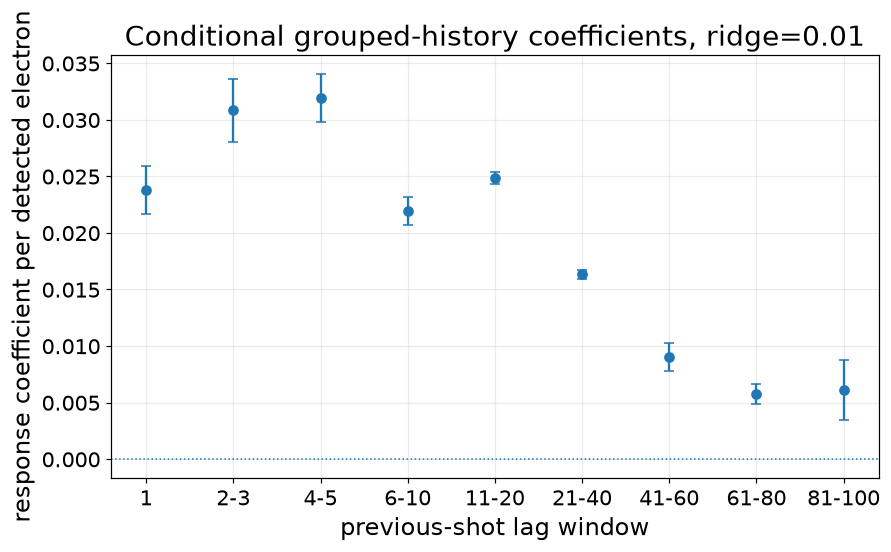

In [ ]:
# --- Conditional grouped-lag history: flexible test without 100 unstable coefficients ---

HISTORY_WINDOWS = [(1,1),(2,3),(4,5),(6,10),(11,20),(21,40),(41,60),(61,80),(81,100)]
COND_RIDGE_GRID = np.array([0,1e-4,1e-3,1e-2,1e-1,1,10],dtype=float)

group_rows = []
group_coeffs = {}
group_target = np.zeros(shape)
group_shots = np.zeros(shape)
group_gmd = np.zeros(shape)
group_norm = np.zeros((len(COND_RIDGE_GRID),*shape))

for off in INDEP_CV_OFFSETS:
    train_rows = train_ids % INDEP_CV_MOD != off
    test_rows = train_ids % INDEP_CV_MOD == off
    g_train,g_test = gmd[train_rows],gmd[test_rows]
    sel_train,sel_test = common[train_rows],common[test_rows]
    y_train,y_test = data["ref_counts"][train_rows].astype(float),data["ref_counts"][test_rows].astype(float)

    base_train,factor = fit_bunch_baseline(g_train,y_train,sel_train,beta_cv["M0"][off])
    base_test = apply_bunch_baseline(g_test,beta_cv["M0"][off],factor)
    use_train = sel_train & np.isfinite(base_train) & (base_train > 0)
    use_test = sel_test & np.isfinite(base_test) & (base_test > 0)
    baseline_mse = np.mean((y_test[use_test]-base_test[use_test])**2)

    X_train = grouped_history_features(data["total_electrons"][train_rows],HISTORY_WINDOWS)
    X_test = grouped_history_features(data["total_electrons"][test_rows],HISTORY_WINDOWS)
    X_train,X_test,_ = centre_features_by_bunch(X_train,X_test,sel_train)

    Xtr = X_train[use_train]
    rtr = y_train[use_train]-base_train[use_train]
    F = Xtr*base_train[use_train,None]
    A,z = F.T@F,F.T@rtr
    scale = np.mean(np.diag(A)[np.diag(A) > 0])

    group_target[off] = band_sums(data["target_counts"][test_rows],g_test,sel_test)
    group_shots[off] = band_sums(np.ones_like(g_test),g_test,sel_test)
    group_gmd[off] = band_sums(g_test,g_test,sel_test)

    for j,lam in enumerate(COND_RIDGE_GRID):
        k = np.linalg.lstsq(A+lam*scale*np.eye(len(HISTORY_WINDOWS)),z,rcond=None)[0]
        group_coeffs[(off,j)] = k
        R_test = 1+np.sum(X_test*k[None,None,:],axis=-1)
        if np.any(R_test[sel_test] <= 0): ref_mse = np.nan
        else: ref_mse = np.mean((y_test[use_test]-base_test[use_test]*R_test[use_test])**2)
        group_rows.append({"fold":off,"ridge":lam,"baseline_mse":baseline_mse,"history_mse":ref_mse,"min_R":np.nanmin(R_test[sel_test])})
        if np.all(R_test[sel_test] > 0): group_norm[j,off] = band_sums(g_test*R_test,g_test,sel_test)
        else: group_norm[j,off] = np.nan

group_df = pd.DataFrame(group_rows)
group_summary = group_df.groupby("ridge").agg(baseline_mse=("baseline_mse","mean"),history_mse=("history_mse","mean"),min_R=("min_R","min"))
group_summary["ref MSE improvement (%)"] = 100*(1-group_summary["history_mse"]/group_summary["baseline_mse"])

obs = group_target.sum(axis=0)
shots = group_shots.sum(axis=0)
gmd_group_metric = bunch_metrics(obs,group_gmd.sum(axis=0),shots)
group_slopes,group_flatness = [],[]
for j,lam in enumerate(COND_RIDGE_GRID):
    if np.any(~np.isfinite(group_norm[j])): group_slopes.append(np.nan); group_flatness.append(np.nan)
    else:
        m = bunch_metrics(obs,group_norm[j].sum(axis=0),shots)
        group_slopes.append(m["slope"]); group_flatness.append(m["flatness"])

group_summary["target slope"] = group_slopes
group_summary["target flatness"] = group_flatness
display(group_summary.round(6))

fig,axes = plt.subplots(1,2,figsize=(13,4.5),constrained_layout=True)
axes[0].plot(COND_RIDGE_GRID,group_summary["ref MSE improvement (%)"],"o-")
axes[0].axhline(0,ls=":",lw=1); axes[0].set(xscale="symlog",xlabel="ridge strength",ylabel="held-out reference MSE improvement (%)",title="Grouped history after controlling bunch position"); axes[0].grid(alpha=0.25)
axes[1].plot(COND_RIDGE_GRID,group_summary["target slope"],"o-")
axes[1].axhline(gmd_group_metric["slope"],ls="--",lw=1,label=f"GMD: {gmd_group_metric['slope']:+.2f}")
axes[1].set(xscale="symlog",xlabel="ridge strength",ylabel="target slope (% / 10 bunches)",title="Independent target transfer"); axes[1].grid(alpha=0.25); axes[1].legend()
plt.show()

best_j = int(np.nanargmin(group_summary["history_mse"].to_numpy()))
K_group = np.vstack([group_coeffs[(off,best_j)] for off in INDEP_CV_OFFSETS])
labels = [f"{a}" if a == b else f"{a}-{b}" for a,b in HISTORY_WINDOWS]

fig,ax = plt.subplots(figsize=(9,5))
ax.errorbar(np.arange(len(labels)),K_group.mean(axis=0),yerr=K_group.std(axis=0,ddof=1),fmt="o",capsize=3)
ax.axhline(0,ls=":",lw=1)
ax.set_xticks(np.arange(len(labels)),labels)
ax.set(xlabel="previous-shot lag window",ylabel="response coefficient per detected electron",title=f"Conditional grouped-history coefficients, ridge={COND_RIDGE_GRID[best_j]:g}")
ax.grid(alpha=0.25)
plt.show()

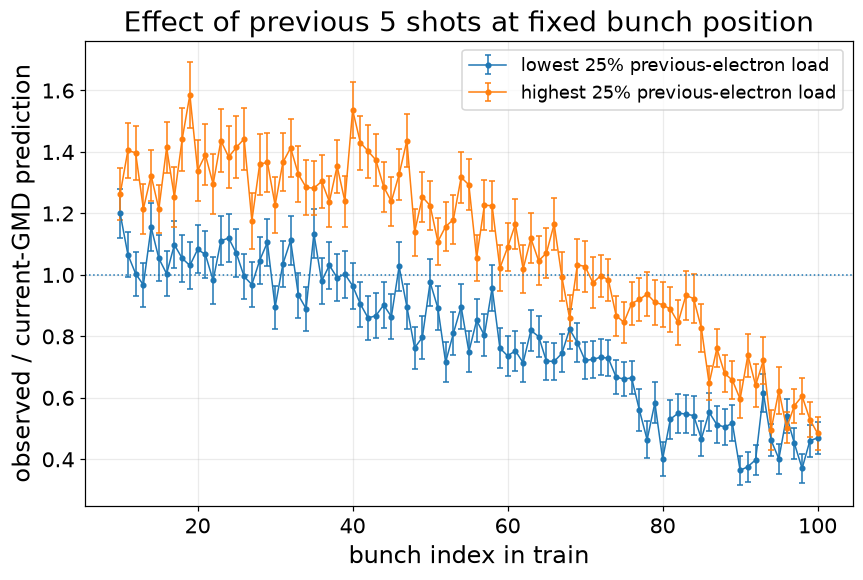

Mean high-history minus low-history response: +0.3000
RMS separation: 0.3266


In [ ]:
# --- Simple diagnostic: high vs low previous-electron history at fixed bunch position ---

HISTORY_SHOTS = 5
QUANTILE = 0.25

# Sum of detected electrons in the previous HISTORY_SHOTS shots; history never crosses trains.
H_simple = np.full_like(gmd,np.nan,dtype=float)
for b in range(HISTORY_SHOTS,n_bunch): H_simple[:,b] = data["total_electrons"][:,b-HISTORY_SHOTS:b].sum(axis=1)

# Held-out current-GMD prediction for every shot.
pred_cv = np.full_like(gmd,np.nan,dtype=float)
for off in INDEP_CV_OFFSETS:
    rows = train_ids % INDEP_CV_MOD == off
    pred_cv[rows] = designs["M0"][rows] @ beta_cv["M0"][off]

bunches = np.arange(max(INDEP_BUNCH_START,HISTORY_SHOTS),n_bunch)
low_response,high_response = [],[]
low_err,high_err = [],[]

for b in bunches:
    valid = common[:,b] & np.isfinite(H_simple[:,b]) & np.isfinite(pred_cv[:,b]) & (pred_cv[:,b] > 0)
    H = H_simple[valid,b]
    obs = data["ref_counts"][valid,b].astype(float)
    pred = pred_cv[valid,b]

    qlo,qhi = np.quantile(H,[QUANTILE,1-QUANTILE])
    low = H <= qlo
    high = H >= qhi

    low_response.append(obs[low].sum()/pred[low].sum())
    high_response.append(obs[high].sum()/pred[high].sum())
    low_err.append(np.sqrt(obs[low].sum())/pred[low].sum())
    high_err.append(np.sqrt(obs[high].sum())/pred[high].sum())

low_response,high_response = np.asarray(low_response),np.asarray(high_response)
low_err,high_err = np.asarray(low_err),np.asarray(high_err)

fig,ax = plt.subplots(figsize=(9,5.5))
ax.errorbar(bunches,low_response,yerr=low_err,fmt="o-",ms=3,lw=1,capsize=2,label=f"lowest {QUANTILE:.0%} previous-electron load")
ax.errorbar(bunches,high_response,yerr=high_err,fmt="o-",ms=3,lw=1,capsize=2,label=f"highest {QUANTILE:.0%} previous-electron load")
ax.axhline(1,ls=":",lw=1)
ax.set(xlabel="bunch index in train",ylabel="observed / current-GMD prediction",title=f"Effect of previous {HISTORY_SHOTS} shots at fixed bunch position")
ax.grid(alpha=0.25); ax.legend(); plt.show()

difference = high_response-low_response
print(f"Mean high-history minus low-history response: {np.nanmean(difference):+.4f}")
print(f"RMS separation: {np.sqrt(np.nanmean(difference**2)):.4f}")

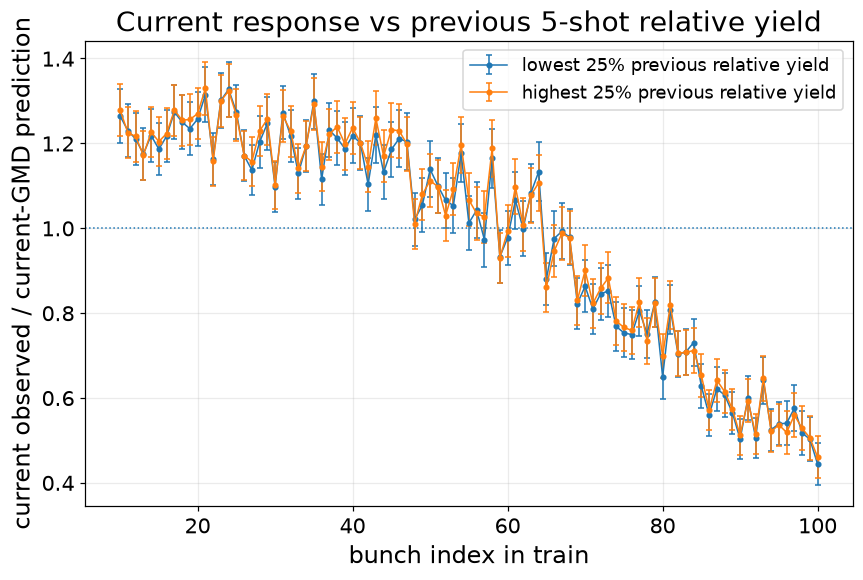

Mean high-history minus low-history current response: +0.0085
RMS separation: 0.0201
Mean previous-history score, low group:  0.000
Mean previous-history score, high group: 1.012


In [ ]:
# --- Simple conditional diagnostic using GMD-normalised history ---
# Previous-shot history = observed reference electrons / expected reference electrons from each shot's own GMD.

HISTORY_SHOTS = 5
QUANTILE = 0.25

# Held-out M0 prediction for every shot: prediction uses parameters learned from the other folds.
pred_cv = np.full_like(gmd,np.nan,dtype=float)
for off in INDEP_CV_OFFSETS:
    rows = train_ids % INDEP_CV_MOD == off
    pred_cv[rows] = designs["M0"][rows] @ beta_cv["M0"][off]

bunches = np.arange(max(INDEP_BUNCH_START,HISTORY_SHOTS),n_bunch)
low_response,high_response,low_err,high_err = [],[],[],[]
history_low,history_high = [],[]

for b in bunches:
    prev = slice(b-HISTORY_SHOTS,b)

    # Require all previous shots to have valid GMD and positive M0 predictions.
    prev_valid = np.all(np.isfinite(pred_cv[:,prev]) & (pred_cv[:,prev] > 0) &
                        np.isfinite(gmd[:,prev]) & (gmd[:,prev] >= INDEP_GMD_RANGE[0]) &
                        (gmd[:,prev] < INDEP_GMD_RANGE[1]),axis=1)

    current_valid = common[:,b] & np.isfinite(pred_cv[:,b]) & (pred_cv[:,b] > 0)
    valid = prev_valid & current_valid

    # Previous 5-shot yield relative to what those shots' own GMD values predict.
    prev_obs = data["ref_counts"][valid,prev].sum(axis=1).astype(float)
    prev_pred = pred_cv[valid,prev].sum(axis=1)
    history = prev_obs/prev_pred

    qlo,qhi = np.quantile(history,[QUANTILE,1-QUANTILE])
    low,high = history <= qlo,history >= qhi

    obs_now = data["ref_counts"][valid,b].astype(float)
    pred_now = pred_cv[valid,b]

    low_response.append(obs_now[low].sum()/pred_now[low].sum())
    high_response.append(obs_now[high].sum()/pred_now[high].sum())
    low_err.append(np.sqrt(obs_now[low].sum())/pred_now[low].sum())
    high_err.append(np.sqrt(obs_now[high].sum())/pred_now[high].sum())
    history_low.append(np.mean(history[low]))
    history_high.append(np.mean(history[high]))

low_response,high_response,low_err,high_err = map(np.asarray,(low_response,high_response,low_err,high_err))

fig,ax = plt.subplots(figsize=(9,5.5))
ax.errorbar(bunches,low_response,yerr=low_err,fmt="o-",ms=3,lw=1,capsize=2,label=f"lowest {QUANTILE:.0%} previous relative yield")
ax.errorbar(bunches,high_response,yerr=high_err,fmt="o-",ms=3,lw=1,capsize=2,label=f"highest {QUANTILE:.0%} previous relative yield")
ax.axhline(1,ls=":",lw=1)
ax.set(xlabel="bunch index in train",ylabel="current observed / current-GMD prediction",title=f"Current response vs previous {HISTORY_SHOTS}-shot relative yield")
ax.grid(alpha=0.25); ax.legend(); plt.show()

difference = high_response-low_response
print(f"Mean high-history minus low-history current response: {np.nanmean(difference):+.4f}")
print(f"RMS separation: {np.sqrt(np.nanmean(difference**2)):.4f}")
print(f"Mean previous-history score, low group:  {np.mean(history_low):.3f}")
print(f"Mean previous-history score, high group: {np.mean(history_high):.3f}")

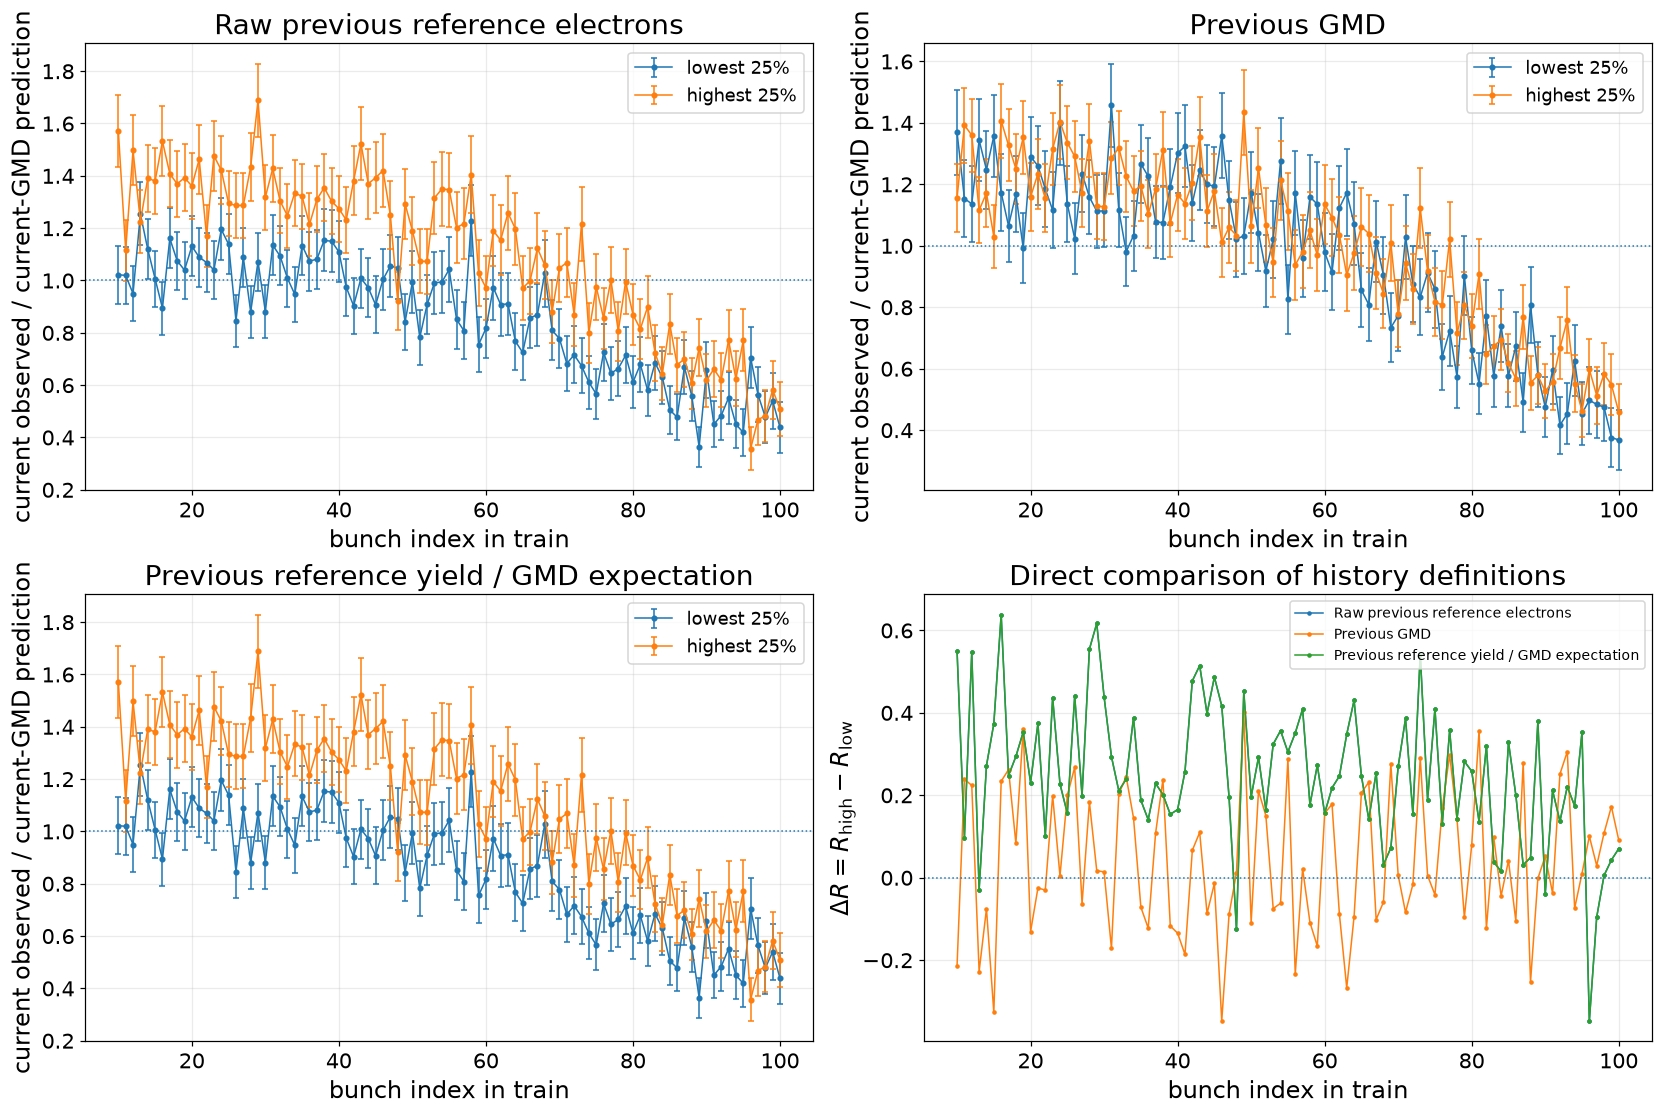

Previous-5 mean GMD vs current GMD correlation: raw=+0.2217, within-bunch=+0.1642
Raw previous-reference history: zero-count fraction = 92.4% mean, 96.6% maximum


In [ ]:
# --- Apples-to-apples history diagnostic: raw reference counts, previous GMD, GMD-corrected reference yield ---

HISTORY_SHOTS = 5
QUANTILE = 0.25

# Held-out M0 prediction for every shot.
pred_cv = np.full_like(gmd,np.nan,dtype=float)
for off in INDEP_CV_OFFSETS:
    rows = train_ids % INDEP_CV_MOD == off
    pred_cv[rows] = designs["M0"][rows] @ beta_cv["M0"][off]

def build_history_scores(window):
    H_raw = np.full_like(gmd,np.nan,dtype=float)
    H_gmd = np.full_like(gmd,np.nan,dtype=float)
    H_rel = np.full_like(gmd,np.nan,dtype=float)
    prev_valid = np.zeros_like(gmd,dtype=bool)

    for b in range(window,n_bunch):
        prev = slice(b-window,b)
        valid = np.all(np.isfinite(gmd[:,prev]) & (gmd[:,prev] >= INDEP_GMD_RANGE[0]) & (gmd[:,prev] < INDEP_GMD_RANGE[1]) & np.isfinite(pred_cv[:,prev]) & (pred_cv[:,prev] > 0),axis=1)
        obs_sum = data["ref_counts"][:,prev].sum(axis=1).astype(float)
        pred_sum = pred_cv[:,prev].sum(axis=1)
        H_raw[valid,b] = obs_sum[valid]
        H_gmd[valid,b] = gmd[:,prev].sum(axis=1)[valid]
        H_rel[valid,b] = obs_sum[valid]/pred_sum[valid]
        prev_valid[valid,b] = True

    return H_raw,H_gmd,H_rel,prev_valid

def high_low_response(score,prev_valid,q=0.25,row_mask=None,gmd_match=False):
    if row_mask is None: row_mask = np.ones(gmd.shape[0],dtype=bool)
    bunches = np.arange(max(INDEP_BUNCH_START,HISTORY_SHOTS),n_bunch)
    low_r,high_r,low_e,high_e,n_group = [],[],[],[],[]

    for b in bunches:
        valid = row_mask & common[:,b] & prev_valid[:,b] & np.isfinite(score[:,b]) & np.isfinite(pred_cv[:,b]) & (pred_cv[:,b] > 0)
        low_idx,high_idx = [],[]

        if gmd_match:
            for lo,hi in INDEP_GMD_BANDS:
                idx = np.flatnonzero(valid & (gmd[:,b] >= lo) & (gmd[:,b] < hi))
                if idx.size < 4: continue
                order = np.argsort(score[idx,b],kind="mergesort")
                n = max(1,int(np.floor(q*idx.size)))
                low_idx.extend(idx[order[:n]])
                high_idx.extend(idx[order[-n:]])
        else:
            idx = np.flatnonzero(valid)
            if idx.size < 4:
                low_r.append(np.nan); high_r.append(np.nan); low_e.append(np.nan); high_e.append(np.nan); n_group.append(0); continue
            order = np.argsort(score[idx,b],kind="mergesort")
            n = max(1,int(np.floor(q*idx.size)))
            low_idx,high_idx = idx[order[:n]],idx[order[-n:]]

        low_idx,high_idx = np.asarray(low_idx,dtype=int),np.asarray(high_idx,dtype=int)
        obs_low,obs_high = data["ref_counts"][low_idx,b].sum(),data["ref_counts"][high_idx,b].sum()
        pred_low,pred_high = pred_cv[low_idx,b].sum(),pred_cv[high_idx,b].sum()

        low_r.append(obs_low/pred_low); high_r.append(obs_high/pred_high)
        low_e.append(np.sqrt(obs_low)/pred_low); high_e.append(np.sqrt(obs_high)/pred_high)
        n_group.append(min(low_idx.size,high_idx.size))

    return bunches,np.asarray(low_r),np.asarray(high_r),np.asarray(low_e),np.asarray(high_e),np.asarray(n_group)

H_raw,H_gmd,H_rel,prev_valid = build_history_scores(HISTORY_SHOTS)
results = {
    "Raw previous reference electrons":high_low_response(H_raw,prev_valid),
    "Previous GMD":high_low_response(H_gmd,prev_valid),
    "Previous reference yield / GMD expectation":high_low_response(H_rel,prev_valid)
}

fig,axes = plt.subplots(2,2,figsize=(15,10),constrained_layout=True)
for ax,(name,(b,lo,hi,elo,ehi,n)) in zip(axes.flat[:3],results.items()):
    ax.errorbar(b,lo,yerr=elo,fmt="o-",ms=3,lw=1,capsize=2,label=f"lowest {QUANTILE:.0%}")
    ax.errorbar(b,hi,yerr=ehi,fmt="o-",ms=3,lw=1,capsize=2,label=f"highest {QUANTILE:.0%}")
    ax.axhline(1,ls=":",lw=1); ax.set(xlabel="bunch index in train",ylabel="current observed / current-GMD prediction",title=name); ax.grid(alpha=0.25); ax.legend()

ax = axes[1,1]
for name,(b,lo,hi,elo,ehi,n) in results.items(): ax.plot(b,hi-lo,".-",ms=4,lw=1,label=name)
ax.axhline(0,ls=":",lw=1); ax.set(xlabel="bunch index in train",ylabel=r"$\Delta R=R_{\rm high}-R_{\rm low}$",title="Direct comparison of history definitions"); ax.grid(alpha=0.25); ax.legend(fontsize=9)
plt.show()

# Previous-GMD/current-GMD correlations.
mask = common & prev_valid
prev_mean_gmd = H_gmd/HISTORY_SHOTS
r_raw = np.corrcoef(prev_mean_gmd[mask],gmd[mask])[0,1]
x_demean,y_demean = [],[]
for b in range(max(INDEP_BUNCH_START,HISTORY_SHOTS),n_bunch):
    use = mask[:,b]
    if np.count_nonzero(use) < 2: continue
    x = prev_mean_gmd[use,b]; y = gmd[use,b]
    x_demean.append(x-x.mean()); y_demean.append(y-y.mean())
r_within = np.corrcoef(np.concatenate(x_demean),np.concatenate(y_demean))[0,1]

zero_fraction = [np.mean(H_raw[common[:,b] & prev_valid[:,b],b] == 0) for b in range(max(INDEP_BUNCH_START,HISTORY_SHOTS),n_bunch)]
print(f"Previous-5 mean GMD vs current GMD correlation: raw={r_raw:+.4f}, within-bunch={r_within:+.4f}")
print(f"Raw previous-reference history: zero-count fraction = {np.nanmean(zero_fraction):.1%} mean, {np.nanmax(zero_fraction):.1%} maximum")

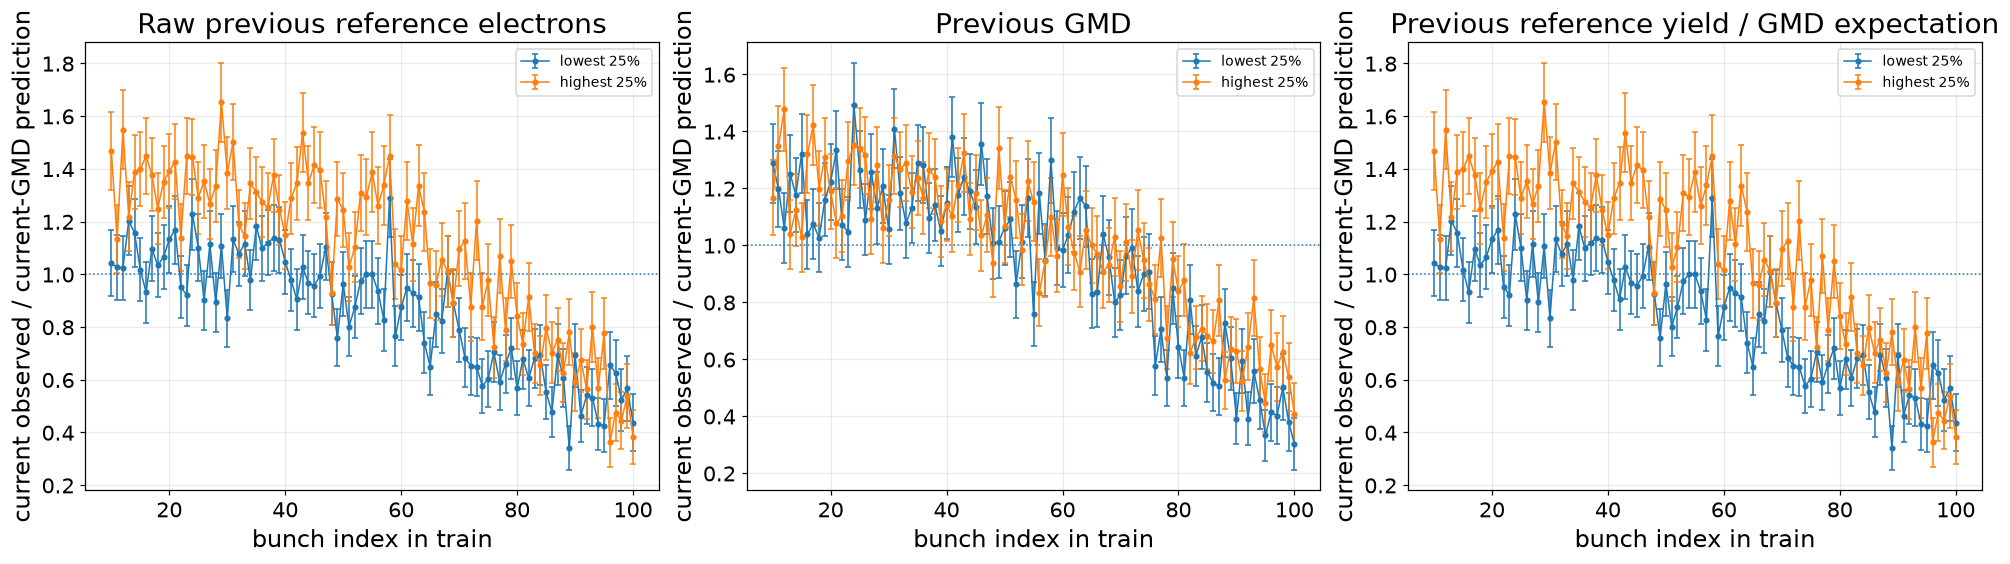

Mean high-minus-low response after current-GMD matching:
Raw previous reference electrons          : +0.2415
Previous GMD                              : +0.0548
Previous reference yield / GMD expectation: +0.2415


In [ ]:
# --- Robustness: high/low history after matching current GMD band at each bunch position ---

matched_results = {
    "Raw previous reference electrons":high_low_response(H_raw,prev_valid,gmd_match=True),
    "Previous GMD":high_low_response(H_gmd,prev_valid,gmd_match=True),
    "Previous reference yield / GMD expectation":high_low_response(H_rel,prev_valid,gmd_match=True)
}

fig,axes = plt.subplots(1,3,figsize=(18,5),constrained_layout=True)
for ax,(name,(b,lo,hi,elo,ehi,n)) in zip(axes,matched_results.items()):
    ax.errorbar(b,lo,yerr=elo,fmt="o-",ms=3,lw=1,capsize=2,label=f"lowest {QUANTILE:.0%}")
    ax.errorbar(b,hi,yerr=ehi,fmt="o-",ms=3,lw=1,capsize=2,label=f"highest {QUANTILE:.0%}")
    ax.axhline(1,ls=":",lw=1); ax.set(xlabel="bunch index in train",ylabel="current observed / current-GMD prediction",title=name); ax.grid(alpha=0.25); ax.legend(fontsize=9)
plt.show()

print("Mean high-minus-low response after current-GMD matching:")
for name,(b,lo,hi,elo,ehi,n) in matched_results.items():
    print(f"{name:42s}: {np.nanmean(hi-lo):+.4f}")

,window,history,mean delta R,RMS delta R,median group size
0,1,raw reference electrons,0.26096,0.29686,6818.0
1,1,previous GMD,0.03387,0.14253,6818.0
2,1,GMD-corrected reference yield,0.26096,0.29686,6818.0
3,5,raw reference electrons,0.24965,0.30276,4283.0
4,5,previous GMD,0.04085,0.17485,4283.0
5,5,GMD-corrected reference yield,0.24965,0.30276,4283.0
6,10,raw reference electrons,0.26374,0.34458,2497.0
7,10,previous GMD,0.00188,0.22818,2497.0
8,10,GMD-corrected reference yield,0.26374,0.34458,2497.0
9,20,raw reference electrons,0.22286,0.45533,982.0


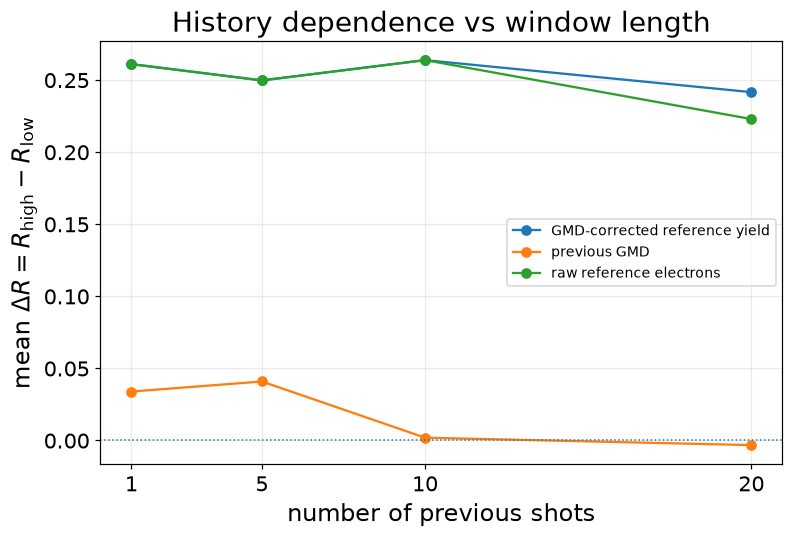

In [ ]:
# --- Robustness: compare history windows of 1, 5, 10 and 20 previous shots ---

HISTORY_WINDOWS_TEST = [1,5,10,20]
window_rows = []

for window in HISTORY_WINDOWS_TEST:
    old_window = HISTORY_SHOTS
    HISTORY_SHOTS = window
    Hraw,Hgmd,Hrel,pvalid = build_history_scores(window)

    for name,H in [("raw reference electrons",Hraw),("previous GMD",Hgmd),("GMD-corrected reference yield",Hrel)]:
        b,lo,hi,elo,ehi,n = high_low_response(H,pvalid)
        delta = hi-lo
        window_rows.append({"window":window,"history":name,"mean delta R":np.nanmean(delta),"RMS delta R":np.sqrt(np.nanmean(delta**2)),"median group size":np.nanmedian(n)})

    HISTORY_SHOTS = old_window

window_table = pd.DataFrame(window_rows)
display(window_table.round(5))

fig,ax = plt.subplots(figsize=(8,5))
for name,group in window_table.groupby("history"): ax.plot(group["window"],group["mean delta R"],"o-",label=name)
ax.axhline(0,ls=":",lw=1)
ax.set(xlabel="number of previous shots",ylabel=r"mean $\Delta R=R_{\rm high}-R_{\rm low}$",title="History dependence vs window length")
ax.set_xticks(HISTORY_WINDOWS_TEST)
ax.grid(alpha=0.25); ax.legend(fontsize=9); plt.show()

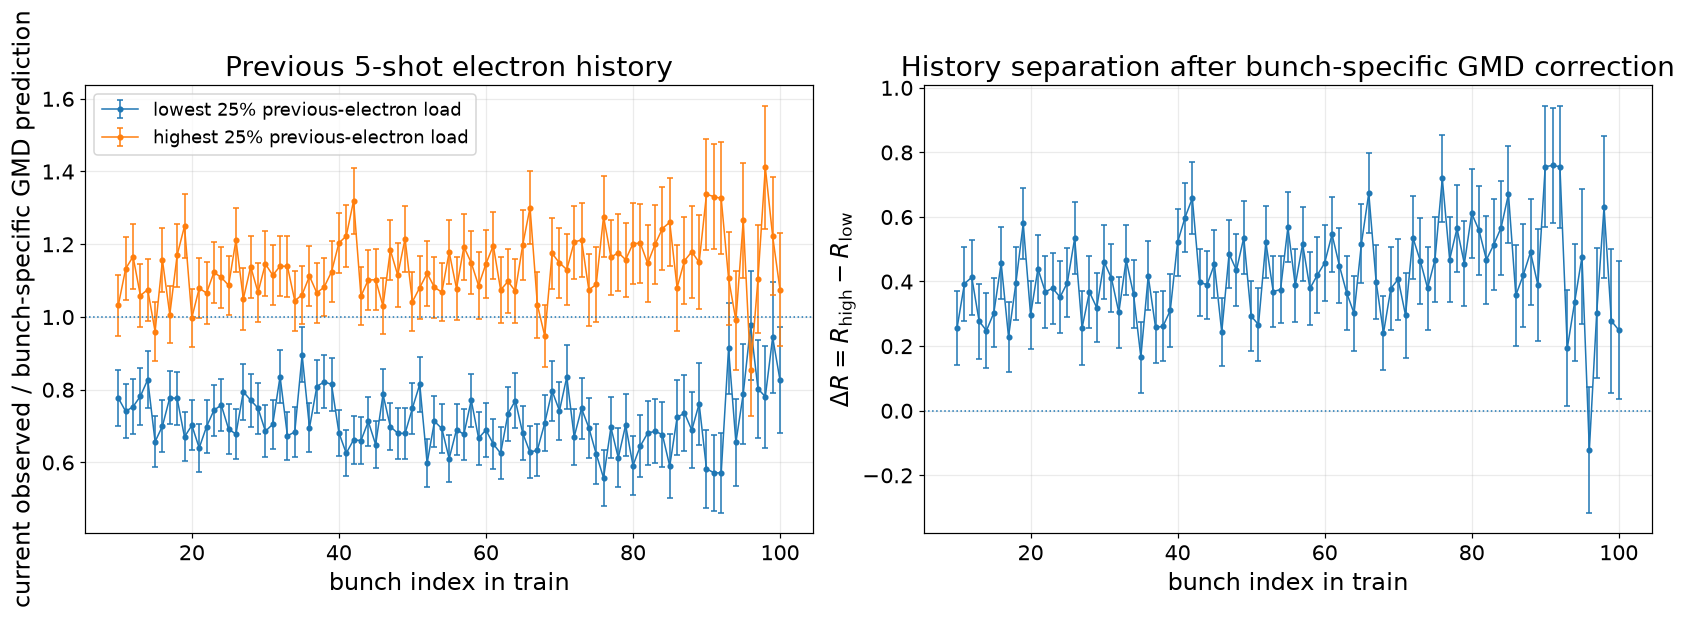

Mean high-minus-low response: +0.4198
RMS high-minus-low response:  0.4437
Median shots per group:       7744


In [ ]:
# --- Does raw previous-electron history still predict the current response after bunch-specific GMD correction? ---

HISTORY_SHOTS = 5
QUANTILE = 0.25

H_ref = np.full_like(gmd,np.nan,dtype=float)
for b in range(HISTORY_SHOTS,n_bunch):
    H_ref[:,b] = data["total_electrons"][:,b-HISTORY_SHOTS:b].sum(axis=1)

bunches = np.arange(max(INDEP_BUNCH_START,HISTORY_SHOTS),n_bunch)
low_response,high_response,low_err,high_err,n_low,n_high = [],[],[],[],[],[]

for b in bunches:
    valid = common[:,b] & np.isfinite(H_ref[:,b]) & np.isfinite(local_pred_cv[:,b]) & (local_pred_cv[:,b] > 0)
    idx = np.flatnonzero(valid)

    if idx.size < 4:
        low_response.append(np.nan); high_response.append(np.nan)
        low_err.append(np.nan); high_err.append(np.nan)
        n_low.append(0); n_high.append(0)
        continue

    order = np.argsort(H_ref[idx,b],kind="mergesort")
    n = max(1,int(np.floor(QUANTILE*idx.size)))
    low_idx = idx[order[:n]]
    high_idx = idx[order[-n:]]

    obs_low = data["ref_counts"][low_idx,b].sum()
    obs_high = data["ref_counts"][high_idx,b].sum()
    pred_low = local_pred_cv[low_idx,b].sum()
    pred_high = local_pred_cv[high_idx,b].sum()

    low_response.append(obs_low/pred_low)
    high_response.append(obs_high/pred_high)
    low_err.append(np.sqrt(obs_low)/pred_low if obs_low > 0 else np.nan)
    high_err.append(np.sqrt(obs_high)/pred_high if obs_high > 0 else np.nan)
    n_low.append(low_idx.size); n_high.append(high_idx.size)

low_response,high_response,low_err,high_err = map(np.asarray,(low_response,high_response,low_err,high_err))
delta = high_response-low_response
delta_err = np.sqrt(low_err**2+high_err**2)

fig,axes = plt.subplots(1,2,figsize=(15,5),constrained_layout=True)

axes[0].errorbar(bunches,low_response,yerr=low_err,fmt="o-",ms=3,lw=1,capsize=2,label=f"lowest {QUANTILE:.0%} previous-electron load")
axes[0].errorbar(bunches,high_response,yerr=high_err,fmt="o-",ms=3,lw=1,capsize=2,label=f"highest {QUANTILE:.0%} previous-electron load")
axes[0].axhline(1,ls=":",lw=1)
axes[0].set(xlabel="bunch index in train",ylabel="current observed / bunch-specific GMD prediction",title=f"Previous {HISTORY_SHOTS}-shot electron history")
axes[0].grid(alpha=0.25); axes[0].legend()

axes[1].errorbar(bunches,delta,yerr=delta_err,fmt="o-",ms=3,lw=1,capsize=2)
axes[1].axhline(0,ls=":",lw=1)
axes[1].set(xlabel="bunch index in train",ylabel=r"$\Delta R=R_{\rm high}-R_{\rm low}$",title="History separation after bunch-specific GMD correction")
axes[1].grid(alpha=0.25)

plt.show()

print(f"Mean high-minus-low response: {np.nanmean(delta):+.4f}")
print(f"RMS high-minus-low response:  {np.sqrt(np.nanmean(delta**2)):.4f}")
print(f"Median shots per group:       {np.median(n_low):.0f}")

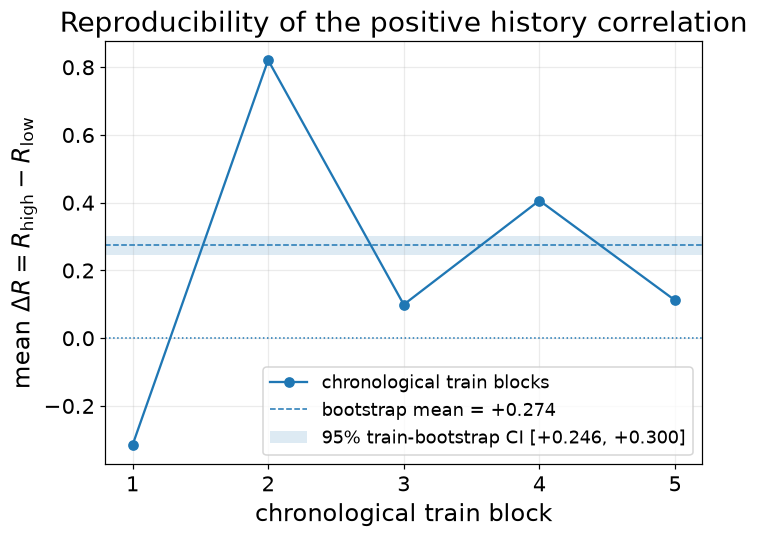

Block ΔR: [-0.3163  0.8205  0.0986  0.4059  0.1113]
Whole-train bootstrap: mean=+0.2743, 95% CI=[+0.2465, +0.2998]


In [ ]:
# --- Robustness: history separation across train blocks + whole-train bootstrap ---

N_BLOCKS = 5
N_BOOTSTRAP = 500
rng = np.random.default_rng(12345)

def history_delta_for_rows(rows):
    delta_b = []
    for b in bunches_hist:
        valid_b = rows & common[:,b] & np.isfinite(H_ref[:,b]) & np.isfinite(local_pred_cv[:,b]) & (local_pred_cv[:,b] > 0)
        idx = np.flatnonzero(valid_b)
        if idx.size < 8: continue
        order = np.argsort(H_ref[idx,b],kind="mergesort")
        n = max(1,int(np.floor(QUANTILE*idx.size)))
        low,high = idx[order[:n]],idx[order[-n:]]
        r_low = data["ref_counts"][low,b].sum()/local_pred_cv[low,b].sum()
        r_high = data["ref_counts"][high,b].sum()/local_pred_cv[high,b].sum()
        delta_b.append(r_high-r_low)
    return np.nanmean(delta_b)

blocks = np.array_split(np.arange(gmd.shape[0]),N_BLOCKS)
block_delta = []
for idx in blocks:
    rows = np.zeros(gmd.shape[0],dtype=bool)
    rows[idx] = True
    block_delta.append(history_delta_for_rows(rows))

# Fixed full-data high/low memberships for efficient whole-train bootstrap.
low_mask = np.zeros_like(common,dtype=bool)
high_mask = np.zeros_like(common,dtype=bool)
for b in bunches_hist:
    valid_b = common[:,b] & np.isfinite(H_ref[:,b]) & np.isfinite(local_pred_cv[:,b]) & (local_pred_cv[:,b] > 0)
    idx = np.flatnonzero(valid_b)
    order = np.argsort(H_ref[idx,b],kind="mergesort")
    n = max(1,int(np.floor(QUANTILE*idx.size)))
    low_mask[idx[order[:n]],b] = True
    high_mask[idx[order[-n:]],b] = True

obs = data["ref_counts"].astype(float)
obs_low_train = np.sum(np.where(low_mask,obs,0),axis=1)
obs_high_train = np.sum(np.where(high_mask,obs,0),axis=1)
pred_low_train = np.sum(np.where(low_mask,local_pred_cv,0),axis=1)
pred_high_train = np.sum(np.where(high_mask,local_pred_cv,0),axis=1)

boot_delta = np.empty(N_BOOTSTRAP)
for i in range(N_BOOTSTRAP):
    idx = rng.integers(0,gmd.shape[0],gmd.shape[0])
    r_low = obs_low_train[idx].sum()/pred_low_train[idx].sum()
    r_high = obs_high_train[idx].sum()/pred_high_train[idx].sum()
    boot_delta[i] = r_high-r_low

ci_low,ci_high = np.percentile(boot_delta,[2.5,97.5])

fig,ax = plt.subplots(figsize=(7,5))
ax.plot(np.arange(1,N_BLOCKS+1),block_delta,"o-",label="chronological train blocks")
ax.axhline(np.mean(boot_delta),ls="--",lw=1,label=f"bootstrap mean = {np.mean(boot_delta):+.3f}")
ax.axhspan(ci_low,ci_high,alpha=0.15,label=f"95% train-bootstrap CI [{ci_low:+.3f}, {ci_high:+.3f}]")
ax.axhline(0,ls=":",lw=1)
ax.set_xticks(np.arange(1,N_BLOCKS+1))
ax.set(xlabel="chronological train block",ylabel=r"mean $\Delta R=R_{\rm high}-R_{\rm low}$",title="Reproducibility of the positive history correlation")
ax.grid(alpha=0.25); ax.legend(); plt.show()

print("Block ΔR:",np.round(block_delta,4))
print(f"Whole-train bootstrap: mean={np.mean(boot_delta):+.4f}, 95% CI=[{ci_low:+.4f}, {ci_high:+.4f}]")

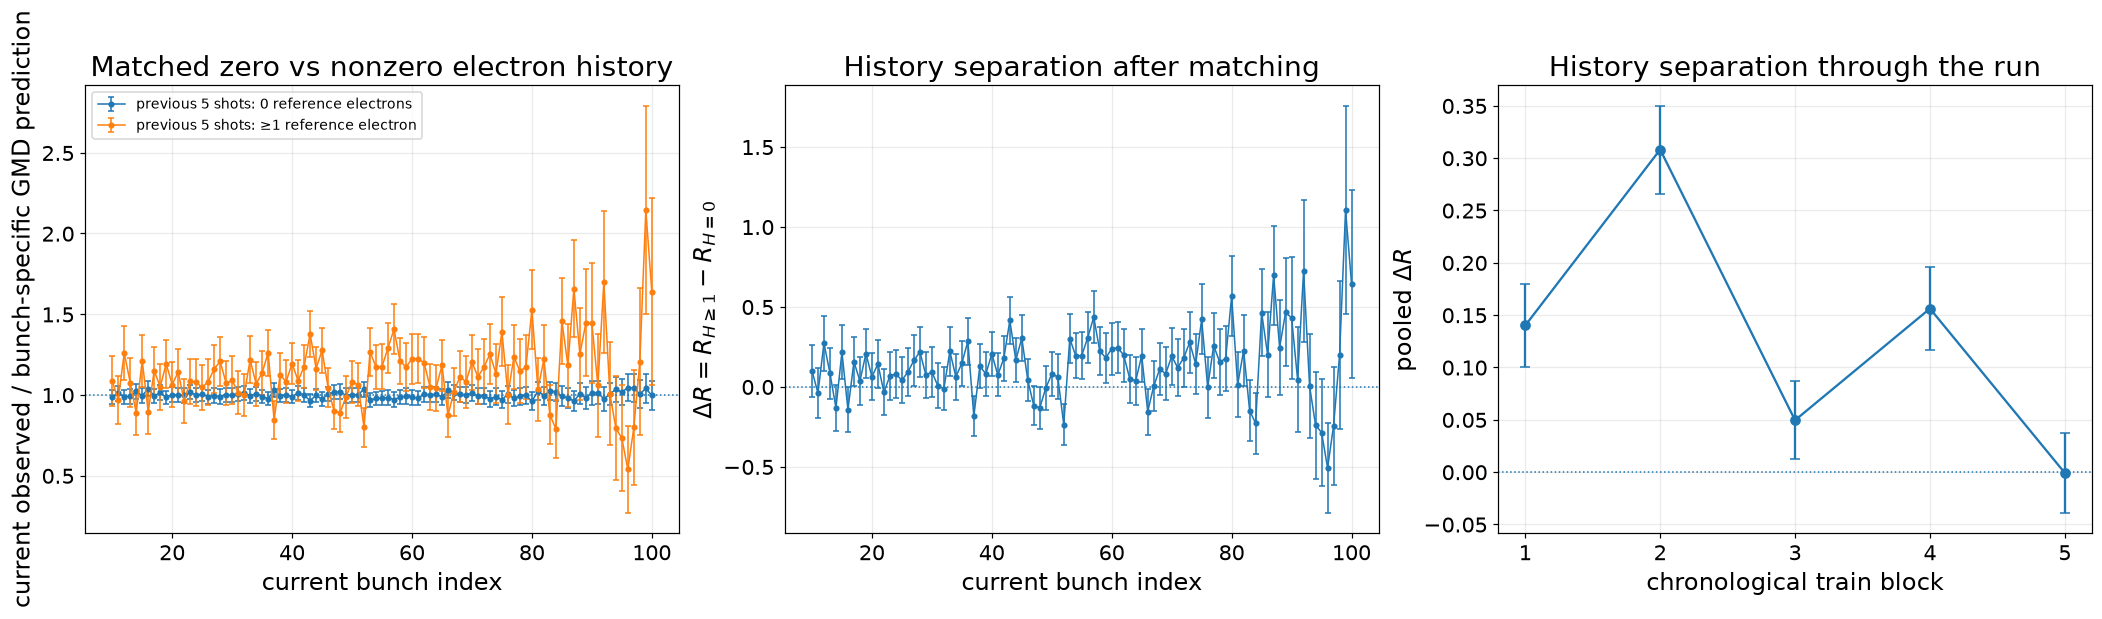

Overall matched H=0 response:  0.9977
Overall matched H>=1 response: 1.1203
Overall matched ΔR:            +0.1225 ± 0.0175
Total effective matched shots per group: 230,306
Block ΔR: [ 0.14    0.3081  0.0495  0.1562 -0.0009]


In [ ]:
# --- Clean history test: H=0 vs H>=1, matched in bunch position, current GMD and run block ---

HISTORY_SHOTS = 5
N_TIME_BLOCKS = 5
MATCH_GMD_STEP = 1.0
MIN_PER_GROUP = 5

# Reference-electron history: actual number of 190–220 eV electrons in the previous 5 shots.
H_ref = np.full_like(gmd,np.nan,dtype=float)
for b in range(HISTORY_SHOTS,n_bunch): H_ref[:,b] = data["ref_counts"][:,b-HISTORY_SHOTS:b].sum(axis=1)

# Chronological train blocks.
block_id = np.empty(gmd.shape[0],dtype=int)
for k,idx in enumerate(np.array_split(np.arange(gmd.shape[0]),N_TIME_BLOCKS)): block_id[idx] = k

# Fine current-GMD bins used only for matching H=0 and H>=1 populations.
gmd_edges = np.arange(INDEP_GMD_RANGE[0],INDEP_GMD_RANGE[1]+MATCH_GMD_STEP,MATCH_GMD_STEP)
bunches = np.arange(max(INDEP_BUNCH_START,HISTORY_SHOTS),n_bunch)

def matched_history_stats(blocks=None):
    if blocks is None: blocks = np.arange(N_TIME_BLOCKS)

    obs0 = np.zeros(n_bunch); pred0 = np.zeros(n_bunch); var0 = np.zeros(n_bunch)
    obs1 = np.zeros(n_bunch); pred1 = np.zeros(n_bunch); var1 = np.zeros(n_bunch)
    effective = np.zeros(n_bunch)

    for b in bunches:
        base_valid = common[:,b] & np.isfinite(H_ref[:,b]) & np.isfinite(local_pred_cv[:,b]) & (local_pred_cv[:,b] > 0)

        for block in blocks:
            for lo,hi in zip(gmd_edges[:-1],gmd_edges[1:]):
                use = base_valid & (block_id == block) & (gmd[:,b] >= lo) & (gmd[:,b] < hi)
                idx0 = np.flatnonzero(use & (H_ref[:,b] == 0))
                idx1 = np.flatnonzero(use & (H_ref[:,b] >= 1))
                m = min(idx0.size,idx1.size)
                if m < MIN_PER_GROUP: continue

                # Give the two history groups equal effective weight inside each
                # bunch × time-block × current-GMD stratum.
                w0,w1 = m/idx0.size,m/idx1.size
                y0 = data["ref_counts"][idx0,b].astype(float)
                y1 = data["ref_counts"][idx1,b].astype(float)

                obs0[b] += w0*y0.sum(); pred0[b] += w0*local_pred_cv[idx0,b].sum(); var0[b] += w0**2*y0.sum()
                obs1[b] += w1*y1.sum(); pred1[b] += w1*local_pred_cv[idx1,b].sum(); var1[b] += w1**2*y1.sum()
                effective[b] += m

    R0 = np.divide(obs0,pred0,out=np.full(n_bunch,np.nan),where=pred0 > 0)
    R1 = np.divide(obs1,pred1,out=np.full(n_bunch,np.nan),where=pred1 > 0)
    E0 = np.divide(np.sqrt(var0),pred0,out=np.full(n_bunch,np.nan),where=pred0 > 0)
    E1 = np.divide(np.sqrt(var1),pred1,out=np.full(n_bunch,np.nan),where=pred1 > 0)

    total_pred0,total_pred1 = pred0.sum(),pred1.sum()
    pooled0 = obs0.sum()/total_pred0
    pooled1 = obs1.sum()/total_pred1
    pooled_e0 = np.sqrt(var0.sum())/total_pred0
    pooled_e1 = np.sqrt(var1.sum())/total_pred1

    return {"R0":R0,"R1":R1,"E0":E0,"E1":E1,"delta":R1-R0,"delta_err":np.sqrt(E0**2+E1**2),
            "effective":effective,"pooled0":pooled0,"pooled1":pooled1,
            "pooled_delta":pooled1-pooled0,"pooled_delta_err":np.sqrt(pooled_e0**2+pooled_e1**2)}

matched = matched_history_stats()

block_delta,block_err = [],[]
for block in range(N_TIME_BLOCKS):
    m = matched_history_stats([block])
    block_delta.append(m["pooled_delta"])
    block_err.append(m["pooled_delta_err"])

fig,axes = plt.subplots(1,3,figsize=(19,5),constrained_layout=True)

axes[0].errorbar(bunches,matched["R0"][bunches],yerr=matched["E0"][bunches],fmt="o-",ms=3,lw=1,capsize=2,label="previous 5 shots: 0 reference electrons")
axes[0].errorbar(bunches,matched["R1"][bunches],yerr=matched["E1"][bunches],fmt="o-",ms=3,lw=1,capsize=2,label="previous 5 shots: ≥1 reference electron")
axes[0].axhline(1,ls=":",lw=1)
axes[0].set(xlabel="current bunch index",ylabel="current observed / bunch-specific GMD prediction",title="Matched zero vs nonzero electron history")
axes[0].grid(alpha=0.25); axes[0].legend(fontsize=9)

axes[1].errorbar(bunches,matched["delta"][bunches],yerr=matched["delta_err"][bunches],fmt="o-",ms=3,lw=1,capsize=2)
axes[1].axhline(0,ls=":",lw=1)
axes[1].set(xlabel="current bunch index",ylabel=r"$\Delta R=R_{H\geq1}-R_{H=0}$",title="History separation after matching")
axes[1].grid(alpha=0.25)

axes[2].errorbar(np.arange(1,N_TIME_BLOCKS+1),block_delta,yerr=block_err,fmt="o-",capsize=3)
axes[2].axhline(0,ls=":",lw=1)
axes[2].set_xticks(np.arange(1,N_TIME_BLOCKS+1))
axes[2].set(xlabel="chronological train block",ylabel=r"pooled $\Delta R$",title="History separation through the run")
axes[2].grid(alpha=0.25)

plt.show()

print(f"Overall matched H=0 response:  {matched['pooled0']:.4f}")
print(f"Overall matched H>=1 response: {matched['pooled1']:.4f}")
print(f"Overall matched ΔR:            {matched['pooled_delta']:+.4f} ± {matched['pooled_delta_err']:.4f}")
print(f"Total effective matched shots per group: {matched['effective'].sum():,.0f}")
print("Block ΔR:",np.round(block_delta,4))

## Saturation investigations

### How many electrons do we detect?

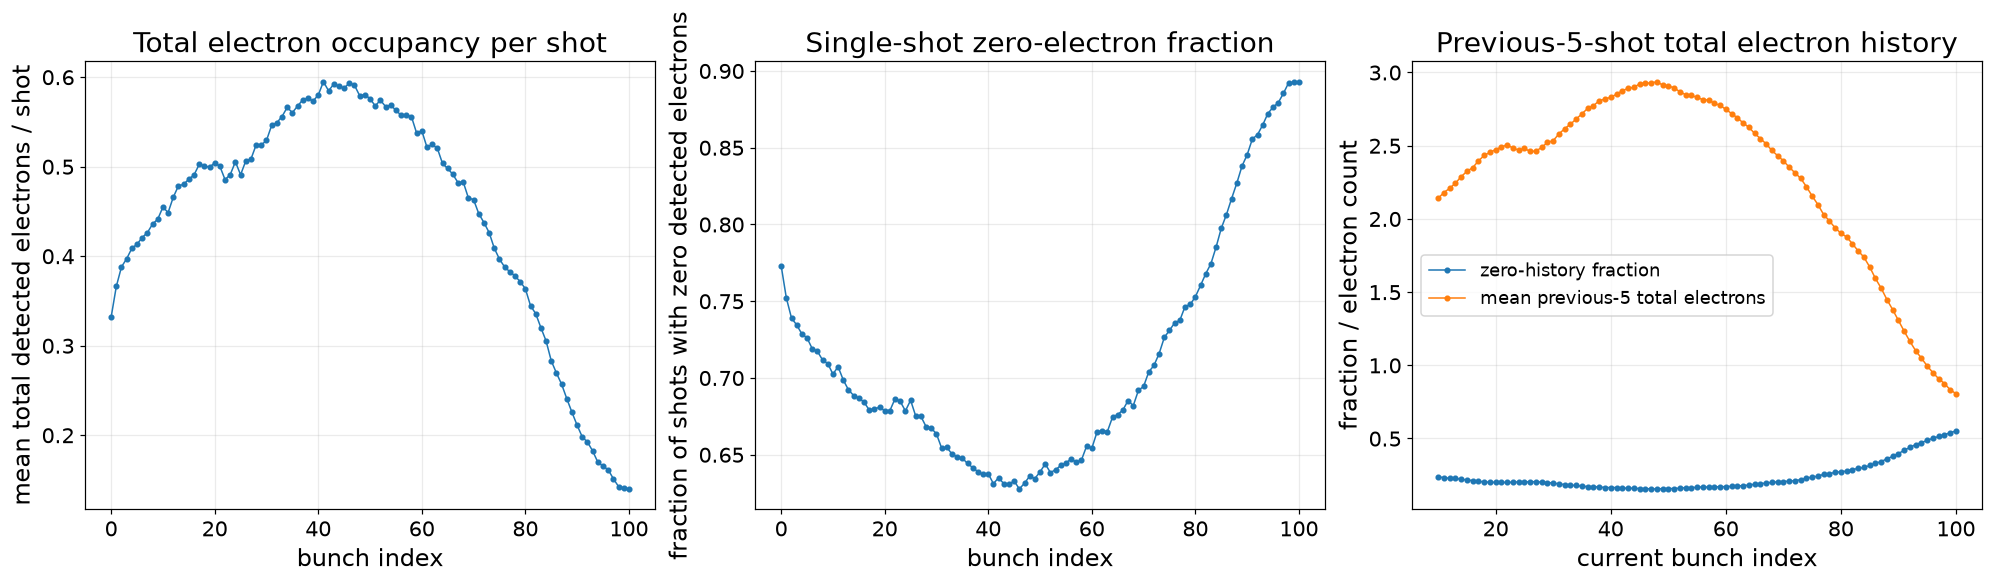

Mean total electrons / shot: 0.4444
Overall current-shot zero fraction: 71.0%
Mean previous-5 zero-history fraction: 24.0%
Previous-5 history percentiles: 25%=1.0, 50%=2.0, 75%=3.0, 90%=5.0, 99%=9.0
Maximum detected electrons in one shot: 50


In [ ]:
# --- Total-electron occupancy and previous-5-shot detector load ---

HISTORY_SHOTS = 5

# Total detected-electron history. Previous shots are included regardless of their GMD.
H_total = np.full_like(gmd,np.nan,dtype=float)
for b in range(HISTORY_SHOTS,n_bunch): H_total[:,b] = data["total_electrons"][:,b-HISTORY_SHOTS:b].sum(axis=1)

bunches_hist = np.arange(max(INDEP_BUNCH_START,HISTORY_SHOTS),n_bunch)
current_mean = np.mean(data["total_electrons"],axis=0)
current_zero = np.mean(data["total_electrons"] == 0,axis=0)
history_zero = np.array([np.mean(H_total[common[:,b],b] == 0) for b in bunches_hist])
history_mean = np.array([np.mean(H_total[common[:,b],b]) for b in bunches_hist])

fig,axes = plt.subplots(1,3,figsize=(18,5),constrained_layout=True)

axes[0].plot(np.arange(n_bunch),current_mean,"o-",ms=3,lw=1)
axes[0].set(xlabel="bunch index",ylabel="mean total detected electrons / shot",title="Total electron occupancy per shot")
axes[0].grid(alpha=0.25)

axes[1].plot(np.arange(n_bunch),current_zero,"o-",ms=3,lw=1)
axes[1].set(xlabel="bunch index",ylabel="fraction of shots with zero detected electrons",title="Single-shot zero-electron fraction")
axes[1].grid(alpha=0.25)

axes[2].plot(bunches_hist,history_zero,"o-",ms=3,lw=1,label="zero-history fraction")
axes[2].plot(bunches_hist,history_mean,"o-",ms=3,lw=1,label="mean previous-5 total electrons")
axes[2].set(xlabel="current bunch index",ylabel="fraction / electron count",title="Previous-5-shot total electron history")
axes[2].grid(alpha=0.25); axes[2].legend()

plt.show()

values = H_total[common & np.isfinite(H_total)]
print(f"Mean total electrons / shot: {np.mean(data['total_electrons']):.4f}")
print(f"Overall current-shot zero fraction: {np.mean(data['total_electrons'] == 0):.1%}")
print(f"Mean previous-5 zero-history fraction: {np.mean(history_zero):.1%}")
print(f"Previous-5 history percentiles: 25%={np.percentile(values,25):.1f}, 50%={np.percentile(values,50):.1f}, 75%={np.percentile(values,75):.1f}, 90%={np.percentile(values,90):.1f}, 99%={np.percentile(values,99):.1f}")
print(f"Maximum detected electrons in one shot: {np.nanmax(data['total_electrons']):.0f}")

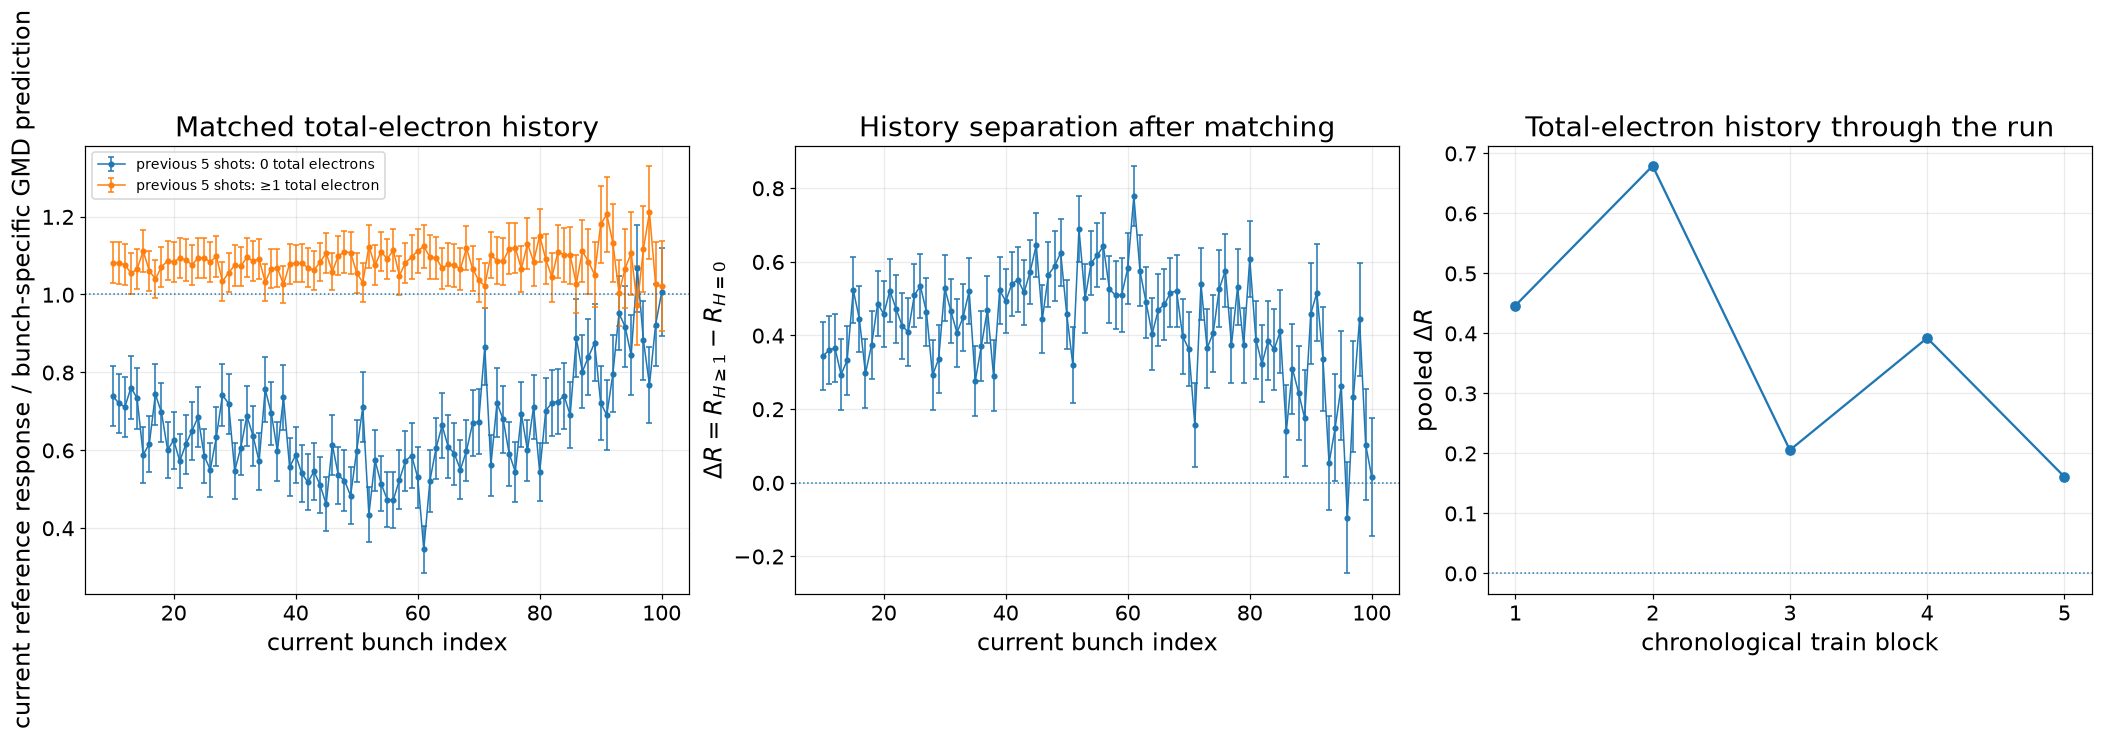

Overall matched H=0 response:  0.6549
Overall matched H>=1 response: 1.0822
Overall matched ΔR:            +0.4273 ± 0.0106
Effective matched shots per group: 660,519
Block ΔR: [0.4461 0.6788 0.2052 0.392  0.1607]


In [ ]:
# --- Matched total-electron history: H=0 vs H>=1 ---

N_TIME_BLOCKS = 5
MATCH_GMD_STEP = 1.0
MIN_PER_GROUP = 5

# Use actual train ordering for chronological blocks.
order = np.argsort(train_ids)
block_id = np.empty(gmd.shape[0],dtype=int)
for k,idx in enumerate(np.array_split(order,N_TIME_BLOCKS)): block_id[idx] = k

gmd_edges_match = np.arange(INDEP_GMD_RANGE[0],INDEP_GMD_RANGE[1]+MATCH_GMD_STEP,MATCH_GMD_STEP)

def matched_total_history_stats(blocks=None):
    if blocks is None: blocks = np.arange(N_TIME_BLOCKS)

    obs0 = np.zeros(n_bunch); pred0 = np.zeros(n_bunch); var0 = np.zeros(n_bunch)
    obs1 = np.zeros(n_bunch); pred1 = np.zeros(n_bunch); var1 = np.zeros(n_bunch)
    effective = np.zeros(n_bunch)

    for b in bunches_hist:
        base_valid = common[:,b] & np.isfinite(H_total[:,b]) & np.isfinite(local_pred_cv[:,b]) & (local_pred_cv[:,b] > 0)

        for block in blocks:
            for lo,hi in zip(gmd_edges_match[:-1],gmd_edges_match[1:]):
                use = base_valid & (block_id == block) & (gmd[:,b] >= lo) & (gmd[:,b] < hi)
                idx0 = np.flatnonzero(use & (H_total[:,b] == 0))
                idx1 = np.flatnonzero(use & (H_total[:,b] >= 1))
                m = min(idx0.size,idx1.size)
                if m < MIN_PER_GROUP: continue

                w0,w1 = m/idx0.size,m/idx1.size
                y0 = data["ref_counts"][idx0,b].astype(float)
                y1 = data["ref_counts"][idx1,b].astype(float)

                obs0[b] += w0*y0.sum(); pred0[b] += w0*local_pred_cv[idx0,b].sum(); var0[b] += w0**2*y0.sum()
                obs1[b] += w1*y1.sum(); pred1[b] += w1*local_pred_cv[idx1,b].sum(); var1[b] += w1**2*y1.sum()
                effective[b] += m

    R0 = np.divide(obs0,pred0,out=np.full(n_bunch,np.nan),where=pred0 > 0)
    R1 = np.divide(obs1,pred1,out=np.full(n_bunch,np.nan),where=pred1 > 0)
    E0 = np.divide(np.sqrt(var0),pred0,out=np.full(n_bunch,np.nan),where=pred0 > 0)
    E1 = np.divide(np.sqrt(var1),pred1,out=np.full(n_bunch,np.nan),where=pred1 > 0)

    pooled0 = obs0.sum()/pred0.sum()
    pooled1 = obs1.sum()/pred1.sum()
    pooled_e0 = np.sqrt(var0.sum())/pred0.sum()
    pooled_e1 = np.sqrt(var1.sum())/pred1.sum()

    return {"R0":R0,"R1":R1,"E0":E0,"E1":E1,"delta":R1-R0,"delta_err":np.sqrt(E0**2+E1**2),"effective":effective,
            "pooled0":pooled0,"pooled1":pooled1,"pooled_delta":pooled1-pooled0,"pooled_delta_err":np.sqrt(pooled_e0**2+pooled_e1**2)}

matched_total = matched_total_history_stats()

block_delta = []
for block in range(N_TIME_BLOCKS): block_delta.append(matched_total_history_stats([block])["pooled_delta"])

fig,axes = plt.subplots(1,3,figsize=(19,5),constrained_layout=True)

axes[0].errorbar(bunches_hist,matched_total["R0"][bunches_hist],yerr=matched_total["E0"][bunches_hist],fmt="o-",ms=3,lw=1,capsize=2,label="previous 5 shots: 0 total electrons")
axes[0].errorbar(bunches_hist,matched_total["R1"][bunches_hist],yerr=matched_total["E1"][bunches_hist],fmt="o-",ms=3,lw=1,capsize=2,label="previous 5 shots: ≥1 total electron")
axes[0].axhline(1,ls=":",lw=1)
axes[0].set(xlabel="current bunch index",ylabel="current reference response / bunch-specific GMD prediction",title="Matched total-electron history")
axes[0].grid(alpha=0.25); axes[0].legend(fontsize=9)

axes[1].errorbar(bunches_hist,matched_total["delta"][bunches_hist],yerr=matched_total["delta_err"][bunches_hist],fmt="o-",ms=3,lw=1,capsize=2)
axes[1].axhline(0,ls=":",lw=1)
axes[1].set(xlabel="current bunch index",ylabel=r"$\Delta R=R_{H\geq1}-R_{H=0}$",title="History separation after matching")
axes[1].grid(alpha=0.25)

axes[2].plot(np.arange(1,N_TIME_BLOCKS+1),block_delta,"o-")
axes[2].axhline(0,ls=":",lw=1)
axes[2].set_xticks(np.arange(1,N_TIME_BLOCKS+1))
axes[2].set(xlabel="chronological train block",ylabel=r"pooled $\Delta R$",title="Total-electron history through the run")
axes[2].grid(alpha=0.25)

plt.show()

print(f"Overall matched H=0 response:  {matched_total['pooled0']:.4f}")
print(f"Overall matched H>=1 response: {matched_total['pooled1']:.4f}")
print(f"Overall matched ΔR:            {matched_total['pooled_delta']:+.4f} ± {matched_total['pooled_delta_err']:.4f}")
print(f"Effective matched shots per group: {matched_total['effective'].sum():,.0f}")
print("Block ΔR:",np.round(block_delta,4))

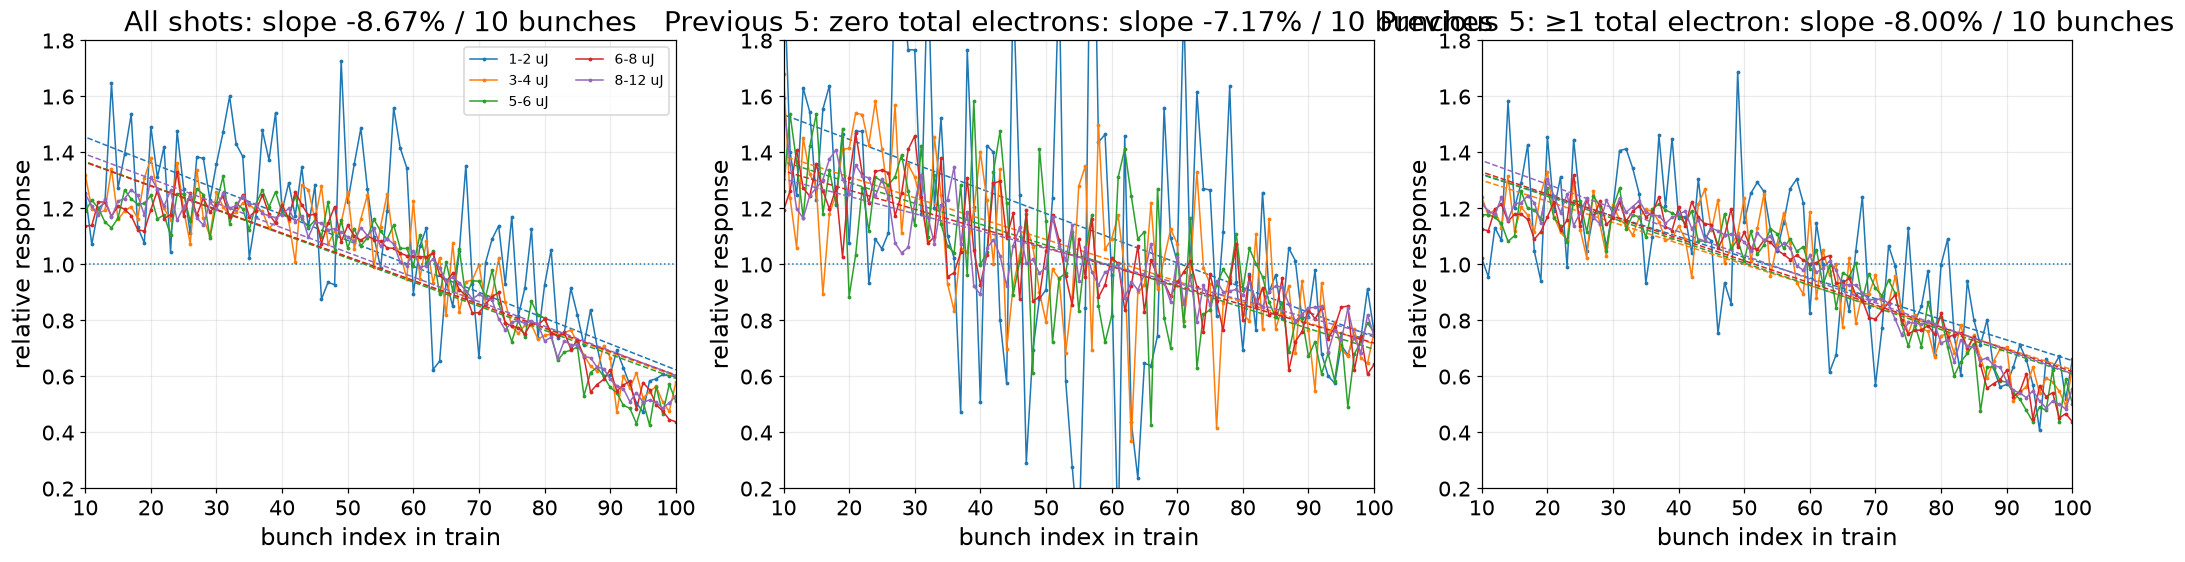

All shots:  flatness=0.24683, slope=-8.675% / 10 bunches
H=0:        flatness=0.26797, slope=-7.165% / 10 bunches
H>=1:       flatness=0.21927, slope=-8.005% / 10 bunches
Mean H=0 fraction over analysed bunches: 24.0%


In [ ]:
# --- Does the original bunch-position dependence survive with zero recent total-electron history? ---

mask_all = common & np.isfinite(H_total)
mask_H0 = mask_all & (H_total == 0)
mask_H1 = mask_all & (H_total >= 1)

def history_subset_metric(mask):
    obs = band_sums(data["target_counts"],gmd,mask)
    norm = band_sums(gmd,gmd,mask)
    shots = band_sums(np.ones_like(gmd),gmd,mask)
    return bunch_metrics(obs,norm,shots)

metric_all = history_subset_metric(mask_all)
metric_H0 = history_subset_metric(mask_H0)
metric_H1 = history_subset_metric(mask_H1)

fig,axes = plt.subplots(1,3,figsize=(19,5),constrained_layout=True)
for ax,name,m in zip(axes,["All shots","Previous 5: zero total electrons","Previous 5: ≥1 total electron"],[metric_all,metric_H0,metric_H1]):
    plot_bunch_response(m,f"{name}: slope {m['slope']:+.2f}% / 10 bunches",ax)
    ax.set_ylim(0.2,1.8)
axes[0].legend(ncol=2,fontsize=9)
plt.show()

print(f"All shots:  flatness={metric_all['flatness']:.5f}, slope={metric_all['slope']:+.3f}% / 10 bunches")
print(f"H=0:        flatness={metric_H0['flatness']:.5f}, slope={metric_H0['slope']:+.3f}% / 10 bunches")
print(f"H>=1:       flatness={metric_H1['flatness']:.5f}, slope={metric_H1['slope']:+.3f}% / 10 bunches")
print(f"Mean H=0 fraction over analysed bunches: {np.mean([np.mean(mask_H0[:,b][mask_all[:,b]]) if np.any(mask_all[:,b]) else np.nan for b in bunches_hist]):.1%}")

,all slope,zero-history slope,nonzero-history slope,zero-history fraction,zero-history shots
window,,,,,
1,-8.67495,-8.81035,-7.53704,0.70607,2008724
2,-8.67495,-8.86783,-7.60562,0.51413,1462654
3,-8.67495,-8.64627,-7.74019,0.38595,1097984
5,-8.67495,-7.16516,-8.00453,0.23872,679140
8,-8.67495,-2.26978,-8.33879,0.14371,408842
10,-8.67495,0.63808,-8.45253,0.11512,327517
15,-9.46515,12.19466,-9.40791,0.08590,230123
20,-10.35227,24.46771,-10.37190,0.07755,194922


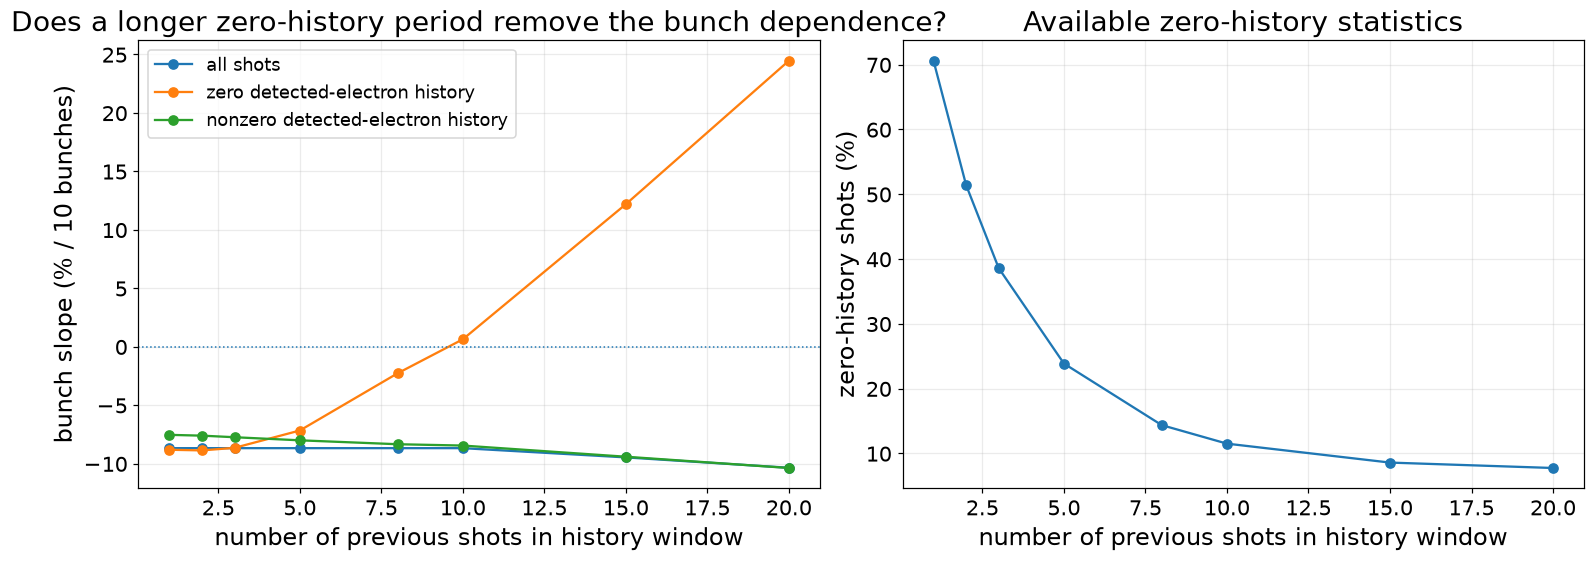

In [ ]:
# --- Does the bunch slope survive increasingly long zero-electron histories? ---

HISTORY_WINDOWS_TEST = [1,2,3,5,8,10,15,20]

def total_history(window):
    H = np.full_like(gmd,np.nan,dtype=float)
    for b in range(window,n_bunch): H[:,b] = data["total_electrons"][:,b-window:b].sum(axis=1)
    return H

def subset_bunch_metric(mask):
    obs = band_sums(data["target_counts"],gmd,mask)
    norm = band_sums(gmd,gmd,mask)
    shots = band_sums(np.ones_like(gmd),gmd,mask)
    return bunch_metrics(obs,norm,shots)

history_window_rows = []

for window in HISTORY_WINDOWS_TEST:
    H = total_history(window)
    start = max(INDEP_BUNCH_START,window)
    position_mask = np.broadcast_to(np.arange(n_bunch)[None,:] >= start,gmd.shape)
    base = common & position_mask & np.isfinite(H)
    zero = base & (H == 0)
    nonzero = base & (H >= 1)

    m_all = subset_bunch_metric(base)
    m_zero = subset_bunch_metric(zero)
    m_nonzero = subset_bunch_metric(nonzero)

    history_window_rows.append({"window":window,"all slope":m_all["slope"],"zero-history slope":m_zero["slope"],
                                "nonzero-history slope":m_nonzero["slope"],"zero-history fraction":np.count_nonzero(zero)/np.count_nonzero(base),
                                "zero-history shots":np.count_nonzero(zero)})

history_window_table = pd.DataFrame(history_window_rows).set_index("window")
display(history_window_table.round(5))

fig,axes = plt.subplots(1,2,figsize=(14,5),constrained_layout=True)

axes[0].plot(history_window_table.index,history_window_table["all slope"],"o-",label="all shots")
axes[0].plot(history_window_table.index,history_window_table["zero-history slope"],"o-",label="zero detected-electron history")
axes[0].plot(history_window_table.index,history_window_table["nonzero-history slope"],"o-",label="nonzero detected-electron history")
axes[0].axhline(0,ls=":",lw=1)
axes[0].set(xlabel="number of previous shots in history window",ylabel="bunch slope (% / 10 bunches)",title="Does a longer zero-history period remove the bunch dependence?")
axes[0].grid(alpha=0.25); axes[0].legend()

axes[1].plot(history_window_table.index,100*history_window_table["zero-history fraction"],"o-")
axes[1].set(xlabel="number of previous shots in history window",ylabel="zero-history shots (%)",title="Available zero-history statistics")
axes[1].grid(alpha=0.25)

plt.show()

In [ ]:
print("Shots at 50-hit limit:",np.count_nonzero(data["total_electrons"] >= 50))
print("Fraction at 50-hit limit:",np.mean(data["total_electrons"] >= 50))

Shots at 50-hit limit: 6
Fraction at 50-hit limit: 1.6762871580478965e-06


### Real bunch-position dependence that GMD alone does not explain

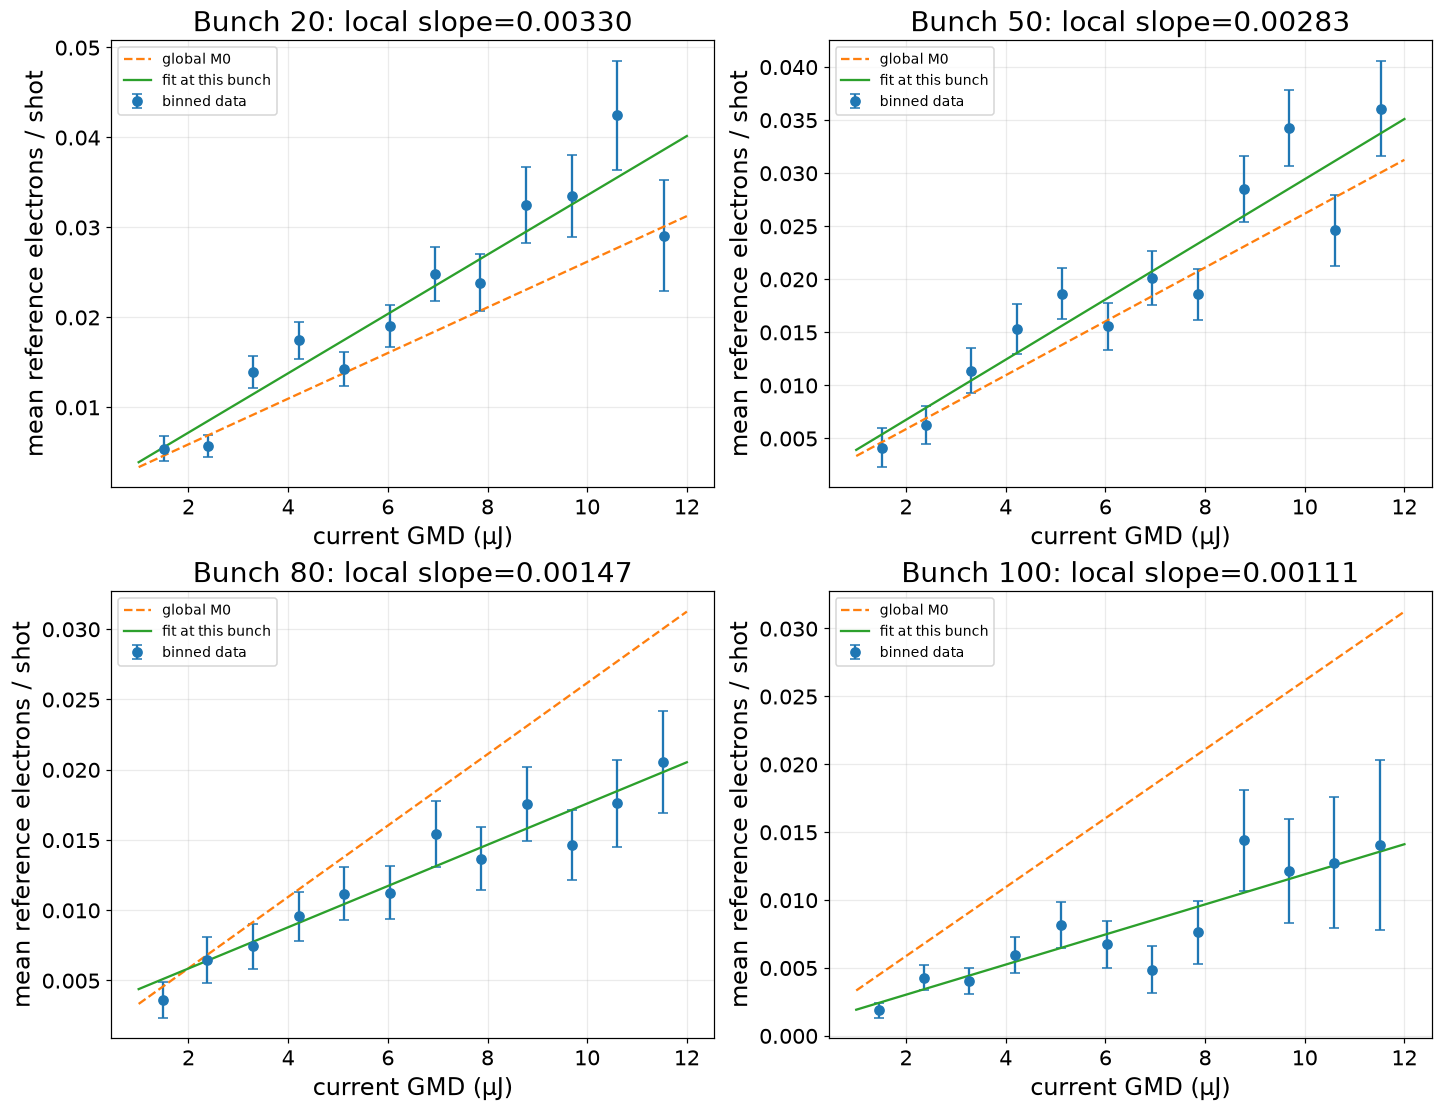

In [ ]:
# --- Diagnostic: current reference-electron yield vs current GMD at different bunch positions ---

BUNCH_CHECKS = [20,50,80,100]
N_GMD_BINS = 12
g_grid = np.linspace(INDEP_GMD_RANGE[0],INDEP_GMD_RANGE[1],200)
beta_mean = beta_cv["M0"].mean(axis=0)

fig,axes = plt.subplots(2,2,figsize=(13,10),constrained_layout=True)

for ax,bunch_pos in zip(axes.flat,BUNCH_CHECKS):
    valid = common[:,bunch_pos]
    g = gmd[valid,bunch_pos]
    y = data["ref_counts"][valid,bunch_pos].astype(float)

    edges = np.linspace(INDEP_GMD_RANGE[0],INDEP_GMD_RANGE[1],N_GMD_BINS+1)
    ibin = np.digitize(g,edges[1:-1])
    gx,ym,ye = [],[],[]
    for j in range(N_GMD_BINS):
        use = ibin == j
        if not np.any(use): continue
        gx.append(g[use].mean()); ym.append(y[use].mean()); ye.append(np.sqrt(y[use].sum())/use.sum())

    X = np.column_stack((np.ones_like(g),g))
    beta_local = np.linalg.lstsq(X,y,rcond=None)[0]

    ax.errorbar(gx,ym,yerr=ye,fmt="o",capsize=3,label="binned data")
    ax.plot(g_grid,beta_mean[0]+beta_mean[1]*g_grid,"--",lw=1.5,label="global M0")
    ax.plot(g_grid,beta_local[0]+beta_local[1]*g_grid,"-",lw=1.5,label="fit at this bunch")
    ax.set(xlabel="current GMD (µJ)",ylabel="mean reference electrons / shot",title=f"Bunch {bunch_pos}: local slope={beta_local[1]:.5f}")
    ax.grid(alpha=0.25); ax.legend(fontsize=9)

plt.show()

/tmp/ipykernel_539779/3267067083.py:24: RuntimeWarning: Mean of empty slice
  mean_local_slope = np.nanmean(local_beta_cv[:,:,1],axis=0)
/home/mmanresa/glycine26/.venv/lib64/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1997: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


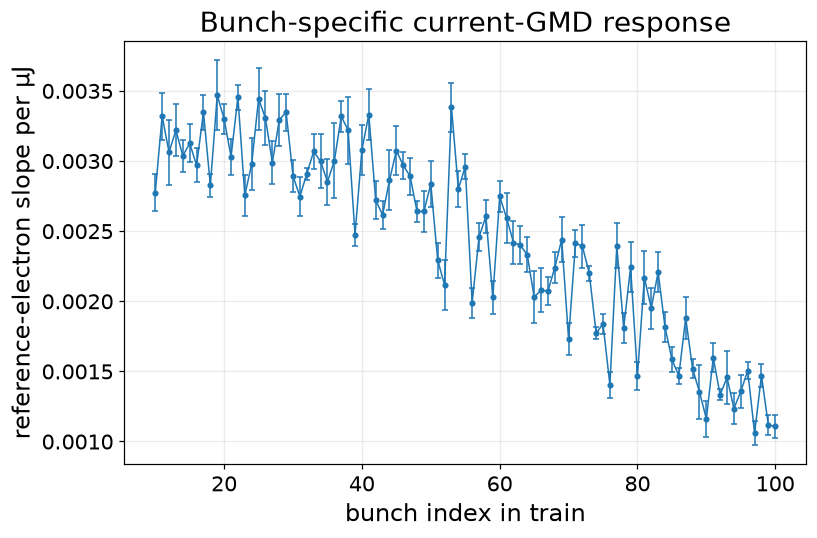

In [ ]:
# --- Bunch-specific current-GMD baseline, fitted only on training trains ---

local_pred_cv = np.full_like(gmd,np.nan,dtype=float)
local_beta_cv = np.full((INDEP_CV_MOD,n_bunch,2),np.nan)

for off in INDEP_CV_OFFSETS:
    train_rows = train_ids % INDEP_CV_MOD != off
    test_rows = train_ids % INDEP_CV_MOD == off

    for b in range(INDEP_BUNCH_START,n_bunch):
        use_train = train_rows & common[:,b]
        if np.count_nonzero(use_train) < 2: continue

        g_train = gmd[use_train,b]
        y_train = data["ref_counts"][use_train,b].astype(float)
        X = np.column_stack((np.ones_like(g_train),g_train))
        beta = np.linalg.lstsq(X,y_train,rcond=None)[0]
        local_beta_cv[off,b] = beta

        g_test = gmd[test_rows,b]
        local_pred_cv[test_rows,b] = beta[0]+beta[1]*g_test

# Diagnostic: mean fitted GMD slope at each bunch position.
mean_local_slope = np.nanmean(local_beta_cv[:,:,1],axis=0)
sd_local_slope = np.nanstd(local_beta_cv[:,:,1],axis=0,ddof=1)
bunches_local = np.arange(INDEP_BUNCH_START,n_bunch)

fig,ax = plt.subplots(figsize=(8,5))
ax.errorbar(bunches_local,mean_local_slope[bunches_local],yerr=sd_local_slope[bunches_local],fmt="o-",ms=3,lw=1,capsize=2)
ax.set(xlabel="bunch index in train",ylabel="reference-electron slope per µJ",title="Bunch-specific current-GMD response")
ax.grid(alpha=0.25)
plt.show()

### Correlation between neighbouring shots

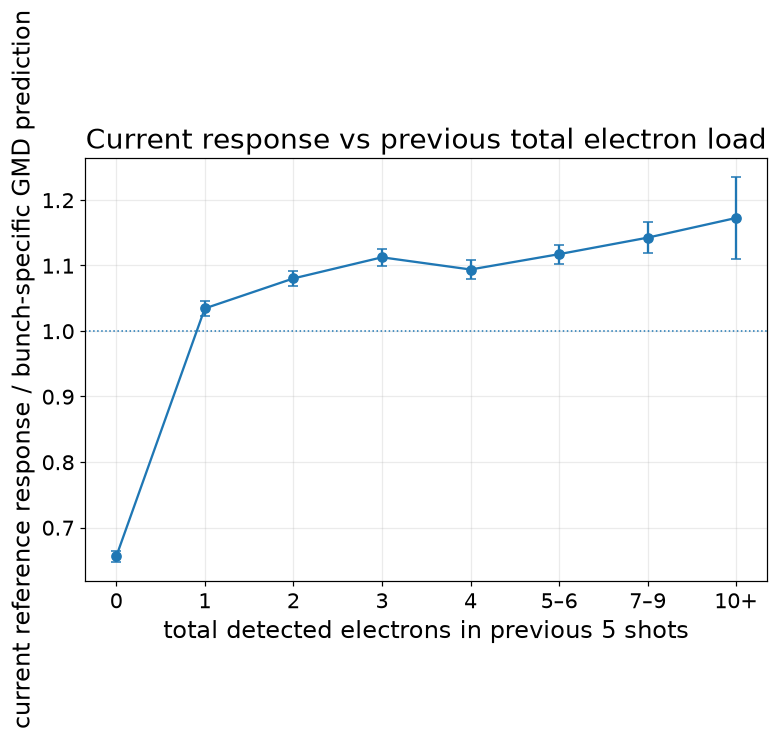

history   0: response=0.6558 ± 0.0085, shots=679,118
history   1: response=1.0345 ± 0.0113, shots=548,705
history   2: response=1.0802 ± 0.0115, shots=509,827
history   3: response=1.1125 ± 0.0128, shots=401,668
history   4: response=1.0939 ± 0.0148, shots=283,963
history 5–6: response=1.1173 ± 0.0145, shots=293,652
history 7–9: response=1.1425 ± 0.0232, shots=112,509
history 10+: response=1.1726 ± 0.0624, shots=15,395


In [ ]:
# --- Direct dose-response to total detected-electron history ---

HISTORY_SHOTS = 5
H_total = np.full_like(gmd,np.nan,dtype=float)
for b in range(HISTORY_SHOTS,n_bunch): H_total[:,b] = data["total_electrons"][:,b-HISTORY_SHOTS:b].sum(axis=1)

# Bins chosen from the observed total-history distribution.
HISTORY_BINS = [(0,0),(1,1),(2,2),(3,3),(4,4),(5,6),(7,9),(10,np.inf)]
labels = ["0","1","2","3","4","5–6","7–9","10+"]

response,response_err,n_shots = [],[],[]
valid_base = common & np.isfinite(H_total) & np.isfinite(local_pred_cv) & (local_pred_cv > 0)

for lo,hi in HISTORY_BINS:
    use = valid_base & (H_total >= lo) & (H_total <= hi)
    obs = data["ref_counts"][use].sum()
    pred = local_pred_cv[use].sum()
    response.append(obs/pred if pred > 0 else np.nan)
    response_err.append(np.sqrt(obs)/pred if obs > 0 and pred > 0 else np.nan)
    n_shots.append(np.count_nonzero(use))

fig,ax = plt.subplots(figsize=(8,5))
ax.errorbar(np.arange(len(labels)),response,yerr=response_err,fmt="o-",capsize=3)
ax.axhline(1,ls=":",lw=1)
ax.set_xticks(np.arange(len(labels)),labels)
ax.set(xlabel=f"total detected electrons in previous {HISTORY_SHOTS} shots",ylabel="current reference response / bunch-specific GMD prediction",title="Current response vs previous total electron load")
ax.grid(alpha=0.25)
plt.show()

for label,r,e,n in zip(labels,response,response_err,n_shots): print(f"history {label:>3s}: response={r:.4f} ± {e:.4f}, shots={n:,}")

### Cumulative history for similar shots

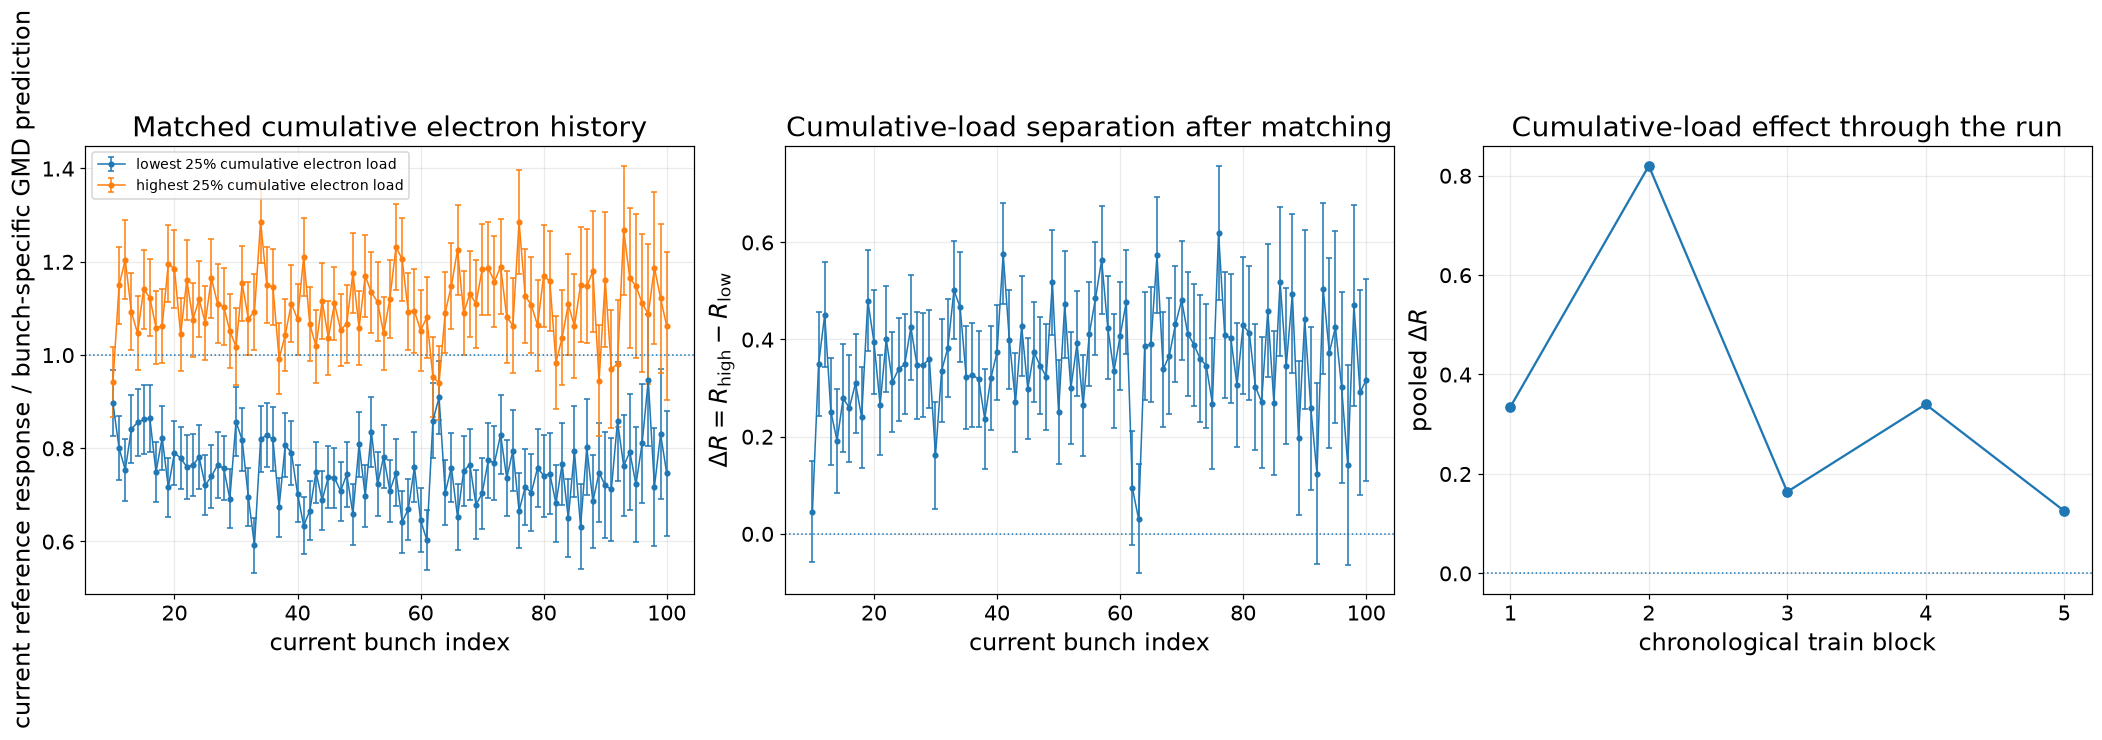

Matched low cumulative-load response:  0.7511
Matched high cumulative-load response: 1.1066
Overall cumulative-load ΔR:            +0.3555 ± 0.0123
Effective matched shots per group:     747,635
Block ΔR: [0.3344 0.8195 0.1638 0.3397 0.1254]


In [ ]:
# --- Matched cumulative total-electron history ---
# At fixed current bunch, current GMD and time block, compare low vs high
# total detected-electron load accumulated since the start of the train.

# compared shots at:
# - the same current bunch position;
# - similar current GMD;
# - the same broad time period in the run;
# but with low versus high total accumulated electron counts earlier in that train.

CUM_QUANTILE = 0.25
N_TIME_BLOCKS = 5
MATCH_GMD_STEP = 0.5
MIN_PER_GROUP = 20

# C_total[:, b] = all detected electrons in shots 0 ... b-1 of the same train.
C_total = np.zeros_like(gmd,dtype=float)
C_total[:,1:] = np.cumsum(data["total_electrons"][:,:-1],axis=1)

# Chronological train blocks.
order = np.argsort(train_ids)
block_id = np.empty(gmd.shape[0],dtype=int)
for k,idx in enumerate(np.array_split(order,N_TIME_BLOCKS)): block_id[idx] = k

gmd_edges_match = np.arange(INDEP_GMD_RANGE[0],INDEP_GMD_RANGE[1]+MATCH_GMD_STEP,MATCH_GMD_STEP)
bunches_cum = np.arange(INDEP_BUNCH_START,n_bunch)

def matched_cumulative_stats(blocks=None):
    if blocks is None: blocks = np.arange(N_TIME_BLOCKS)

    obs_lo = np.zeros(n_bunch); pred_lo = np.zeros(n_bunch); var_lo = np.zeros(n_bunch)
    obs_hi = np.zeros(n_bunch); pred_hi = np.zeros(n_bunch); var_hi = np.zeros(n_bunch)
    effective = np.zeros(n_bunch)

    for b in bunches_cum:
        base_valid = common[:,b] & np.isfinite(C_total[:,b]) & np.isfinite(local_pred_cv[:,b]) & (local_pred_cv[:,b] > 0)

        for block in blocks:
            for g_lo,g_hi in zip(gmd_edges_match[:-1],gmd_edges_match[1:]):
                idx = np.flatnonzero(base_valid & (block_id == block) & (gmd[:,b] >= g_lo) & (gmd[:,b] < g_hi))
                if idx.size < 2*MIN_PER_GROUP: continue

                C = C_total[idx,b]
                q_lo,q_hi = np.quantile(C,[CUM_QUANTILE,1-CUM_QUANTILE])
                if q_lo >= q_hi: continue

                idx_lo = idx[C <= q_lo]
                idx_hi = idx[C >= q_hi]
                m = min(idx_lo.size,idx_hi.size)
                if m < MIN_PER_GROUP: continue

                # Equal effective weight for low/high history inside each matched stratum.
                w_lo,w_hi = m/idx_lo.size,m/idx_hi.size
                y_lo = data["ref_counts"][idx_lo,b].astype(float)
                y_hi = data["ref_counts"][idx_hi,b].astype(float)

                obs_lo[b] += w_lo*y_lo.sum(); pred_lo[b] += w_lo*local_pred_cv[idx_lo,b].sum(); var_lo[b] += w_lo**2*y_lo.sum()
                obs_hi[b] += w_hi*y_hi.sum(); pred_hi[b] += w_hi*local_pred_cv[idx_hi,b].sum(); var_hi[b] += w_hi**2*y_hi.sum()
                effective[b] += m

    R_lo = np.divide(obs_lo,pred_lo,out=np.full(n_bunch,np.nan),where=pred_lo > 0)
    R_hi = np.divide(obs_hi,pred_hi,out=np.full(n_bunch,np.nan),where=pred_hi > 0)
    E_lo = np.divide(np.sqrt(var_lo),pred_lo,out=np.full(n_bunch,np.nan),where=pred_lo > 0)
    E_hi = np.divide(np.sqrt(var_hi),pred_hi,out=np.full(n_bunch,np.nan),where=pred_hi > 0)

    pooled_lo = obs_lo.sum()/pred_lo.sum()
    pooled_hi = obs_hi.sum()/pred_hi.sum()
    pooled_e_lo = np.sqrt(var_lo.sum())/pred_lo.sum()
    pooled_e_hi = np.sqrt(var_hi.sum())/pred_hi.sum()

    return {"R_lo":R_lo,"R_hi":R_hi,"E_lo":E_lo,"E_hi":E_hi,"delta":R_hi-R_lo,"delta_err":np.sqrt(E_lo**2+E_hi**2),
            "effective":effective,"pooled_lo":pooled_lo,"pooled_hi":pooled_hi,"pooled_delta":pooled_hi-pooled_lo,
            "pooled_delta_err":np.sqrt(pooled_e_lo**2+pooled_e_hi**2)}

cum_match = matched_cumulative_stats()

block_delta = []
for block in range(N_TIME_BLOCKS): block_delta.append(matched_cumulative_stats([block])["pooled_delta"])

fig,axes = plt.subplots(1,3,figsize=(19,5),constrained_layout=True)

axes[0].errorbar(bunches_cum,cum_match["R_lo"][bunches_cum],yerr=cum_match["E_lo"][bunches_cum],fmt="o-",ms=3,lw=1,capsize=2,label="lowest 25% cumulative electron load")
axes[0].errorbar(bunches_cum,cum_match["R_hi"][bunches_cum],yerr=cum_match["E_hi"][bunches_cum],fmt="o-",ms=3,lw=1,capsize=2,label="highest 25% cumulative electron load")
axes[0].axhline(1,ls=":",lw=1)
axes[0].set(xlabel="current bunch index",ylabel="current reference response / bunch-specific GMD prediction",title="Matched cumulative electron history")
axes[0].grid(alpha=0.25); axes[0].legend(fontsize=9)

axes[1].errorbar(bunches_cum,cum_match["delta"][bunches_cum],yerr=cum_match["delta_err"][bunches_cum],fmt="o-",ms=3,lw=1,capsize=2)
axes[1].axhline(0,ls=":",lw=1)
axes[1].set(xlabel="current bunch index",ylabel=r"$\Delta R=R_{\rm high}-R_{\rm low}$",title="Cumulative-load separation after matching")
axes[1].grid(alpha=0.25)

axes[2].plot(np.arange(1,N_TIME_BLOCKS+1),block_delta,"o-")
axes[2].axhline(0,ls=":",lw=1)
axes[2].set_xticks(np.arange(1,N_TIME_BLOCKS+1))
axes[2].set(xlabel="chronological train block",ylabel=r"pooled $\Delta R$",title="Cumulative-load effect through the run")
axes[2].grid(alpha=0.25)

plt.show()

print(f"Matched low cumulative-load response:  {cum_match['pooled_lo']:.4f}")
print(f"Matched high cumulative-load response: {cum_match['pooled_hi']:.4f}")
print(f"Overall cumulative-load ΔR:            {cum_match['pooled_delta']:+.4f} ± {cum_match['pooled_delta_err']:.4f}")
print(f"Effective matched shots per group:     {cum_match['effective'].sum():,.0f}")
print("Block ΔR:",np.round(block_delta,4))

### Correlation linearity vs bunch position

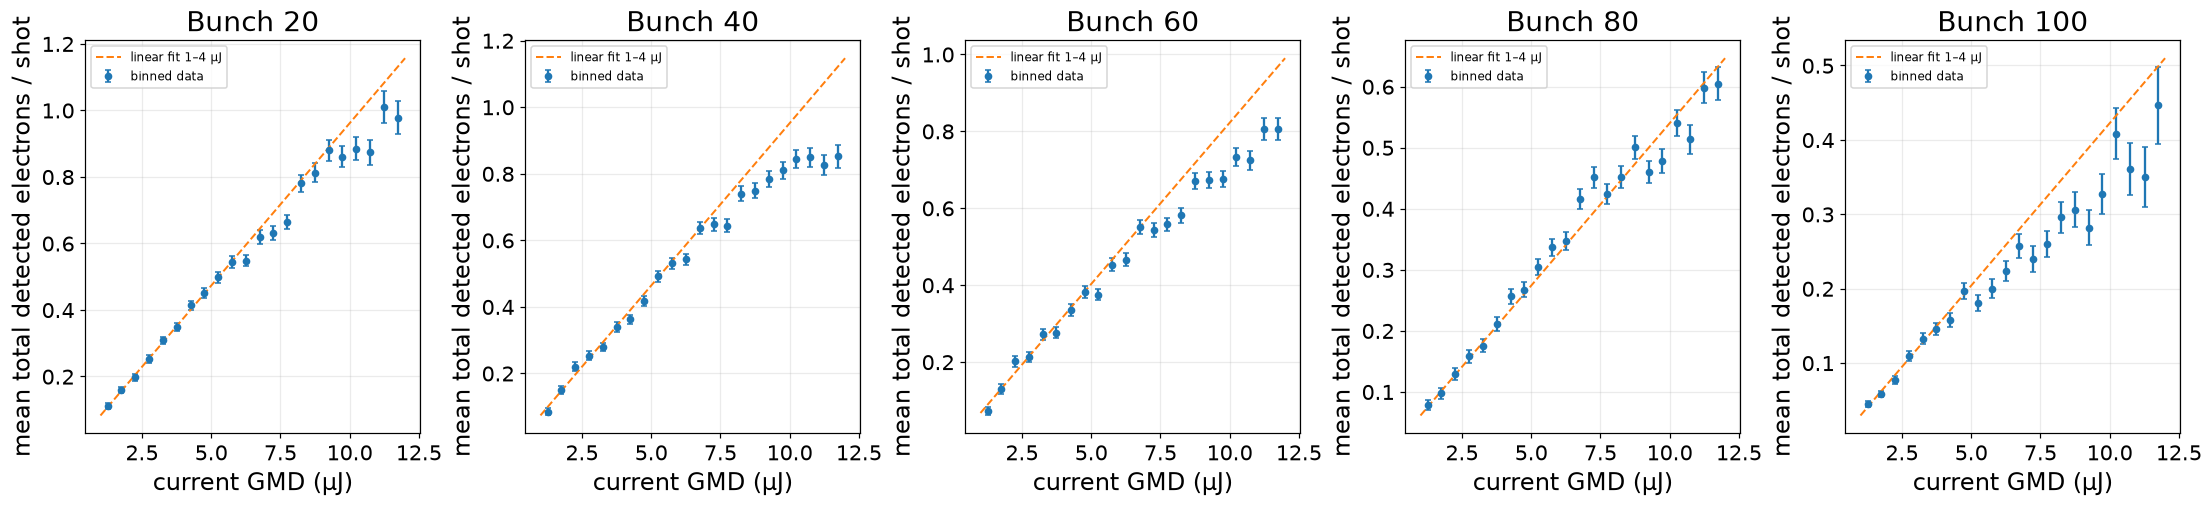

In [ ]:
# --- Total detected-electron yield vs GMD at selected bunch positions ---
# Tests whether the GMD-response nonlinearity changes through the pulse train.

BUNCH_POSITIONS = [20,40,60,80,100]
# BUNCH_POSITIONS = [10,30,50,70,90]
GMD_BIN_WIDTH = 0.5
LOW_GMD_FIT_RANGE = (1.0,4.0)

gmd_edges_diag = np.arange(INDEP_GMD_RANGE[0],INDEP_GMD_RANGE[1]+GMD_BIN_WIDTH,GMD_BIN_WIDTH)
gmd_centres_diag = 0.5*(gmd_edges_diag[:-1]+gmd_edges_diag[1:])

fig,axes = plt.subplots(1,len(BUNCH_POSITIONS),figsize=(20,4.5),constrained_layout=True)

for ax,b in zip(axes,BUNCH_POSITIONS):
    g = gmd[:,b]
    y = data["total_electrons"][:,b].astype(float)
    valid = np.isfinite(g) & np.isfinite(y) & (g >= INDEP_GMD_RANGE[0]) & (g < INDEP_GMD_RANGE[1])

    x_bin,y_bin,y_err,n_bin = [],[],[],[]
    for lo,hi,xc in zip(gmd_edges_diag[:-1],gmd_edges_diag[1:],gmd_centres_diag):
        use = valid & (g >= lo) & (g < hi)
        if not np.any(use): continue
        x_bin.append(g[use].mean())
        y_bin.append(y[use].mean())
        y_err.append(np.sqrt(y[use].sum())/np.count_nonzero(use))
        n_bin.append(np.count_nonzero(use))

    x_bin,y_bin,y_err = map(np.asarray,(x_bin,y_bin,y_err))

    low = (x_bin >= LOW_GMD_FIT_RANGE[0]) & (x_bin <= LOW_GMD_FIT_RANGE[1])
    beta_low = np.linalg.lstsq(np.column_stack((np.ones(np.count_nonzero(low)),x_bin[low])),y_bin[low],rcond=None)[0]
    x_fit = np.linspace(INDEP_GMD_RANGE[0],INDEP_GMD_RANGE[1],200)
    y_fit = beta_low[0]+beta_low[1]*x_fit

    ax.errorbar(x_bin,y_bin,yerr=y_err,fmt="o",ms=4,capsize=2,label="binned data")
    ax.plot(x_fit,y_fit,"--",lw=1.3,label=f"linear fit {LOW_GMD_FIT_RANGE[0]:.0f}–{LOW_GMD_FIT_RANGE[1]:.0f} µJ")
    ax.set(xlabel="current GMD (µJ)",ylabel="mean total detected electrons / shot",title=f"Bunch {b}")
    ax.grid(alpha=0.25); ax.legend(fontsize=8)

plt.show()

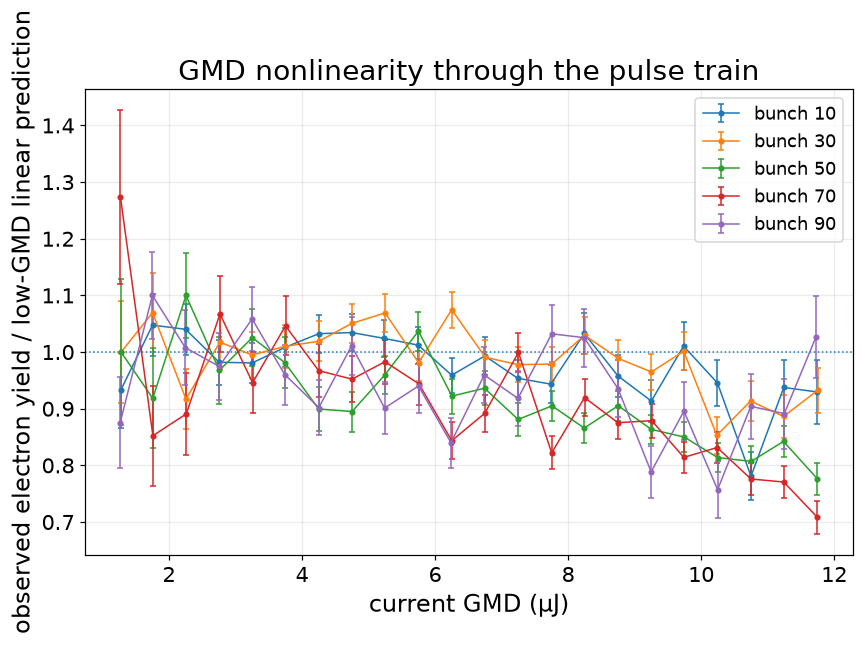

In [ ]:
# --- Ratio to low-GMD linear prediction at each bunch position ---

fig,ax = plt.subplots(figsize=(9,5.5))

for b in BUNCH_POSITIONS:
    g = gmd[:,b]
    y = data["total_electrons"][:,b].astype(float)
    valid = np.isfinite(g) & np.isfinite(y) & (g >= INDEP_GMD_RANGE[0]) & (g < INDEP_GMD_RANGE[1])

    x_bin,y_bin,y_err = [],[],[]
    for lo,hi in zip(gmd_edges_diag[:-1],gmd_edges_diag[1:]):
        use = valid & (g >= lo) & (g < hi)
        if not np.any(use): continue
        x_bin.append(g[use].mean())
        y_bin.append(y[use].mean())
        y_err.append(np.sqrt(y[use].sum())/np.count_nonzero(use))

    x_bin,y_bin,y_err = map(np.asarray,(x_bin,y_bin,y_err))
    low = (x_bin >= LOW_GMD_FIT_RANGE[0]) & (x_bin <= LOW_GMD_FIT_RANGE[1])
    beta_low = np.linalg.lstsq(np.column_stack((np.ones(np.count_nonzero(low)),x_bin[low])),y_bin[low],rcond=None)[0]
    pred = beta_low[0]+beta_low[1]*x_bin

    ax.errorbar(x_bin,y_bin/pred,yerr=y_err/pred,fmt="o-",ms=3,lw=1,capsize=2,label=f"bunch {b}")

ax.axhline(1,ls=":",lw=1)
ax.set(xlabel="current GMD (µJ)",ylabel="observed electron yield / low-GMD linear prediction",title="GMD nonlinearity through the pulse train")
ax.grid(alpha=0.25); ax.legend()
plt.show()

In [ ]:
# --- Inventory all datasets available in the source H5 ---

with h5py.File(source_h5,"r") as handle:
    def show_dataset(name,obj):
        if isinstance(obj,h5py.Dataset): print(f"{name:45s} shape={str(obj.shape):20s} dtype={obj.dtype}")
    handle.visititems(show_dataset)

between_tdc_files                             shape=(35439,)             dtype=bool
gmd                                           shape=(35439, 101)         dtype=float32
hor_pos                                       shape=(35439,)             dtype=float32
local_DAQ_running                             shape=(35439,)             dtype=bool
mpe                                           shape=(35439,)             dtype=float32
tID                                           shape=(35439,)             dtype=float64
tofs_e                                        shape=(35439, 101, 50)     dtype=uint32
tofs_i                                        shape=(35439, 101, 120)    dtype=uint32
ver_pos                                       shape=(35439,)             dtype=float32
z                                             shape=(35439, 101)         dtype=float32
z_std                                         shape=(35439, 101)         dtype=float32


## Cumulative load model

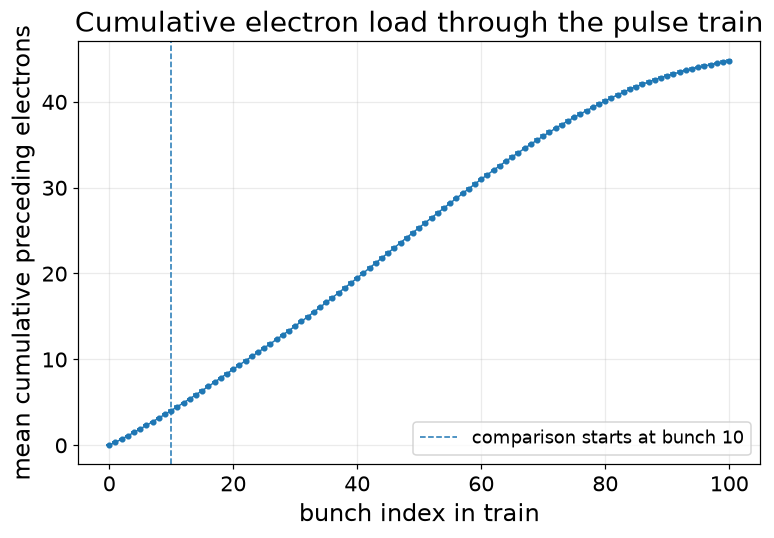

In [ ]:
# --- Cumulative detected-electron load: all earlier shots in the same train ---

def cumulative_electron_history(total_electrons):
    C = np.zeros(total_electrons.shape,dtype=float)
    C[:,1:] = np.cumsum(total_electrons[:,:-1],axis=1)
    return C

C_e = cumulative_electron_history(data["total_electrons"])
bunch = np.arange(n_bunch)

mean_C = C_e.mean(axis=0)
sem_C = C_e.std(axis=0,ddof=1)/np.sqrt(C_e.shape[0])

fig,ax = plt.subplots(figsize=(8,5))
ax.errorbar(bunch,mean_C,yerr=sem_C,fmt="o-",ms=3,lw=1,capsize=2)
ax.axvline(INDEP_BUNCH_START,ls="--",lw=1,label=f"comparison starts at bunch {INDEP_BUNCH_START}")
ax.set(xlabel="bunch index in train",ylabel="mean cumulative preceding electrons",title="Cumulative electron load through the pulse train")
ax.grid(alpha=0.25); ax.legend(); plt.show()

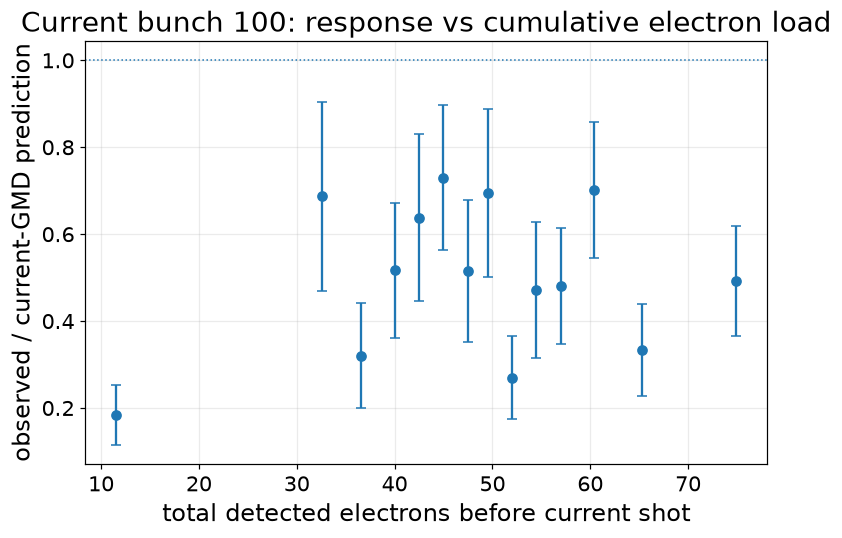

Shots used: 29,332
Cumulative-load range: 0 to 135 electrons


In [ ]:
# --- Fixed-bunch diagnostic: does cumulative history predict shot-to-shot response? ---

CUM_DIAG_BUNCH = 100
N_CUM_BINS = 15

pred_ref_cv = np.full_like(gmd,np.nan,dtype=float)
for off in INDEP_CV_OFFSETS:
    rows = train_ids % INDEP_CV_MOD == off
    pred_ref_cv[rows] = designs["M0"][rows] @ beta_cv["M0"][off]

C = C_e[:,CUM_DIAG_BUNCH]
obs = data["ref_counts"][:,CUM_DIAG_BUNCH].astype(float)
pred = pred_ref_cv[:,CUM_DIAG_BUNCH]
valid = common[:,CUM_DIAG_BUNCH] & np.isfinite(C) & np.isfinite(pred) & (pred > 0)

edges = np.unique(np.quantile(C[valid],np.linspace(0,1,N_CUM_BINS+1)))
bin_idx = np.digitize(C[valid],edges[1:-1])

c_bin,response_bin,response_err,n_bin = [],[],[],[]
for i in range(len(edges)-1):
    use = bin_idx == i
    if not np.any(use): continue
    obs_sum,pred_sum = obs[valid][use].sum(),pred[valid][use].sum()
    c_bin.append(C[valid][use].mean())
    response_bin.append(obs_sum/pred_sum)
    response_err.append(np.sqrt(obs_sum)/pred_sum if obs_sum > 0 else np.nan)
    n_bin.append(use.sum())

c_bin,response_bin,response_err,n_bin = map(np.asarray,(c_bin,response_bin,response_err,n_bin))

fig,ax = plt.subplots(figsize=(8,5))
ax.errorbar(c_bin,response_bin,yerr=response_err,fmt="o",capsize=3)
ax.axhline(1,ls=":",lw=1)
ax.set(xlabel="total detected electrons before current shot",ylabel="observed / current-GMD prediction",title=f"Current bunch {CUM_DIAG_BUNCH}: response vs cumulative electron load")
ax.grid(alpha=0.25); plt.show()

print(f"Shots used: {valid.sum():,}")
print(f"Cumulative-load range: {C[valid].min():.0f} to {C[valid].max():.0f} electrons")

,alpha_per_10e,baseline_mse,ref_mse,ref_mse_improvement_%
fold,,,,
0,0.000031,0.015727,0.015727,0.000008
1,0.000032,0.015787,0.015787,0.000008
2,0.000035,0.015663,0.015663,0.000005
3,0.000034,0.015656,0.015656,0.000008
4,0.000032,0.015618,0.015618,0.000006


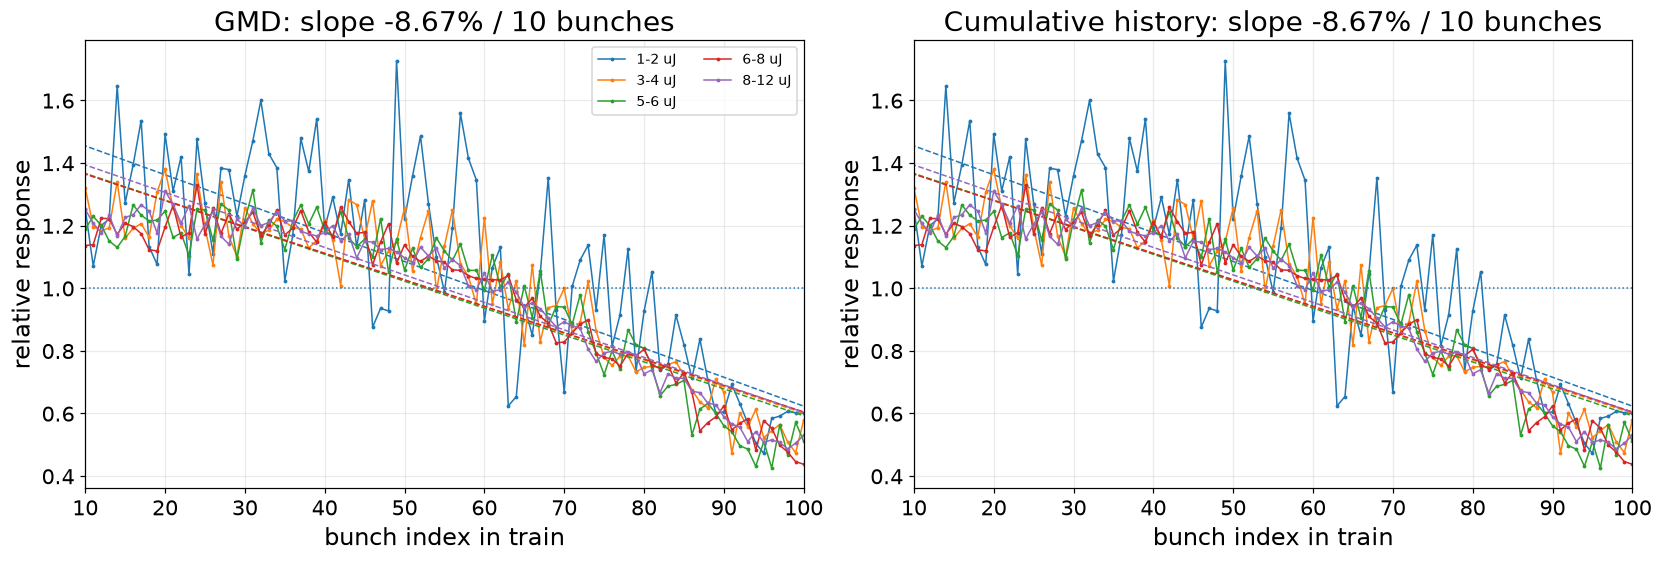

GMD:                flatness=0.24683, slope=-8.675% / 10 bunches
Cumulative history: flatness=0.24680, slope=-8.673% / 10 bunches
|slope| reduction: 0.02%
Fold slope SD: 0.182% / 10 bunches


In [ ]:
# --- Shot-resolved cumulative-history correction with fixed current-GMD baseline ---

CUM_SCALE = 10.0
CUM_ALPHA_BOUNDS = (-1.0,1.0)

shape = (INDEP_CV_MOD,len(INDEP_GMD_BANDS),n_bunch)
hold_target_cum = np.zeros(shape)
hold_shots_cum = np.zeros(shape)
hold_gmd_cum = np.zeros(shape)
hold_norm_cum = np.zeros(shape)
cum_fits = []

for off in INDEP_CV_OFFSETS:
    train_rows = train_ids % INDEP_CV_MOD != off
    test_rows = train_ids % INDEP_CV_MOD == off

    g_train,g_test = gmd[train_rows],gmd[test_rows]
    sel_train,sel_test = common[train_rows],common[test_rows]
    y_train = data["ref_counts"][train_rows].astype(float)
    y_test = data["ref_counts"][test_rows].astype(float)

    a,b = beta_cv["M0"][off]
    base_train = a+b*g_train
    base_test = a+b*g_test
    C_train = C_e[train_rows]/CUM_SCALE
    C_test = C_e[test_rows]/CUM_SCALE

    use_train = sel_train & np.isfinite(base_train) & (base_train > 0)
    use_test = sel_test & np.isfinite(base_test) & (base_test > 0)

    baseline_mse = np.mean((y_test[use_test]-base_test[use_test])**2)

    def loss(x):
        pred = base_train[use_train]*np.exp(-x[0]*C_train[use_train])
        return np.mean((y_train[use_train]-pred)**2)

    result = minimize(loss,[0.0],method="L-BFGS-B",bounds=[CUM_ALPHA_BOUNDS])
    if not result.success: raise RuntimeError(result.message)

    alpha = float(result.x[0])
    pred_test = base_test[use_test]*np.exp(-alpha*C_test[use_test])
    ref_mse = np.mean((y_test[use_test]-pred_test)**2)
    R_test = np.exp(-alpha*C_test)

    cum_fits.append({"fold":off,"alpha_per_10e":alpha,"baseline_mse":baseline_mse,"ref_mse":ref_mse,"ref_mse_improvement_%":100*(1-ref_mse/baseline_mse)})

    hold_target_cum[off] = band_sums(data["target_counts"][test_rows],g_test,sel_test)
    hold_shots_cum[off] = band_sums(np.ones_like(g_test),g_test,sel_test)
    hold_gmd_cum[off] = band_sums(g_test,g_test,sel_test)
    hold_norm_cum[off] = band_sums(g_test*R_test,g_test,sel_test)

cum_table = pd.DataFrame(cum_fits).set_index("fold")
display(cum_table.round(6))

obs_cum = hold_target_cum.sum(axis=0)
shots_cum = hold_shots_cum.sum(axis=0)
gmd_cum = bunch_metrics(obs_cum,hold_gmd_cum.sum(axis=0),shots_cum)
cum_metric = bunch_metrics(obs_cum,hold_norm_cum.sum(axis=0),shots_cum)

cum_fold_metrics = [bunch_metrics(hold_target_cum[off],hold_norm_cum[off],hold_shots_cum[off]) for off in INDEP_CV_OFFSETS]

fig,axes = plt.subplots(1,2,figsize=(15,5),constrained_layout=True)
plot_bunch_response(gmd_cum,f"GMD: slope {gmd_cum['slope']:+.2f}% / 10 bunches",axes[0])
plot_bunch_response(cum_metric,f"Cumulative history: slope {cum_metric['slope']:+.2f}% / 10 bunches",axes[1])
axes[0].legend(ncol=2,fontsize=9)
plt.show()

print(f"GMD:                flatness={gmd_cum['flatness']:.5f}, slope={gmd_cum['slope']:+.3f}% / 10 bunches")
print(f"Cumulative history: flatness={cum_metric['flatness']:.5f}, slope={cum_metric['slope']:+.3f}% / 10 bunches")
print(f"|slope| reduction: {100*(1-abs(cum_metric['slope'])/abs(gmd_cum['slope'])):.2f}%")
print(f"Fold slope SD: {np.std([m['slope'] for m in cum_fold_metrics],ddof=1):.3f}% / 10 bunches")

## 6. Final apples-to-apples comparison
Every method uses the **same held-out trains, shots and 220–260 eV counts**. The table reports combined flatness and weighted bunch slope, absolute-slope reduction relative to GMD, and fold mean/SD. Fold variation is descriptive, not an independent confidence interval.

Inspect band-resolved electron-history residuals: a small average slope can hide opposite trends in different bands. Additional improvement from **electron history + residual Cb** means this electron-history model leaves bunch-position structure. Little further improvement is consistent with an electron-load explanation, but does not establish causality.

,held-out flatness,slope (% / 10 bunches),|slope| reduction (%),fold flatness mean,fold flatness SD,fold slope mean,fold slope SD
method,,,,,,,
GMD,0.24683,-8.67495,0.00000,0.27576,0.00515,-8.67697,0.18211
M0,0.24714,-8.67939,-0.05123,0.27607,0.00517,-8.68116,0.18231
M5,0.24682,-8.79189,-1.34807,0.27532,0.00540,-8.79396,0.17962
M10,0.24631,-8.56193,1.30278,0.27566,0.00506,-8.56401,0.18058
E2,0.24639,-8.77983,-1.20899,0.27489,0.00545,-8.78185,0.17749
E3,0.24715,-8.76875,-1.08132,0.27574,0.00536,-8.77079,0.17724
Cb,0.09468,0.53651,93.81537,0.16329,0.00516,0.56081,0.19306
Electron history,0.22981,-8.17863,5.72127,0.26009,0.00593,-8.18143,0.20732
Free lag history,0.20687,-7.17455,17.29578,0.23976,0.00553,-7.17633,0.19461


,alpha,tau,a,b,training_mse
training fold,,,,,
0,-0.095881,3.297362,0.001037,0.002167,0.015674
1,-0.088929,3.135596,0.000925,0.002229,0.015659
2,-0.094850,3.291247,0.001065,0.002168,0.015690
3,-0.089616,3.143741,0.000995,0.002216,0.015692
4,-0.090281,3.276722,0.001178,0.002167,0.015702


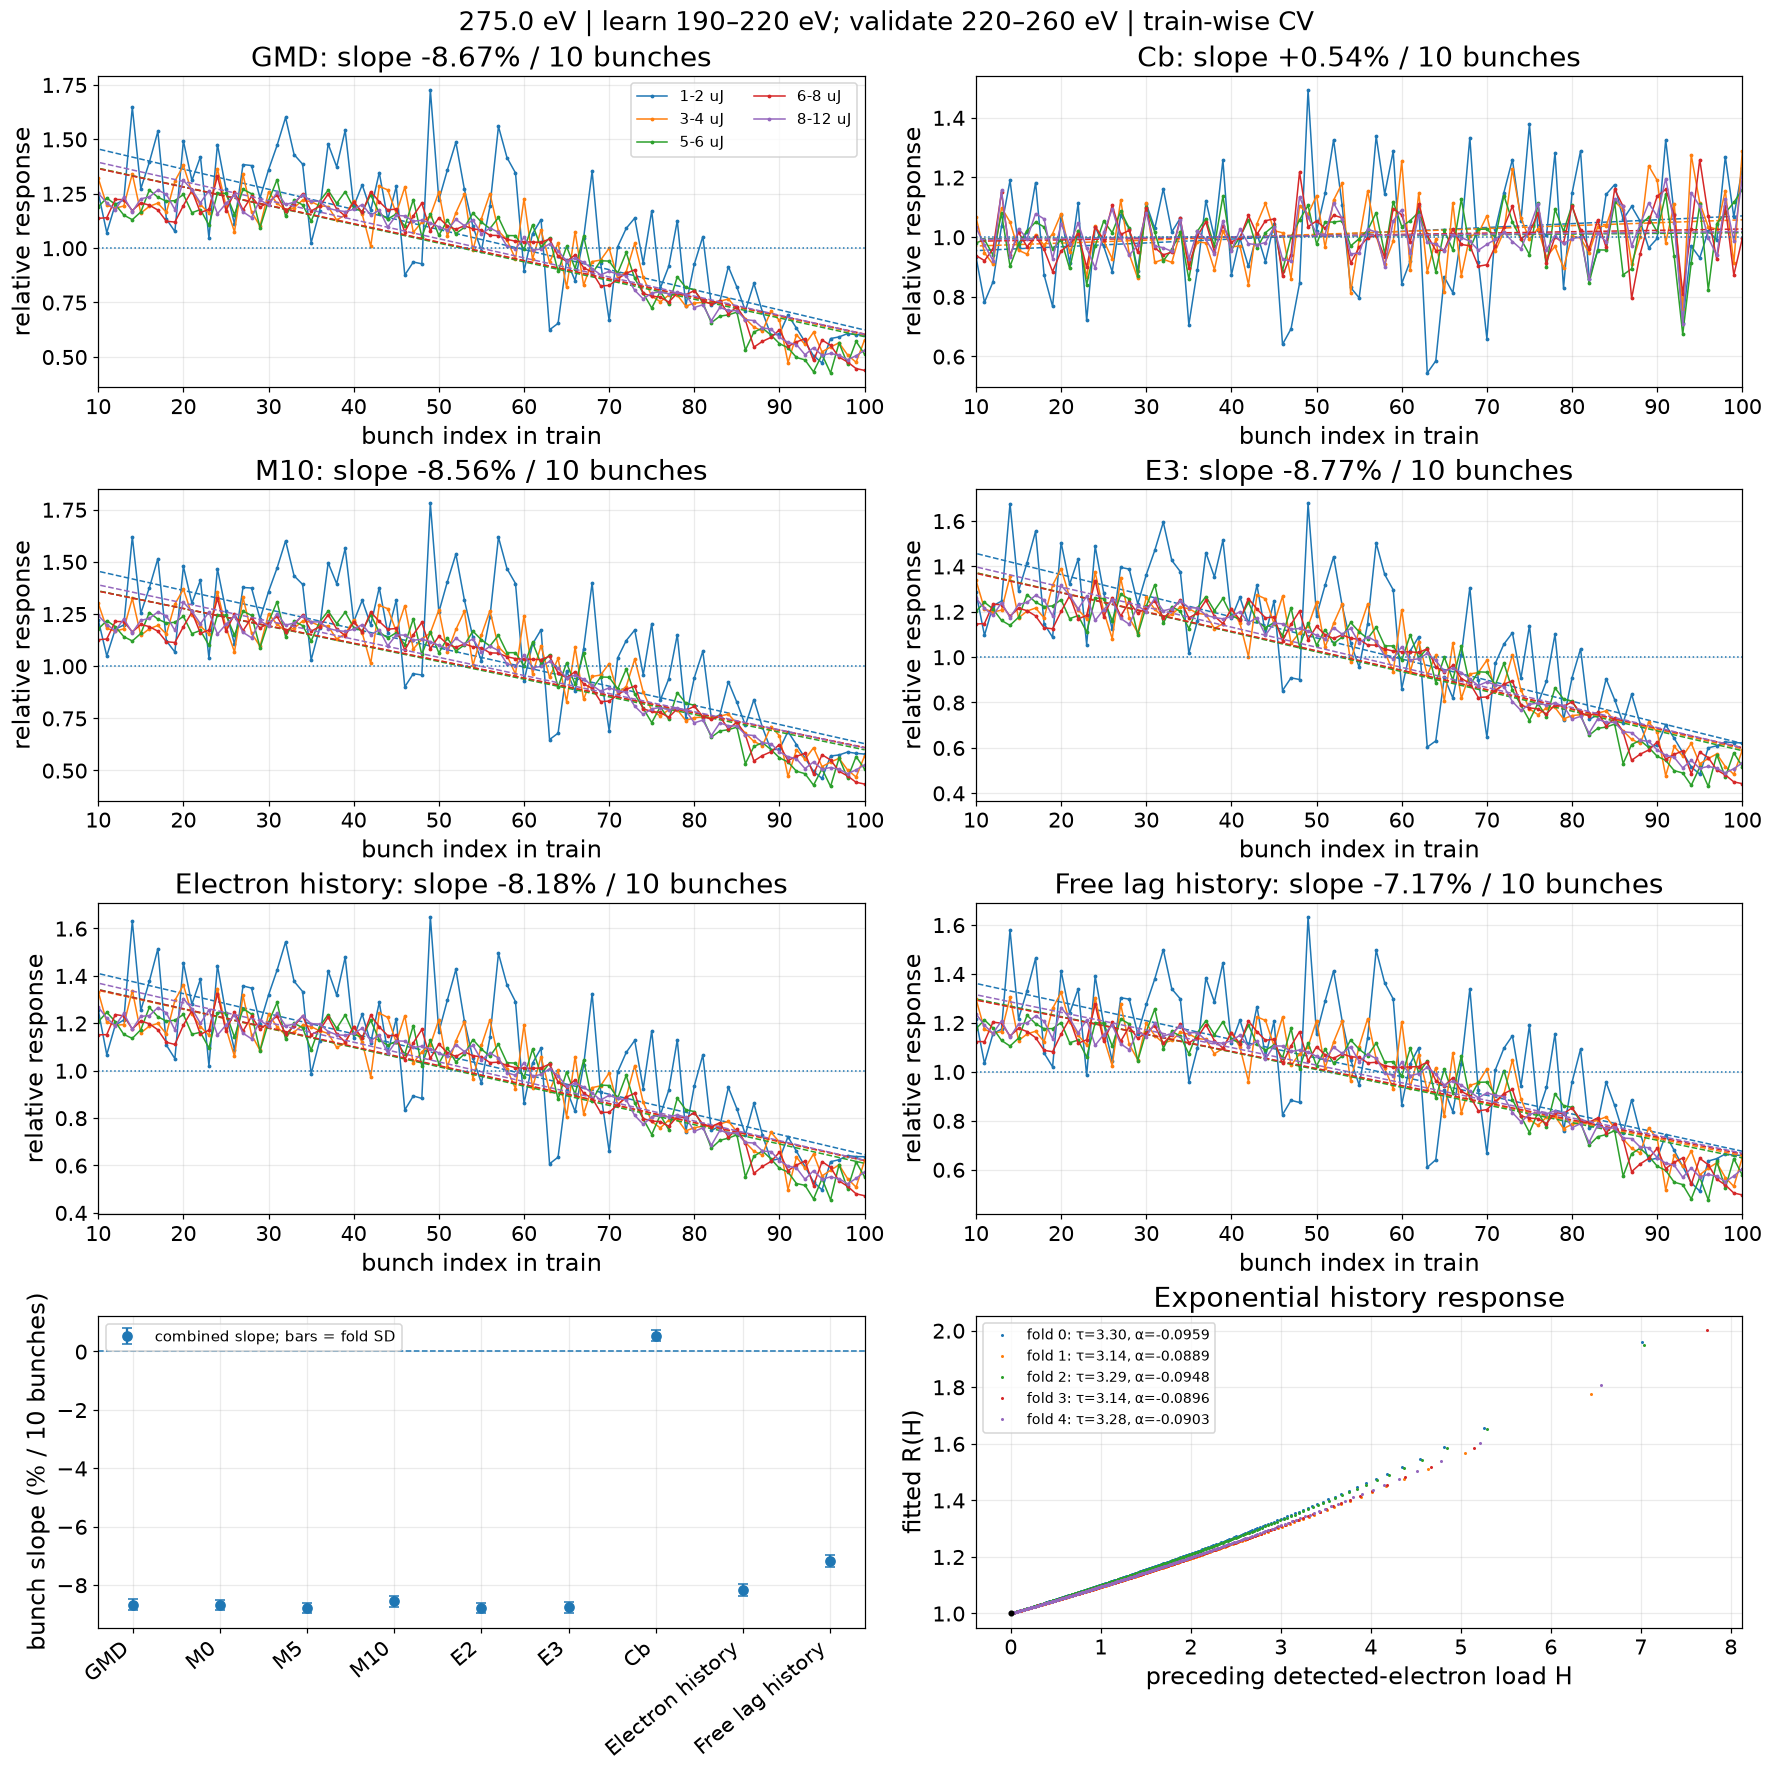


Free lag history (MAX_LAG=100, ridge=10), held-out target:
fold 0: flatness 0.26772 -> 0.23118; slope -8.453 -> -6.949% / 10 bunches
fold 1: flatness 0.28109 -> 0.24567; slope -8.956 -> -7.474% / 10 bunches
fold 2: flatness 0.27838 -> 0.24219; slope -8.651 -> -7.144% / 10 bunches
fold 3: flatness 0.27403 -> 0.23789; slope -8.619 -> -7.089% / 10 bunches
fold 4: flatness 0.27758 -> 0.24188; slope -8.706 -> -7.225% / 10 bunches


In [ ]:
# One final table and comparison figure, with identical held-out shots for every method.
combined, fold_metrics = evaluate_held_out(data,designs,common,beta_cv,cb_folds,electron_fits,residual_cb_folds)

# Add the free linear lag-history model using the same held-out target shots.
combined["Free lag history"] = bunch_metrics(hold_target_kernel.sum(axis=0),hold_norm_kernel.sum(axis=0),hold_shots_kernel.sum(axis=0))
fold_metrics["Free lag history"] = [bunch_metrics(hold_target_kernel[off],hold_norm_kernel[off],hold_shots_kernel[off]) for off in INDEP_CV_OFFSETS]

# Remove the residual-Cb combination from this final presentation.
combined.pop("Electron history + Cb",None)
fold_metrics.pop("Electron history + Cb",None)

comparison_rows = []
slope0 = combined["GMD"]["slope"]
for name,m in combined.items():
    flat = np.array([f["flatness"] for f in fold_metrics[name]])
    slope = np.array([f["slope"] for f in fold_metrics[name]])
    comparison_rows.append({"method":name,"held-out flatness":m["flatness"],"slope (% / 10 bunches)":m["slope"],"|slope| reduction (%)":100*(1-abs(m["slope"])/abs(slope0)) if slope0 else np.nan,"fold flatness mean":flat.mean(),"fold flatness SD":flat.std(ddof=1),"fold slope mean":slope.mean(),"fold slope SD":slope.std(ddof=1)})

comparison_table = pd.DataFrame(comparison_rows).set_index("method")
display(comparison_table.round(5))
display(pd.DataFrame(electron_fits).rename_axis("training fold").round(6))

plot_names = ["GMD","Cb","M10","E3","Electron history","Free lag history"]
fig,axes = plt.subplots(4,2,figsize=(16,16),constrained_layout=True)

for ax,name in zip(axes.flat,plot_names):
    m = combined[name]
    plot_bunch_response(m,f"{name}: slope {m['slope']:+.2f}% / 10 bunches",ax)

axes[0,0].legend(ncol=2,fontsize=10)

ax = axes[3,0]
names = list(combined)
ax.errorbar(np.arange(len(names)),[combined[name]["slope"] for name in names],yerr=[comparison_table.loc[name,"fold slope SD"] for name in names],fmt="o",capsize=3,label="combined slope; bars = fold SD")
ax.axhline(0,ls="--",lw=1)
ax.set_xticks(np.arange(len(names)),names,rotation=40,ha="right")
ax.set_ylabel("bunch slope (% / 10 bunches)")
ax.grid(alpha=0.25)
ax.legend(fontsize=10)

ax = axes[3,1]
for off,fit in enumerate(electron_fits):
    rows = train_ids % INDEP_CV_MOD == off
    h = np.sort(electron_history(data["total_electrons"][rows],fit["tau"])[common[rows]])
    step = max(1,h.size//300)
    h_plot = h[::step]
    ax.plot(h_plot,np.exp(-fit["alpha"]*h_plot),".",ms=2,label=f"fold {off}: τ={fit['tau']:.2f}, α={fit['alpha']:.3g}")

ax.plot(0,1,"ko",ms=3)
ax.set_xlabel("preceding detected-electron load H")
ax.set_ylabel("fitted R(H)")
ax.set_title("Exponential history response")
ax.grid(alpha=0.25)
ax.legend(fontsize=9)

fig.suptitle(f"{ANALYSIS_PHOTON_ENERGY_EV:.1f} eV | learn 190–220 eV; validate 220–260 eV | train-wise CV")
plt.show()

print(f"\nFree lag history (MAX_LAG={MAX_LAG}, ridge={best_ridge:g}), held-out target:")
for off in INDEP_CV_OFFSETS:
    g = fold_metrics["GMD"][off]
    k = fold_metrics["Free lag history"][off]
    print(f"fold {off}: flatness {g['flatness']:.5f} -> {k['flatness']:.5f}; slope {g['slope']:+.3f} -> {k['slope']:+.3f}% / 10 bunches")